In [1]:
import scipy.cluster.hierarchy as sch
import matplotlib.patches as mpatches
import math
import seaborn as sns
from matplotlib import pyplot as plt
import os
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None
#os.chdir('/Users/daniel.garger/Desktop/Projects/C-PATH')
os.chdir(os.getcwd())
print(os.getcwd())
import itertools
from sklearn.preprocessing import MinMaxScaler, StandardScaler

/Users/daniel.garger/Desktop/Projects/C-PATH/outcome prediction/src


In [10]:
# load necessary dataframes and study+pat_id data
dir = 'TTP prediction/'
therapy_durations = pd.read_excel('../../C-Path_data/preprocessing/Therapy_durations.xlsx', index_col=0)
#pat_id_df = pd.read_csv(dir+'data/patients_in_analysis.csv', index_col=0)
pat_id_df = pd.read_csv('../data/patients_in_analysis.csv.gz', index_col=0)
mb = pd.read_csv('../../C-Path_data/fullExportDb-1025-Member-CSV/mb_with_results_days_arms.csv', low_memory=False)
dm = pd.read_csv('../../C-Path_data/fullExportDb-1025-Member-CSV/dm.csv', low_memory=False)
pc = pd.read_csv('../../TTP prediction/data/ttp_pc_preprocessed.csv', low_memory=False)
mb_oc = pd.read_csv('../../C-Path_data/preprocessing/mb_outcome.csv', low_memory=False)
xo = pd.read_csv('../../C-Path_data/fullExportDb-1025-Member-CSV/xo.csv', low_memory=False)
studies = pat_id_df['STUDYID'].unique()
pat_ids = pat_id_df['USUBJID'].values.tolist()
ds=pd.read_csv('../../C-path_data/fullExportDb-1025-Member-CSV/ds.csv',low_memory=False)


In [19]:
xo['XOTEST'].value_counts()
outcome_df=xo[xo['XOTEST'].str.contains('Primary Efficacy Results|Efficacy Results',na=False)]

<hr>

##### **DROP FALSE POSITIVES TTP MEASUREMENTS OF TB-1021 & TB-1018 STUDIES FROM THE MB DATABASE**
* ##### THIS IS MEASURED BY A BLOOD AGAR CULTURE VALIDATION AFTER THE MGIT SIGNALS POSITIVE, 
* ##### IF THE BLOOD-AGAR CULTURE GROWS A NON-MTB BACTERIUM, THE TTP WAS FALSE POSITIVE

In [20]:
mb = mb[mb['MBSTAT'] != 'NOT DONE']
## Create unique sample reference ID by concatenating Patient ID + Microbiological Reference ID of the sample
mb['SAMPLE_REFID'] = np.nan
mb.loc[~mb['MBREFID'].isna(), 'SAMPLE_REFID'] = mb.loc[~mb['MBREFID'].isna(), 'STUDYID'].astype(str) + \
    '_'+mb.loc[~mb['MBREFID'].isna(), 'MBREFID'].astype(str)

## Extract Sample IDs of false positive samples
false_pos_ttp_ids = mb[(mb['MBTESTCD'] == 'NONMTB') & (
    mb['MBSTRESC'] != 'NEGATIVE (MGIT RESULT VALID)')]['SAMPLE_REFID']
false_pos_ttp_ids = false_pos_ttp_ids.dropna()

## Extract index of false positive MGIT measurements
false_pos_ttp_index = mb[(mb['SAMPLE_REFID'].isin(false_pos_ttp_ids)) &
                         (mb['MBTSTDTL'].str.contains('Time to Detection', na=False))].index

## Drop false positive MGIT measurements
mb_clean = mb.loc[~mb.index.isin(false_pos_ttp_index), :]


#####    __Extract 2 types of test modalities from mb results:__
* #####    1. Extract results measured by Time to Detection (DAYS) + calculate log10 of DAYS and add as column --> **save it as "mb_ttd"**

* #####    2. Extract results measured by Colony Count--> calculate log10 of CFU/mL where necessary --> replace CFU/mL with log10 CFU/mL  --> **save it as "mb_cfu_ml"**


In [21]:
# get mb results with Time to Detection (DAYS) results

mb_ttd = mb_clean[(mb_clean['MBTSTDTL'].str.contains(
    'Time to Detection', na=False))]
mb_ttd['TTP(DAYS)'] = mb_ttd['MBSTRESN']


# set values more than 42 days as negative
mb_ttd_negative = mb_ttd[(mb_ttd['MBSTRESC'].str.contains(
    '>|NO GROWTH|NEGATIVE')) | (mb_ttd['MBSTRESN'] > 42)]
mb_ttd.loc[mb_ttd_negative.index, 'TTP(DAYS)'] = 42
mb_ttd = mb_ttd[~mb_ttd['TTP(DAYS)'].isna()]

# get logarithm of values
mb_ttd.loc[:, 'TTP(log10_DAYS)'] = np.log10(mb_ttd['TTP(DAYS)']+1)

# invert TTP values -> create log10(42)-log10_DAYS --> 0 means low bacterial burden, high number means high burden
mb_ttd['1-TTP(log10_DAYS)'] = np.log10(43)-mb_ttd['TTP(log10_DAYS)']


# add arm and phase information
mb_ttd['ARM'] = np.nan
mb_ttd['PHASE'] = np.nan
for pat in mb_ttd['USUBJID'].unique():
    # print(pat_id_df.loc[pat_id_df['USUBJID']==pat,'ARM'])
    if pat in pat_id_df['USUBJID'].unique():
        mb_ttd.loc[mb_ttd['USUBJID'] == pat,
                   'ARM'] = pat_id_df.loc[pat_id_df['USUBJID'] == pat, 'ARM'].to_list()[0]
        #mb_ttd.loc[mb_ttd['USUBJID'] == pat,
        #           'PHASE'] = pat_id_df.loc[pat_id_df['USUBJID'] == pat, 'PHASE'].to_list()[0]


# get mb results with Colony Count (CFU/ml)results
# get logarithm of CFU/ml values
mb2 = mb_clean[mb_clean['MBTSTDTL'] == 'Colony Count']
#mb_cfu_ml=mb[(mb['MBSTRESU'].str.contains('CFU/mL|log10 CFU/mL',na=False))&(mb['MBTSTDTL']=='Colony Count')]
mb_cfu_ml = mb2[mb2['MBSTRESU'].str.contains('CFU/mL|log10 CFU/mL', na=False)]

mb_cfu_ml['CFU/mL'] = mb_cfu_ml['MBSTRESN']
d = mb_cfu_ml[(mb_cfu_ml['MBSTRESU'] == 'log10 CFU/mL')]
mb_cfu_ml.loc[d.index, 'CFU/mL'] = 10**d.loc[:, 'MBSTRESN']

# add arm and phase information
mb_cfu_ml['ARM'] = np.nan
mb_cfu_ml['PHASE'] = np.nan
for pat in mb_cfu_ml['USUBJID'].unique():
    # print(pat_id_df.loc[pat_id_df['USUBJID']==pat,'ARM'])
    if pat in pat_id_df['USUBJID'].unique():
        mb_cfu_ml.loc[mb_cfu_ml['USUBJID'] == pat,
                      'ARM'] = pat_id_df.loc[pat_id_df['USUBJID'] == pat, 'ARM'].to_list()[0]
       # mb_cfu_ml.loc[mb_cfu_ml['USUBJID'] == pat,
       #               'PHASE'] = pat_id_df.loc[pat_id_df['USUBJID'] == pat, 'PHASE'].to_list()[0]


<hr>

* #### Collect all the microbiological measurements for each sample from the patients with MGIT data in one dataframe
* #### If there are multiple numerical measurements from one day, get the average of them

In [18]:
# DROP UNNECESSARY MEASUREMENTS
# Drop Acid Fast Bacilli (Ziehl-Neelsen smear microscopy) measurements, as they are not reliable
mb_clean = mb_clean[~mb_clean['MBTEST'].str.contains('ACID|Acid', na=False)]

# Subset the dataframe to only relevant columns of patients with MGT TTP measurements
mb_clean_mgit = mb_clean[mb_clean['USUBJID'].isin(pat_ids)]
colnames = ['STUDYID', 'USUBJID', 'SAMPLE_REFID', 'MBDY', 'MBTESTCD', 'MBTSTDTL',
            'MBSTRESC', 'MBSTRESN', 'MBSTRESU', 'MBMETHOD', 'MEDIATYP', 'SPDEVID']
mb_clean_mgit = mb_clean_mgit.loc[:, colnames]

# Drop the MGIT validation culture results for TB-1021&TB-1018, as they are only there to confirm that the MGIT was containing TB
# already dropped the false positive MGIT results, so there is no additional information keeping them
mb_clean_mgit = mb_clean_mgit[mb_clean_mgit['MBTESTCD'] != 'NONMTB']


# Dropping all the MCORGIDN (=identification of Tuberculosis species)maesurements, because:
# 1. In some samples non-TB Mycobacterium species were identified
#    -> although more samples were taken on one day, these samples have their own sample ID,
#    so not really clear if all of the other samples from that day are non-TB, or there is just co-infection/contamination?

# 2. In samples, where M.Tuberculosis was confirmed, the information (M.tb. yes/no) is already contained in the results
#    taken from the same day -> this information is redundant

drop_idx = mb_clean_mgit[(mb_clean_mgit['MBTESTCD']
                          == 'MCORGIDN')].index  # & \
#      (~mb_clean_mgit['MBSTRESC'].isin(['NEGATIVE','MYCOBACTERIUM TUBERCULOSIS','POSITIVE FOR M. TUBERCULOSIS COMPLEX']))].index
mb_clean_mgit = mb_clean_mgit.loc[~mb_clean_mgit.index.isin(drop_idx), :]

# Drop measurements where the Colony Count is 'CU' -> maybe for Count Unknown?
mb_clean_mgit = mb_clean_mgit[mb_clean_mgit['MBSTRESC'] != 'CU']

# ------------------
# Add arm and clinical trial phase information to dataframe
mb_clean_mgit['ARM'] = np.nan
#mb_clean_mgit['PHASE'] = np.nan

for arm in pat_id_df['ARM'].unique():
    arm_pat_idx = pat_id_df.loc[pat_id_df['ARM'] == arm, 'USUBJID'].tolist()
    mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(
        arm_pat_idx), 'ARM'] = pat_id_df.loc[pat_id_df['ARM'] == arm, 'ARM'].to_list()[0]

#for phase in pat_id_df['PHASE'].unique():
#    phase_pat_idx = pat_id_df.loc[pat_id_df['PHASE']
#                                  == phase, 'USUBJID'].tolist()
#    mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(
#        phase_pat_idx), 'PHASE'] = pat_id_df.loc[pat_id_df['PHASE'] == phase, 'PHASE'].to_list()[0]

# ------------------
# Add TTP(DAYS) information to original mb_mgit_clean dataset
# Add a seperate column for MGIT results (TTP(DAYS)
mb_clean_mgit['TTP(DAYS)'] = np.nan
mb_ttd = mb_clean_mgit[(mb_clean_mgit['MBTSTDTL'].str.contains(
    'Time to Detection', na=False))]
mb_ttd['TTP(DAYS)'] = mb_ttd['MBSTRESN']

# Set values more than 42 days as negative
mb_ttd_negative = mb_ttd[(mb_ttd['MBSTRESC'].str.contains(
    '>|NO GROWTH|NEGATIVE')) | (mb_ttd['MBSTRESN'] > 42)]
mb_ttd.loc[mb_ttd_negative.index, 'TTP(DAYS)'] = 43
mb_ttd = mb_ttd[~mb_ttd['TTP(DAYS)'].isna()]

# Add TTP(DAYS) information to original mb_mgit_clean dataset
mb_clean_mgit.loc[mb_ttd.index, 'TTP(DAYS)'] = mb_ttd['TTP(DAYS)']

# ------------------
# Add CFU/ml information to mb_mgit_clean dataset
# Add a seperate column for Colony Count (CFU/ml)results
mb_clean_mgit['CFU/mL'] = np.nan

# Extract CFU/ml results along with log 10 CFU/ml
mb2 = mb_clean_mgit[mb_clean_mgit['MBTSTDTL'] == 'Colony Count']
mb_cfu_ml = mb2[mb2['MBSTRESU'].str.contains('CFU/mL|log10 CFU/mL', na=False)]
mb_cfu_ml['CFU/mL'] = mb_cfu_ml['MBSTRESN']

# Convert log10 CFU/ml to CFU/ml
d = mb_cfu_ml[(mb_cfu_ml['MBSTRESU'] == 'log10 CFU/mL')]
mb_cfu_ml.loc[d.index, 'CFU/mL'] = 10**d.loc[:, 'MBSTRESN']

# Add CFU/ml information to original mb_mgit_clean dataset
mb_clean_mgit.loc[mb_cfu_ml.index, 'CFU/mL'] = mb_cfu_ml['CFU/mL']
mb_clean_mgit['log10_CFU/mL'] = np.log10(mb_clean_mgit['CFU/mL']+1)

# ------------------
# ADD A SEPERATE COLUMN TO COLLECT IF THE GIVEN SAMPLE (!!!!!) WAS NEGATIVE ON A SOLID MEDIUM OR POSITIVE
# Add negative on solid medium information where microbiological test resulted in categorical variables
categorical_vars = ['Colony Count, Categorical', 'Culture Growth']
negative_result_vars = ['NO GROWTH', 'NEGATIVE']
mb_clean_mgit['SOLID_MEDIUM_RESULT'] = np.nan
mb_clean_mgit.loc[((mb_clean_mgit['MBTSTDTL'].isin(categorical_vars)) &
                   (mb_clean_mgit['MBSTRESC'].isin(negative_result_vars))), 'SOLID_MEDIUM_RESULT'] = 'negative'

mb_clean_mgit.loc[((mb_clean_mgit['MBTSTDTL'].isin(categorical_vars)) &
                   (~mb_clean_mgit['MBSTRESC'].isin(negative_result_vars))), 'SOLID_MEDIUM_RESULT'] = 'positive'

# Add negative on solid medium information where microbiological test resulted in colony count
mb_clean_mgit.loc[((mb_clean_mgit['MBTSTDTL'] == 'Colony Count') &
                   (mb_clean_mgit['log10_CFU/mL'] == 0)), 'SOLID_MEDIUM_RESULT'] = 'negative'
mb_clean_mgit.loc[((mb_clean_mgit['MBTSTDTL'] == 'Colony Count') &
                   (mb_clean_mgit['log10_CFU/mL'] != 0)), 'SOLID_MEDIUM_RESULT'] = 'positive'


# ------------------
# ADD A SEPERATE COLUMN TO COLLECT IF THE SAMPLES FROM THE !DAY! THEY WERE TAKEN WAS NEGATIVE ON A SOLID MEDIUM OR POSITIVE
mb_clean_mgit['SOLID_MEDIUM_SUMM_RESULT'] = np.nan

# Iterate through the samples, and get the mode of the SOLID_MEDIUM_RESULT column
for sample_refid in mb_clean_mgit['SAMPLE_REFID'].unique():
    sample_df = mb_clean_mgit[mb_clean_mgit['SAMPLE_REFID'] == sample_refid]
    if not all(sample_df['SOLID_MEDIUM_RESULT'].isna()):
        # Take the mode of the solid cultures taken from that day (positive/negative) and then
        # add that to the SOLID_MEDIUM_SUMM_RESULT column
        mode_df = sample_df['SOLID_MEDIUM_RESULT'].mode()
        if len(mode_df) == 1:
            mode = mode_df.values[0]
        # If multiple solid cultures taken on one day and even one of them is positive (mode is not one variable, but 2),
        # then SOLID_MEDIUM_SUMM_RESULT=='positive' for that day
        if len(mode_df) > 1:
            mode = 'positive'
        mb_clean_mgit.loc[sample_df.index, 'SOLID_MEDIUM_SUMM_RESULT'] = mode

# ------------------
 # EXTRACT ENDPOINTS OUT OF XO DATASET FOR 3 PHASE III TRIALS (TB-1020-21-22)
# Consider the primary efficacy endpoint (favourable vs. unfavourable).
# Consider the  Per Protocol approach (thre is also option 'Modified intention to treat' (MITT) approach)
'''
In a "per protocol" analysis of a clinical study, only data from patients who completed the study and followed 
the protocol as intended are included in the analysis. This approach is used to evaluate the true effectiveness 
of a treatment, as it eliminates the potential confounding effects of patients who did not follow the protocol.
In a "modified intention to treat" (ITT) analysis, data from all patients who were initially enrolled in the study,
regardless of whether they completed the study or followed the protocol, are included in the analysis. This approach
is used to evaluate the effectiveness of a treatment in a real-world setting, where patients may not always follow 
the protocol as intended.In summary, per protocol analysis is a more stringent analysis that only looks at a subpopulation
of patients who completed the study as intended. Modified intention to treat analysis looks at all patients who were 
initially enrolled in the study regardless of their adherence to the protocol.
'''
# TB-1020: 18 Months
# TB-1021: 18 Months
# TB-1022: 24 Months

# TB-1021: Consider the efficacy timepoints based on liquid culture, (there is also information on Eff. Timepoints based on solid culture)
outcome_df[outcome_df['XOCAT'] =='MODIFIED INTENT TO TREAT']['USUBJID'].value_counts()
outcome_tb1021 = outcome_df[(outcome_df['STUDYID'] == 'TB-1021') & (outcome_df['XOCAT'] == 'PER PROTCOL') &
                            (outcome_df['XOMETHOD'].str.contains('LIQUID'))]

# TB-1020: No information on which medium the endpoints were determined on -> extract Eff. Timepoints with PP approach
outcome_tb1020 = outcome_df[(outcome_df['STUDYID'].isin(['TB-1020'])) & (outcome_df['XOCAT'] == 'PER PROTOCOL')]

# TB-1022: No information on which medium the endpoints were determined nor on which approach (MITT vs Per protocol) was used 
outcome_tb1022 = outcome_df[(outcome_df['STUDYID'].isin(['TB-1022']))]                      

# Create lists if pat IDs with favourable/unfavourable outcomes
pat_ids_favourable_1021 = outcome_tb1021[outcome_tb1021['XOSTRESC']== 'FAVOURABLE']['USUBJID'].unique()
pat_ids_unfavourable_1021= outcome_tb1021[outcome_tb1021['XOSTRESC']== 'UNFAVOURABLE']['USUBJID'].unique()

pat_ids_favourable_1020=outcome_tb1020[outcome_tb1020['XOSTRESC']=='FAVOURABLE']['USUBJID'].unique()
pat_ids_favourable_1022=outcome_tb1022[outcome_tb1022['XOSTRESC']=='FAVOURABLE']['USUBJID'].unique()

pat_ids_unfavourable_1020=outcome_tb1020[outcome_tb1020['XOSTRESC']=='UNFAVOURABLE']['USUBJID'].unique()
pat_ids_unfavourable_1022=outcome_tb1022[outcome_tb1022['XOSTRESC']=='NOT FAVOURABLE']['USUBJID'].unique()

# Concatenate the 3 lists
pat_ids_favourable = list(itertools.chain(pat_ids_favourable_1020,pat_ids_favourable_1021,pat_ids_favourable_1022))
pat_ids_unfavourable = list(itertools.chain(pat_ids_unfavourable_1020,pat_ids_unfavourable_1021,pat_ids_unfavourable_1022))

# Add outcome information to OUTCOME column
mb_clean_mgit['OUTCOME'] = np.nan
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_favourable), 'OUTCOME'] = 'FAVOURABLE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_unfavourable), 'OUTCOME'] = 'UNFAVOURABLE'


# ------------------
# EXTRACT TREATMENT FAILURE/RELAPSE/LATE DISCOVERY OF DRUG RESISTANCE OUT OF XO DATASET FOR 1 PHASE III TRIAL (TB-1021)
ds_1021=ds[ds['STUDYID']=='TB-1021']
pat_ids_relapse=ds_1021.loc[ds_1021['DSDECOD'].str.contains('RELAPSE',na=False),'USUBJID'].unique().tolist()
pat_ids_treatment_failure=ds_1021.loc[ds_1021['DSDECOD'].str.contains('FAILURE',na=False),'USUBJID'].unique().tolist()
pat_ids_resistance=ds_1021.loc[ds_1021['DSDECOD'].str.contains('DRUG RESISTANT TB',na=False),'USUBJID'].unique().tolist()

# Add this information to UNFAVOURABLE_OUTCOME_CATEGORY column
#mb_clean_mgit['UNFAVOURABLE_OUTCOME_CATEGORY'] = np.nan

mb_clean_mgit.loc[mb_clean_mgit['OUTCOME']=='FAVOURABLE','UNFAVOURABLE_OUTCOME_CATEGORY'] = 'FAVOURABLE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_relapse), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'RELAPSE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_treatment_failure), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'TREATMENT FAILURE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_resistance), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'LATE DRUG RESISTANCE'


# ------------------
# EXTRACT RESULTS OF MGIT AND SOLID CULTURE FROM SAME DAY SAMPLES, COMPARE THEM AND ADD THAT INFO TO 'MB_RESULT' COLUMN ->
# ISOLATED POSITIVITY IN ONE OF THE METHODS, OR BOTH NEGATIVE OR BOTH POSITIVE
mb_clean_mgit['MB_RESULT'] = np.nan
mb_clean_mgit.loc[(mb_clean_mgit['TTP(DAYS)'] < 43) & (
    mb_clean_mgit['SOLID_MEDIUM_SUMM_RESULT'] == 'negative'), 'MB_RESULT'] = 'isolated MGIT positive'
mb_clean_mgit.loc[(mb_clean_mgit['TTP(DAYS)'] == 43) & (
    mb_clean_mgit['SOLID_MEDIUM_SUMM_RESULT'] == 'positive'), 'MB_RESULT'] = 'isolated solid culture positive'
mb_clean_mgit.loc[(mb_clean_mgit['TTP(DAYS)'] < 43) & (
    mb_clean_mgit['SOLID_MEDIUM_SUMM_RESULT'] == 'positive'), 'MB_RESULT'] = 'solid culture & MGIT positive'
mb_clean_mgit.loc[(mb_clean_mgit['TTP(DAYS)'] == 43) & (
    mb_clean_mgit['SOLID_MEDIUM_SUMM_RESULT'] == 'negative'), 'MB_RESULT'] = 'solid culture & MGIT negative'

# ------------------
# CATEGORIZE MGIT RESULTS INTO 3 CATEGORIES BASED ON THE TTP DAYS
mb_clean_mgit['TTP_CATEGORY']=np.nan
# Where the result is not isolated MGIT positive, add the MB_RESULT values to TTP_CATEGORIES column 
# (i.e.isolated solid culture positive,solid culture & MGIT negative )
mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT'] != 'isolated MGIT positive','TTP_CATEGORY'] = mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT'] != 'isolated MGIT positive','MB_RESULT']
category_cutoffs=[0,5,15,42]
category_labels=['isolated MGIT pos.- '+str(category_cutoffs[x])+'-'+str(category_cutoffs[x+1])+'days' for x in range(len(category_cutoffs[:-1]))]
mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT']== 'isolated MGIT positive','TTP_CATEGORY']=pd.cut(mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT']== 'isolated MGIT positive','TTP(DAYS)'],
                                                                                             bins=category_cutoffs,labels=category_labels,right=True)

# ------------------
# ADD THERAPY DURATION AS A SEPERATE COLUMN
mb_clean_mgit['THERAPY_DURATION'] = np.nan
for arm in therapy_durations['Arm']:
    mb_clean_mgit.loc[mb_clean_mgit['ARM'] == arm,
                      'THERAPY_DURATION'] = therapy_durations.loc[therapy_durations['Arm'] == arm, 'stop_day'].to_list()[0]

# ------------------
# ADD STUDYID BEFORE ARM TO MAKE SURE ARM IS UNIQUE FOR STUDY
mb_clean_mgit['STUDYID_ARM'] = np.nan

for arm in mb_clean_mgit['ARM'].unique():
    d = mb_clean_mgit[mb_clean_mgit['ARM'] == arm]
    mb_clean_mgit.loc[d.index, 'STUDYID_ARM'] = str(
        d['STUDYID'].values[0])+'_'+str(d['ARM'].values[0])

# ------------------
# ADD THERAPY WEEK TO DATAFRAME
mb_clean_mgit['THERAPY_WEEK'] = [math.ceil(x/7) for x in mb_clean_mgit['MBDY']]


NameError: name 'mb_clean' is not defined

In [368]:
mb_clean_mgit.to_csv('../data/mb_paired_liquid_solid_media_results.csv.gz',compression='gzip')

In [6]:
mb_clean_mgit=pd.read_csv('../data/mb_paired_liquid_solid_media_results.csv.gz',index_col=0)
mb_clean_mgit.loc[~mb_clean_mgit['MB_RESULT'].isna(),:]

,STUDYID,USUBJID,SAMPLE_REFID,MBDY,MBTESTCD,MBTSTDTL,MBSTRESC,MBSTRESN,MBSTRESU,MBMETHOD,...,log10_CFU/mL,SOLID_MEDIUM_RESULT,SOLID_MEDIUM_SUMM_RESULT,OUTCOME,UNFAVOURABLE_OUTCOME_CATEGORY,MB_RESULT,TTP_CATEGORY,THERAPY_DURATION,STUDYID_ARM,THERAPY_WEEK
5,TB-1021,TB-1021/1098684,TB-1021_200156,1.0,MTB,Time to Detection,>42,NaN,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,negative,NaN,NaN,solid culture & MGIT negative,solid culture & MGIT negative,182.0,TB-1021_2EMRZ/2MR,1
6,TB-1021,TB-1021/1098908,TB-1021_200157,1.0,MTB,Time to Detection,>42,NaN,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,negative,NaN,NaN,solid culture & MGIT negative,solid culture & MGIT negative,182.0,TB-1021_2EMRZ/2MR,1
8,TB-1021,TB-1021/1093230,TB-1021_200335,-5.0,MTB,Time to Detection,4.542,4.542,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,NaN,TREATMENT FAILURE,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1021_2EMRZ/2MR,0
10,TB-1021,TB-1021/1089568,TB-1021_200174,50.0,MTB,Time to Detection,23.083,23.083,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,negative,NaN,LATE DRUG RESISTANCE,isolated MGIT positive,isolated MGIT pos.- 15-42days,182.0,TB-1021_2EMRZ/2MR,8
15,TB-1021,TB-1021/2722385,TB-1021_1301112,15.0,MTB,Time to Detection,12.208,12.208,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,FAVOURABLE,FAVOURABLE,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1021_2EMRZ/2MR,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425968,TB-1018,TB-1018/02-9068,TB-1018_NIX-1475,1.0,MTB,Time to Detection,7.708,7.708,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,NaN,NaN,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1018_Bedaquiline - Linezolid - Pretomanid,1
425973,TB-1018,TB-1018/04-9002,TB-1018_DNIX-0002,-7.0,MTB,Time to Detection,29.667,29.667,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,NaN,NaN,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1018_Bedaquiline - Linezolid - Pretomanid,-1
425992,TB-1018,TB-1018/04-9003,TB-1018_DNIX-0003,-3.0,MTB,Time to Detection,6.875,6.875,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,NaN,NaN,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1018_Bedaquiline - Linezolid - Pretomanid,0
425998,TB-1018,TB-1018/02-9034,TB-1018_NIX-0556,-8.0,MTB,Time to Detection,5.375,5.375,DAYS,"MICROBIAL CULTURE, LIQUID",...,NaN,NaN,positive,NaN,NaN,solid culture & MGIT positive,solid culture & MGIT positive,182.0,TB-1018_Bedaquiline - Linezolid - Pretomanid,-1


In [3]:
mb_clean_=pd.read_csv('../data/out_mb_wo_false_positives.csv.gz',index_col=0)

/var/folders/0_/_m74rlq93855zphvhkg3qkhh19_hwl/T/ipykernel_19275/3119336017.py:1: DtypeWarning: Columns (4,6,7,8,9,13,15,18,19,23,24,25,27,28,31,32,33,34,38,39,41,42,43,44,45,48,50,52,53) have mixed types. Specify dtype option on import or set low_memory=False.
  mb_clean_=pd.read_csv('../data/out_mb_wo_false_positives.csv.gz',index_col=0)


In [4]:
mb_clean_[mb_clean_['SAMPLE_REFID'].isin(mb_clean_mgit['SAMPLE_REFID'])]['MBTSTDTL'].unique()

array(['Culture Growth', 'Colony Count, Categorical', 'Time to Detection',
       'Colony Count', 'Identification', 'Categorical Count', 'Unknown',
       'MPT64 Antigen Test', 'Minimum Cycle Threshold of Detection'],
      dtype=object)

In [68]:
print(mb_clean_.shape,mb_clean_mgit.shape)

(466181, 54) (129145, 30)


In [66]:
mb_clean_mgit['MB_RESULT']

2                                   NaN
3                                   NaN
4                                   NaN
5         solid culture & MGIT negative
6         solid culture & MGIT negative
                      ...              
426021                              NaN
426022                              NaN
426027                              NaN
426028                              NaN
426031                              NaN
Name: MB_RESULT, Length: 129145, dtype: object

### CHECK THIS LATER!

In [5]:
mb_clean_mgit = pd.read_csv('../data/mb_paired_liquid_solid_media_results.csv.gz', index_col=0, low_memory=False)

In [6]:
# ------------------
# CATEGORIZE MGIT RESULTS INTO 3 CATEGORIES BASED ON THE TTP DAYS
mb_clean_mgit['TTP_CATEGORY']=np.nan
# Where the result is not isolated MGIT positive, add the MB_RESULT values to TTP_CATEGORIES column 
# (i.e.isolated solid culture positive,solid culture & MGIT negative )
mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT'] != 'isolated MGIT positive','TTP_CATEGORY'] = mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT'] != 'isolated MGIT positive','MB_RESULT']
category_cutoffs=[0,5,15,42]
category_labels=['isolated MGIT pos.- '+str(category_cutoffs[x])+'-'+str(category_cutoffs[x+1])+'days' for x in range(len(category_cutoffs[:-1]))]
mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT']== 'isolated MGIT positive','TTP_CATEGORY']=pd.cut(mb_clean_mgit.loc[mb_clean_mgit['MB_RESULT']== 'isolated MGIT positive','TTP(DAYS)'],
                                                                                             bins=category_cutoffs,labels=category_labels,right=True)              

In [11]:
# ------------------
# EXTRACT TREATMENT FAILURE/RELAPSE/LATE DISCOVERY OF DRUG RESISTANCE OUT OF XO DATASET FOR 1 PHASE III TRIAL (TB-1021)
ds_1021=ds[ds['STUDYID']=='TB-1021']
pat_ids_relapse=ds_1021.loc[ds_1021['DSDECOD'].str.contains('RELAPSE',na=False),'USUBJID'].unique().tolist()
pat_ids_treatment_failure=ds_1021.loc[ds_1021['DSDECOD'].str.contains('FAILURE',na=False),'USUBJID'].unique().tolist()
pat_ids_resistance=ds_1021.loc[ds_1021['DSDECOD'].str.contains('DRUG RESISTANT TB',na=False),'USUBJID'].unique().tolist()

# Add this information to UNFAVOURABLE_OUTCOME_CATEGORY column
#mb_clean_mgit['UNFAVOURABLE_OUTCOME_CATEGORY'] = np.nan

mb_clean_mgit.loc[mb_clean_mgit['OUTCOME']=='FAVOURABLE','UNFAVOURABLE_OUTCOME_CATEGORY'] = 'FAVOURABLE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_relapse), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'RELAPSE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_treatment_failure), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'TREATMENT FAILURE'
mb_clean_mgit.loc[mb_clean_mgit['USUBJID'].isin(pat_ids_resistance), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'LATE DRUG RESISTANCE'

In [152]:
#mb_clean_mgit=mb_clean_mgit[~mb_clean_mgit['STUDYID'].isin(['TB-1020','TB-1018'])]

In [14]:
mb_clean_mgit['WEEKLY_TTP_MEDIAN']=np.nan 
mb_clean_mgit['scaled_TTP(DAYS)']=np.nan 
mb_clean_mgit['TTP(DAYS)_perc_rank']=np.nan

for arm in mb_clean_mgit['STUDYID_ARM'].unique():
  arm_df=mb_clean_mgit[mb_clean_mgit['STUDYID_ARM']==arm]
  for week in arm_df['THERAPY_WEEK']:
    week_df=arm_df[(arm_df['THERAPY_WEEK']==week)&(arm_df['MBTSTDTL'] == 'Time to Detection')]
    mb_clean_mgit.loc[week_df.index,'WEEKLY_TTP_MEDIAN']=week_df['TTP(DAYS)'].median()
    
    if len(week_df)>0:
      mb_clean_mgit.loc[week_df.index,'scaled_TTP(DAYS)']=StandardScaler().fit_transform(np.asarray(week_df['TTP(DAYS)']).reshape(-1,1))
      mb_clean_mgit.loc[week_df.index,'TTP(DAYS)_perc_rank']=mb_clean_mgit.loc[week_df.index,'TTP(DAYS)'].sort_values().rank(pct=True)

mb_clean_mgit['DIFFERENCE_FROM_MEDIAN']=mb_clean_mgit['TTP(DAYS)']-mb_clean_mgit['WEEKLY_TTP_MEDIAN']
mb_clean_mgit['DIFFERENCE_FROM_MEDIAN_WEIGHTED']=mb_clean_mgit['DIFFERENCE_FROM_MEDIAN']*mb_clean_mgit['WEEKLY_TTP_MEDIAN']

  

In [ ]:

for study in ['TB-1021','TB-1020','TB-1018']:
  fig,ax=plt.subplots(1,figsize=(20,20))
  plot_df=mb_clean_mgit[(mb_clean_mgit['STUDYID']==study)&(mb_clean_mgit['THERAPY_WEEK']<30)]
                      #&(mb_clean_mgit['MB_RESULT']=='isolated MGIT positive')]
  sns.lineplot(data=plot_df,x='THERAPY_WEEK',y='WEEKLY_TTP_MEDIAN',hue='ARM',ax=ax)#,inner='point')
  ax.set_title(study)

In [22]:
# TB-1021: Consider the efficacy timepoints based on liquid culture, (there is also information on Eff. Timepoints based on solid culture)
outcome_df[outcome_df['XOCAT'] =='MODIFIED INTENT TO TREAT']['USUBJID'].value_counts()
outcome_tb1021 = outcome_df[(outcome_df['STUDYID'] == 'TB-1021') & (outcome_df['XOCAT'] == 'PER PROTCOL') &
                            (outcome_df['XOMETHOD'].str.contains('LIQUID'))]

# TB-1020: No information on which medium the endpoints were determined on -> extract Eff. Timepoints with PP approach
outcome_tb1020 = outcome_df[(outcome_df['STUDYID'].isin(['TB-1020'])) & (outcome_df['XOCAT'] == 'PER PROTOCOL')]

# TB-1022: No information on which medium the endpoints were determined nor on which approach (MITT vs Per protocol) was used 
outcome_tb1022 = outcome_df[(outcome_df['STUDYID'].isin(['TB-1022']))]                      

# Create lists if pat IDs with favourable/unfavourable outcomes
pat_ids_favourable_1021 = outcome_tb1021[outcome_tb1021['XOSTRESC']== 'FAVOURABLE']['USUBJID'].unique()
pat_ids_unfavourable_1021= outcome_tb1021[outcome_tb1021['XOSTRESC']== 'UNFAVOURABLE']['USUBJID'].unique()

pat_ids_favourable_1020=outcome_tb1020[outcome_tb1020['XOSTRESC']=='FAVOURABLE']['USUBJID'].unique()
pat_ids_favourable_1022=outcome_tb1022[outcome_tb1022['XOSTRESC']=='FAVOURABLE']['USUBJID'].unique()

pat_ids_unfavourable_1020=outcome_tb1020[outcome_tb1020['XOSTRESC']=='UNFAVOURABLE']['USUBJID'].unique()
pat_ids_unfavourable_1022=outcome_tb1022[outcome_tb1022['XOSTRESC']=='NOT FAVOURABLE']['USUBJID'].unique()

# Concatenate the 3 lists
pat_ids_favourable = list(itertools.chain(pat_ids_favourable_1020,pat_ids_favourable_1021,pat_ids_favourable_1022))
pat_ids_unfavourable = list(itertools.chain(pat_ids_unfavourable_1020,pat_ids_unfavourable_1021,pat_ids_unfavourable_1022))

In [ ]:
import warnings
warnings.filterwarnings("ignore")

ttp_categories = ['0-42days', '0-5days', '5-15days', '15-42days']
isolated_ttp_pos_cumul_median_dict = {}
isolated_ttp_pos_diff_median_dict = {}

isolated_ttp_pos_cumul_median_weighted_dict = {}
isolated_ttp_pos_diff_median_weighted_dict = {}

isolated_ttp_pos_cumul_scaled_ttp_dict = {}
isolated_ttp_pos_diff_scaled_ttp_dict = {}

isolated_ttp_pos_cumul_percentile_ttp_dict = {}
isolated_ttp_pos_diff_percentile_ttp_dict = {}

diff_dicts=[isolated_ttp_pos_diff_median_dict,isolated_ttp_pos_diff_median_weighted_dict,
            isolated_ttp_pos_diff_scaled_ttp_dict,isolated_ttp_pos_diff_percentile_ttp_dict]

cumul_dicts=[isolated_ttp_pos_cumul_median_dict,isolated_ttp_pos_cumul_median_weighted_dict,
             isolated_ttp_pos_cumul_scaled_ttp_dict,isolated_ttp_pos_cumul_percentile_ttp_dict]

col_names=['DIFFERENCE_FROM_MEDIAN','DIFFERENCE_FROM_MEDIAN_WEIGHTED','scaled_TTP(DAYS)','TTP(DAYS)_perc_rank']

for diff_dict,cumul_dict,col_name in zip(diff_dicts,cumul_dicts,col_names):
    print(col_name)
    for ttp_cat in ttp_categories:
        # set up dataframe to collect the increase in isolated ttp positive measurement points between
        # day of therapy measurement timepoints

        isolated_ttp_pos_over_time_diff = pd.DataFrame(0, index=mb_clean_mgit['MBDY'].sort_values().unique(),
                                                    columns=mb_clean_mgit['USUBJID'].unique())

        # Select appropriate column name which holds TTP category information +
        # TTP category string name to select as isolated TTP category
        if ttp_cat == '0-42days':
            ttp_category_colname = 'MB_RESULT'
            ttp_category_string = 'isolated MGIT positive'
        if ttp_cat != '0-42days':
            ttp_category_colname = 'TTP_CATEGORY'
            ttp_category_string = 'isolated MGIT pos.- '+ttp_cat

        for n, day in enumerate(mb_clean_mgit['MBDY'].sort_values().unique()):
            d = mb_clean_mgit[mb_clean_mgit['MBDY'] == day]
            # Select which TTP Category to choose as isolated TTP positive
            df_ttp_pos = d[d[ttp_category_colname].str.contains(ttp_category_string, na=False)]
            ttp_pos_patients = df_ttp_pos['USUBJID'].unique()

            # If patient had isolated MGIT positive sample on that day, add the number of measurements to respective cell in the dataframe
            # If multiple  easurements from the same day -> average them
            if len(df_ttp_pos.loc[df_ttp_pos['USUBJID'].isin(ttp_pos_patients),:].groupby('USUBJID').apply(lambda x: x))>0:
                print('++++++++++')
                print(df_ttp_pos.loc[df_ttp_pos['USUBJID'].isin(ttp_pos_patients),:].groupby('USUBJID').apply(lambda x: x))
                print('===========')
                df_ttp_pos_unique_pat_ids=(df_ttp_pos.loc[df_ttp_pos['USUBJID'].isin(ttp_pos_patients),:].groupby('USUBJID').mean())
                print(df_ttp_pos_unique_pat_ids)
            df_ttp_pos_unique_pat_ids=(df_ttp_pos.loc[df_ttp_pos['USUBJID'].isin(ttp_pos_patients),:].groupby('USUBJID').mean())
            isolated_ttp_pos_over_time_diff.loc[day,ttp_pos_patients]=df_ttp_pos_unique_pat_ids.loc[ttp_pos_patients,col_name].values                            

        # get cumulative increase of numbers of isolated ttp positive samples
        isolated_ttp_pos_over_time_cumul = isolated_ttp_pos_over_time_diff.cumsum()

        for isol_ttp_df,isol_ttp_dict in zip([isolated_ttp_pos_over_time_diff,isolated_ttp_pos_over_time_cumul],
                                            [diff_dict,cumul_dict]):
            # Transpose cumulative patients datafarme in order to add ARM and PHASE column
            isol_ttp_df = isol_ttp_df.T

            temp_df = pat_id_df.set_index('USUBJID')
            temp_df = temp_df.reindex(isol_ttp_df.index)
            isol_ttp_df['ARM'] = temp_df['ARM']
            #isol_ttp_df['PHASE'] = temp_df['PHASE'].astype(str)

            # Add outcome information to dataframe where it is available
            isol_ttp_df['OUTCOME'] = np.nan
            isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_favourable), 'OUTCOME'] = 'FAVOURABLE'
            isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_unfavourable), 'OUTCOME'] = 'UNFAVOURABLE'

            # Add failure/relapse/late drug resistance information to dataframe where it is available
            isol_ttp_df['UNFAVOURABLE_OUTCOME_CATEGORY'] = np.nan
            isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_favourable), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'FAVOURABLE'
            isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_relapse), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'RELAPSE'
            isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_treatment_failure), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'TREATMENT FAILURE'
            #isolated_ttp_pos_over_time_cumul.loc[isolated_ttp_pos_over_time_cumul.index.isin(pat_ids_resistance), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'LATE DRUG RESISTANCE'

            isol_ttp_dict[ttp_cat] = isol_ttp_df

In [37]:
df_ttp_pos.loc[df_ttp_pos['USUBJID'].isin(ttp_pos_patients),:].groupby('USUBJID').apply(lambda x: x)

,STUDYID,USUBJID,SAMPLE_REFID,MBDY,MBTESTCD,MBTSTDTL,MBSTRESC,MBSTRESN,MBSTRESU,MBMETHOD,...,MB_RESULT,TTP_CATEGORY,THERAPY_DURATION,STUDYID_ARM,THERAPY_WEEK,WEEKLY_TTP_MEDIAN,scaled_TTP(DAYS),TTP(DAYS)_perc_rank,DIFFERENCE_FROM_MEDIAN,DIFFERENCE_FROM_MEDIAN_WEIGHTED
USUBJID,,,,,,,,,,,,,,,,,,,,,


In [35]:
isolated_ttp_pos_over_time_diff['TB-1021/1093230'][isolated_ttp_pos_over_time_diff['TB-1021/1093230']>0]

57.0    0.277778
Name: TB-1021/1093230, dtype: float64

In [27]:
isol_ttp_dict['0-42days']

,-736.0,-675.0,-619.0,-591.0,-584.0,-563.0,-535.0,-526.0,-475.0,-466.0,...,1526.0,1618.0,1688.0,1710.0,1800.0,1890.0,2134.0,ARM,OUTCOME,UNFAVOURABLE_OUTCOME_CATEGORY
TB-1021/1098684,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.075972,0.075972,0.075972,0.075972,0.075972,0.075972,0.075972,2EMRZ/2MR,NaN,NaN
TB-1021/1098908,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2EMRZ/2MR,NaN,NaN
TB-1021/1093230,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.277778,0.277778,0.277778,0.277778,0.277778,0.277778,0.277778,2EMRZ/2MR,NaN,TREATMENT FAILURE
TB-1021/1089568,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.734394,0.734394,0.734394,0.734394,0.734394,0.734394,0.734394,2EMRZ/2MR,NaN,NaN
TB-1021/2722385,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.140610,1.140610,1.140610,1.140610,1.140610,1.140610,1.140610,2EMRZ/2MR,FAVOURABLE,FAVOURABLE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TB-1018/01-9027,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Bedaquiline - Linezolid - Pretomanid,NaN,NaN
TB-1018/02-9035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Bedaquiline - Linezolid - Pretomanid,NaN,NaN
TB-1018/02-9051,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Bedaquiline - Linezolid - Pretomanid,NaN,NaN
TB-1018/02-9054,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Bedaquiline - Linezolid - Pretomanid,NaN,NaN


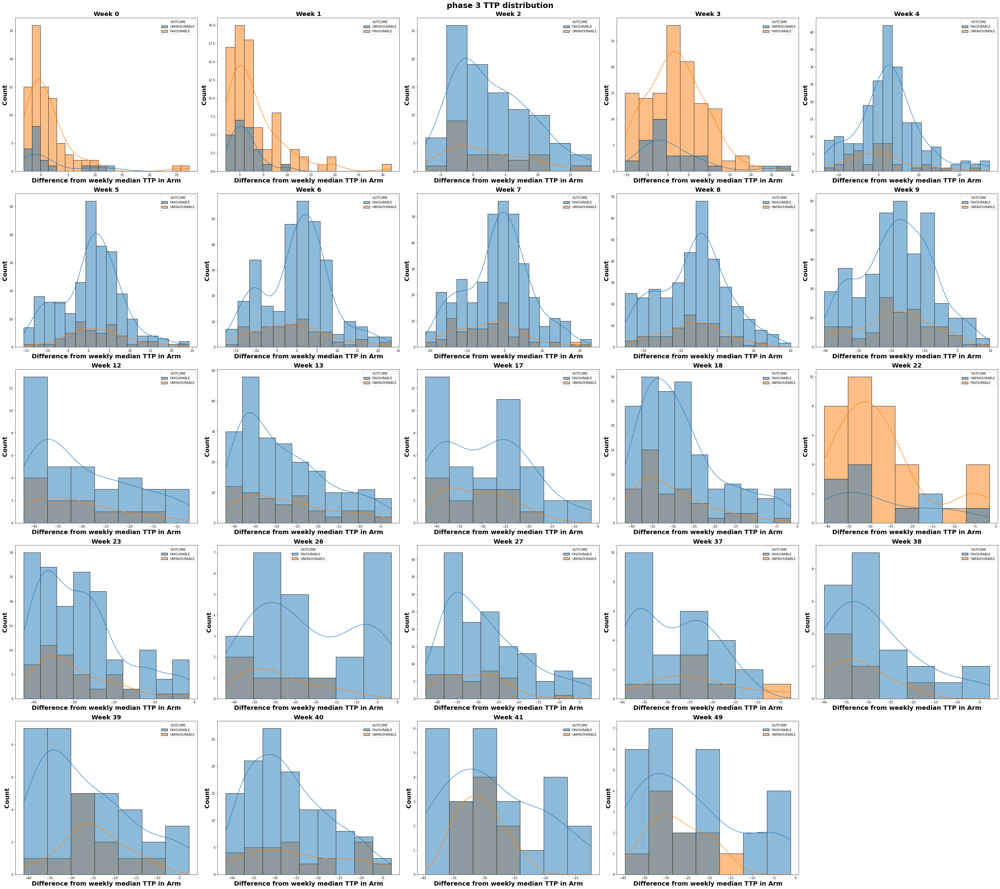

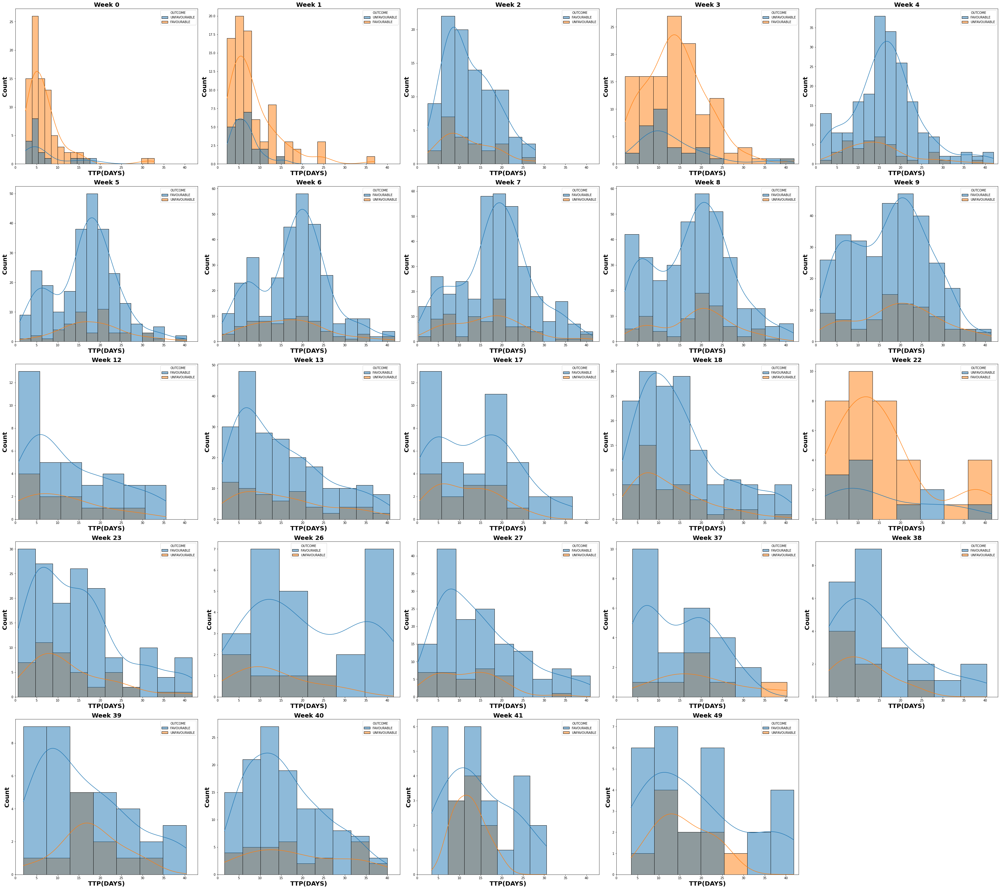

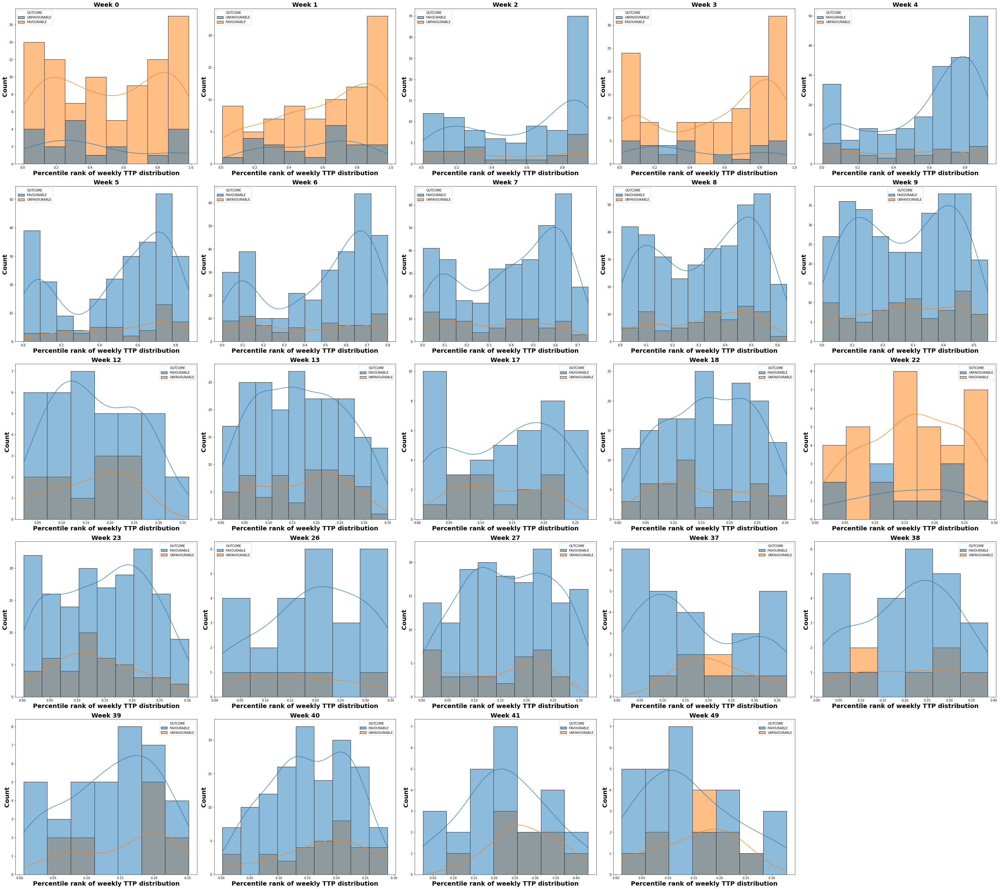

In [408]:
for phase in [3]:
    phase_df = mb_clean_mgit[(mb_clean_mgit['PHASE'] == phase)&(mb_clean_mgit['STUDYID'] == 'TB-1021')]
    if phase == 3 or phase==2:
        # If phase 3, then pool the sample measurements to weeks as the days would give too many subplots
        #phase_df['THERAPY_WEEK'] = [math.ceil(x/7) for x in phase_df['MBDY']]

        # Set therapy duration
        # therapy_duration=int(math.ceil(182/7))
        therapy_duration = int(math.ceil(phase_df['THERAPY_DURATION'].max()/7))

        # Set parameters of plot
        min_num_of_samples_to_plot = 200
        n_cols = 5
        num_of_plots = sum(phase_df[phase_df['THERAPY_WEEK'] <= therapy_duration].groupby(
                by=['THERAPY_WEEK']).size() > min_num_of_samples_to_plot)
        n_rows = math.ceil(num_of_plots/n_cols)
        
        fig= plt.figure(figsize=(45, 40), constrained_layout=True)
        fig2 = plt.figure(figsize=(45, 40), constrained_layout=True)
        fig3 = plt.figure(figsize=(45, 40), constrained_layout=True)
        fig.suptitle('phase '+str(phase)+' TTP distribution',fontsize=25, weight='bold')
        n = 0
        #for week in range(int(min(phase_df['MBDY'])),therapy_duration+1):
        for week in range(-1,50):
            plot_df_all= phase_df[(phase_df['MBTSTDTL'] == 'Time to Detection')&(phase_df['TTP(DAYS)'] <44)&
                                (phase_df['THERAPY_WEEK'] ==week) ]
            if len(plot_df_all) > min_num_of_samples_to_plot:
                plot_ax=fig.add_subplot(n_rows, n_cols,n+1)
                plot_ax2=fig2.add_subplot(n_rows, n_cols,n+1)
                plot_ax3=fig3.add_subplot(n_rows, n_cols,n+1)
                n=n+1
                data=plot_df_all#.loc[plot_df_all['ARM']=='2MHRZ/2MHR',:] #2EHRZ/4HR #
                scaler = StandardScaler()
                minmax_norm=MinMaxScaler()
                #data['scaled_TTP(DAYS)']=scaler.fit_transform(np.asarray(data['TTP(DAYS)']).reshape(-1,1))
                #data['perc_rank']=data['TTP(DAYS)'].sort_values().rank(pct=True)
                #data['norm_TTP(DAYS)']=minmax_norm.fit_transform(np.asarray(data['TTP(DAYS)']).reshape(-1,1))
                #data.loc[data['MB_RESULT'] == 'isolated MGIT positive','TTP(DAYS)']
                
                
                #print(data)
                
                #sns.histplot(data=data,x='scaled_TTP(DAYS)',ax=plot_ax,kde=True)
                #print(data[data['MB_RESULT'] == 'isolated MGIT positive'])
                if len(data[data['MB_RESULT'] == 'isolated MGIT positive'])>1:
                    sns.histplot(data=data[data['MB_RESULT'] == 'isolated MGIT positive'],
                                x='DIFFERENCE_FROM_MEDIAN',ax=plot_ax,kde=True,hue='OUTCOME',stat='count')
                    sns.histplot(data=data[data['MB_RESULT'] == 'isolated MGIT positive'],
                                x='TTP(DAYS)',ax=plot_ax2,kde=True,hue='OUTCOME',stat='count')
                    sns.histplot(data=data[data['MB_RESULT'] == 'isolated MGIT positive'],
                                x='TTP(DAYS)_perc_rank',ax=plot_ax3,kde=True,hue='OUTCOME',stat='count')
                    
                    #sns.histplot(data=data,x='DIFFERENCE_FROM_MEDIAN',ax=plot_ax,kde=True,alpha=0.7,hue='ARM')
                    #sns.histplot(data=data,x='TTP(DAYS)',ax=plot_ax2,kde=True,alpha=0.7,hue='ARM')
                    #sns.histplot(data=data,x='TTP(DAYS)_perc_rank',ax=plot_ax3,kde=True,alpha=0.7,hue='ARM')
                    
                    #plot_ax.axvline(data['DIFFERENCE_FROM_MEDIAN'].median(),label='Median',color='r', linestyle='--')
                    #plot_ax2.axvline(data['TTP(DAYS)'].median(),label='Median',color='r', linestyle='--')
                    #plot_ax3.axvline(data['TTP(DAYS)_perc_rank'].median(),label='Median',color='r', linestyle='--')


                #plot_ax.set_xlim(-3, 8)
                plot_ax.set_title('Week '+str(week), weight='bold',fontsize=20)
                plot_ax.set_xlabel('Difference from weekly median TTP in Arm', weight='bold',fontsize=20)
                plot_ax.set_ylabel('Count', weight='bold',fontsize=20)
                plot_ax2.set_xlim(0, 43)
                plot_ax2.set_title('Week '+str(week), weight='bold',fontsize=20)
                plot_ax2.set_xlabel('TTP(DAYS)', weight='bold',fontsize=20)
                plot_ax2.set_ylabel('Count', weight='bold',fontsize=20)
                #plot_ax3.set_xlim(0,1)
                plot_ax3.set_title('Week '+str(week), weight='bold',fontsize=20)  
                plot_ax3.set_xlabel('Percentile rank of weekly TTP distribution', weight='bold',fontsize=20)   
                plot_ax3.set_ylabel('Count', weight='bold',fontsize=20)              

<hr>

* #### PLOT DISTRIBUTION OF MGIT TTP RESULTS OVER THERAPY AS HISTPLOTS PER PHASE
* #### PLOT ISOLATED MGIT POSITIVE DISTRIBUTIONS AS WELL ON SAME PLOT

In [ ]:
for phase in [3]:
    phase_df = mb_clean_mgit[mb_clean_mgit['PHASE'] == phase]
    if phase == 3 or phase==2:
        # If phase 3, then pool the sample measurements to weeks as the days would give too many subplots
        phase_df['THERAPY_WEEK'] = [math.ceil(x/7) for x in phase_df['MBDY']]

        # Set therapy duration
        # therapy_duration=int(math.ceil(182/7))
        therapy_duration = int(math.ceil(phase_df['MBDY'].max()/7))

        # Set parameters of plot
        min_num_of_samples_to_plot = 20
        n_cols = 5
        num_of_plots = sum(phase_df[phase_df['THERAPY_WEEK'] <= therapy_duration+4].groupby(
            by=['THERAPY_WEEK']).size() > min_num_of_samples_to_plot)
        n_rows = math.ceil(num_of_plots/n_cols)
        fig = plt.figure(figsize=(15, 10), constrained_layout=True)
        fig.suptitle('phase '+str(phase)+' TTP distribution',
                     fontsize=25, weight='bold')
        n = 0
        
        therapy_duration = int(math.ceil(phase_df['MBDY'].max()/7))
        for week in range(min(phase_df['THERAPY_WEEK']), therapy_duration+5):
            plot_df_all = phase_df[(phase_df['THERAPY_WEEK'] == week) & (
                phase_df['MBTSTDTL'] == 'Time to Detection')&(phase_df['TTP(DAYS)'] <43)]
            plot_df_isol_pos = phase_df[(phase_df['THERAPY_WEEK'] == week) & (phase_df['MBTSTDTL'] == 'Time to Detection') &
                                        (phase_df['MB_RESULT'] == 'isolated MGIT positive')&(phase_df['TTP(DAYS)'] <43)]
            if len(plot_df_all) > min_num_of_samples_to_plot:
                plot_ax = plt.subplot(n_rows, n_cols, n+1)
                n = n+1
                #sns.histplot(data=plot_df_all, x='TTP(DAYS)', ax=plot_ax,label='All MGIT Pos.', color='blue', legend='full')
                #sns.histplot(data=plot_df_isol_pos, x='TTP(DAYS)', ax=plot_ax,label='Isol. MGIT Pos.', color='red', legend='full')
                #sns.histplot(data=plot_df_all,x='TTP(DAYS)',ax=plot_ax,hue='ARM')
                
                #sns.histplot(data=plot_df_isol_pos, x='TTP(DAYS)',ax=plot_ax, hue='OUTCOME')
                plot_ax.set_title('Week '+str(week), weight='bold')
                plot_ax.set_xlim(0, 45)
                handles, labels = plot_ax.get_legend_handles_labels()
        fig.legend(handles, labels, fontsize=25, prop={'weight': 'bold'})
    '''
    if phase != 3:
        if phase == 1:
            therapy_duration = 14
        if phase == 2:
            therapy_duration = 60
        # Set parameters of plot
        min_num_of_samples_to_plot = 30
        n_cols = 5
        num_of_plots = sum(phase_df[phase_df['MBDY'] <= therapy_duration].groupby(by=['MBDY']).size() > min_num_of_samples_to_plot)
        n_rows = math.ceil(num_of_plots/n_cols)
        fig = plt.figure(figsize=(15, 20), constrained_layout=True)
        fig.suptitle('phase '+str(phase)+' TTP distribution',fontsize=25, weight='bold')
        n = 0

        for day in range(int(min(phase_df['MBDY'])), therapy_duration+1):
            plot_df_all = phase_df[(phase_df['MBDY'] == day) & (
                phase_df['MBTSTDTL'] == 'Time to Detection')]
            plot_df_isol_pos = phase_df[(phase_df['MBDY'] == day) & (phase_df['MBTSTDTL'] == 'Time to Detection') &
                                        (phase_df['MB_RESULT'] == 'isolated MGIT positive')]
            if len(plot_df_all) > min_num_of_samples_to_plot:
                plot_ax = plt.subplot(n_rows, n_cols, n+1)
                n = n+1
                sns.histplot(data=plot_df_all,x='TTP(DAYS)',ax=plot_ax,hue='ARM')
                #sns.histplot(data=plot_df_all, x='TTP(DAYS)', ax=plot_ax,label='All MGIT Pos.', color='blue', legend='full')
                #sns.histplot(data=plot_df_isol_pos, x='TTP(DAYS)', ax=plot_ax,label='Isol. MGIT Pos.', color='red', legend='full')
                plot_ax.set_title('Day '+str(day), weight='bold')
                plot_ax.set_xlim(0, 45)
                handles, labels = plot_ax.get_legend_handles_labels()
                plot_ax.legend('')
        fig.legend('')
        #fig.legend(handles, labels, fontsize=15, prop={'weight': 'bold'})
    '''

<hr>

##### **COLLECT THE NUMBER OF ISOLATED MGIT POSITIVE MEASUREMENTS FOR EACH PATIENT OVER THE COURSE OF THERAPY INTO A DICTIONARY**
##### 1.DEFINE ISOLATED MGIT POSITIVITY AS 4  DIFFERENT CATEGORIES, TO COMPARE THEM LATER IN ANALYSIS:
* ###### ALL ISOLATED MGIT POSITIVES WITH RESULT 0-42 DAYS
* ###### ISOLATED MGIT POSITIVES WITH RESULT <5 DAYS (HIGH BACTERIAL LOAD)
* ###### ISOLATED MGIT POSITIVES WITH RESULT 5-15 DAYS (MEDIUM BACTERIAL LOAD)
* ###### ISOLATED MGIT POSITIVES WITH RESULT 15-42 DAYS (LOW BACTERIAL LOAD)

##### 2. ADD ARM AND OUTCOME (WHERE AVAILABLE) INFORMATION TO THE DATAFRAMES

In [51]:
ttp_categories = ['0-42days', '0-5days', '5-15days', '15-42days']
isolated_ttp_pos_cumul_dict = {}
isolated_ttp_pos_diff_dict = {}

for ttp_cat in ttp_categories:
    # set up dataframe to collect the increase in isolated ttp positive measurement points between
    # day of therapy measurement timepoints

    isolated_ttp_pos_over_time_diff = pd.DataFrame(0, index=mb_clean_mgit['MBDY'].sort_values().unique(),
                                                   columns=mb_clean_mgit['USUBJID'].unique())

    # Select appropriate column name which holds TTP category information +
    # TTP category string name to select as isolated TTP category
    if ttp_cat == '0-42days':
        ttp_category_colname = 'MB_RESULT'
        ttp_category_string = 'isolated MGIT positive'
    if ttp_cat != '0-42days':
        ttp_category_colname = 'TTP_CATEGORY'
        ttp_category_string = 'isolated MGIT pos.- '+ttp_cat

    for n, day in enumerate(mb_clean_mgit['MBDY'].sort_values().unique()):
        d = mb_clean_mgit[mb_clean_mgit['MBDY'] == day]
        # Select which TTP Category to choose as isolated TTP positive
        df_ttp_pos = d[d[ttp_category_colname].str.contains(ttp_category_string, na=False)]
        ttp_pos_patients = df_ttp_pos['USUBJID'].value_counts(dropna=False)

        # If patient had isolated MGIT positive sample on that day, add the number of measurements to respective cell in the dataframe
        for coln in isolated_ttp_pos_over_time_diff.columns:
            if coln in ttp_pos_patients.index:
                isolated_ttp_pos_over_time_diff.loc[day,coln] = ttp_pos_patients[coln]
            

    # get cumulative increase of numbers of isolated ttp positive samples
    isolated_ttp_pos_over_time_cumul = isolated_ttp_pos_over_time_diff.cumsum()

    for isol_ttp_df,isol_ttp_dict in zip([isolated_ttp_pos_over_time_diff,isolated_ttp_pos_over_time_cumul],
                                         [isolated_ttp_pos_diff_dict,isolated_ttp_pos_cumul_dict]):
        # Transpose cumulative patients datafarme in order to add ARM and PHASE column
        isol_ttp_df = isol_ttp_df.T

        temp_df = pat_id_df.set_index('USUBJID')
        temp_df = temp_df.reindex(isol_ttp_df.index)
        isol_ttp_df['ARM'] = temp_df['ARM']
        #isol_ttp_df['PHASE'] = temp_df['PHASE'].astype(str)

        # Add outcome information to dataframe where it is available
        isol_ttp_df['OUTCOME'] = np.nan
        isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_favourable), 'OUTCOME'] = 'FAVOURABLE'
        isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_unfavourable), 'OUTCOME'] = 'UNFAVOURABLE'

        # Add failure/relapse/late drug resistance information to dataframe where it is available
        isol_ttp_df['UNFAVOURABLE_OUTCOME_CATEGORY'] = np.nan
        isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_favourable), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'FAVOURABLE'
        isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_relapse), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'RELAPSE'
        isol_ttp_df.loc[isol_ttp_df.index.isin(pat_ids_treatment_failure), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'TREATMENT FAILURE'
        #isolated_ttp_pos_over_time_cumul.loc[isolated_ttp_pos_over_time_cumul.index.isin(pat_ids_resistance), 'UNFAVOURABLE_OUTCOME_CATEGORY'] = 'LATE DRUG RESISTANCE'

        isol_ttp_dict[ttp_cat] = isol_ttp_df


<AxesSubplot:>

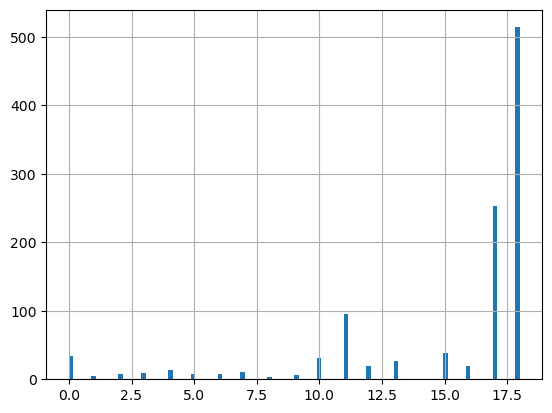

In [61]:
#isolated_ttp_pos_over_time_diff
isol_ttp_dict['0-42days'].drop(columns='ARM').max().hist(bins=100)

<HR>

#### **FOR EACH PATIENT DIVIDE THE CUMULATIVE ISOLATED MGIT VALUES BY THE NUMBER OF ALL MGIT MEASUREMENTS FOR THAT PATIENT, THEN MULTIPLY IT BY 100**
* #### THIS ACTS AS A NORMALIZATION METHOD, BECAUSE PATIENTS HAVE DIFFERENT NUMBERS OF MEASUREMENTS

In [64]:
### 
# 1. Extract number of all the MGIT measurements during study for each patient

num_of_mgit_measurement = pd.DataFrame(np.nan, columns=['number_of_MGIT_measurement'], index=mb_clean_mgit['USUBJID'].unique())
num_of_meas_list = []
last_measured_day=[]

for pat_id in mb_clean_mgit['USUBJID'].unique():
    pat_df=(mb_clean_mgit[(mb_clean_mgit['USUBJID'] == pat_id) & (mb_clean_mgit['MBTSTDTL'] == 'Time to Detection')])
    num_of_meas_per_pat = len(pat_df)
    num_of_meas_list.append(num_of_meas_per_pat)
    last_measured_day.append(pat_df['MBDY'].max())
num_of_mgit_measurement['number_of_MGIT_measurement'] = num_of_meas_list
num_of_mgit_measurement['last_MGIT_measurement_day']=last_measured_day

# 2. Extract number of the MGIT measurements for every timepoint for each patient
num_of_mgit_measur_over_time_diff=pd.DataFrame(0, index=mb_clean_mgit['MBDY'].sort_values().unique(),
                                                   columns=mb_clean_mgit['USUBJID'].unique())

# Extract number of MGIT measurements per patient for each timepoint
for n, day in enumerate(mb_clean_mgit['MBDY'].sort_values().unique()):
    d = mb_clean_mgit[mb_clean_mgit['MBDY'] == day]
    df_mgit_measur=d[d['MBTSTDTL'].str.contains('Time to Detection', na=False)]
    mgit_measur_patients= df_mgit_measur['USUBJID'].value_counts(dropna=False)

    for coln in num_of_mgit_measur_over_time_diff.columns:
        if coln in mgit_measur_patients.index:
            num_of_mgit_measur_over_time_diff.loc[day,coln] = mgit_measur_patients[coln]
        
    num_of_mgit_measur_over_time_cumul = num_of_mgit_measur_over_time_diff.cumsum()


# - Add LAST MGIT MEASUREMENT DAY, PHASE, THERAPY DURATION to the datasets containing the number of MGIT measurements
# - Create a ratio of the therapy length/day of last measured MGIT sample, in order to filter out patients 
#   who have incomplete MGIT data during the therapy

num_of_mgit_measur_over_time_cumul['last_MGIT_measurement_day']=num_of_mgit_measurement['last_MGIT_measurement_day']

for df in[num_of_mgit_measurement,num_of_mgit_measur_over_time_cumul]:
    temp_df = pat_id_df.set_index('USUBJID')
    #df['PHASE'] = temp_df['PHASE'].astype(str)
    df['THERAPY_DURATION']=182
    #for phase,therapy_duration in zip(['1','2','3'],[14,56,182]):
    #    df.loc[df['PHASE']==phase,'THERAPY_DURATION']=therapy_duration
    df['MEASURED_DATA_THERAPY_DURATION_RATIO']=df['last_MGIT_measurement_day']/df['THERAPY_DURATION']


# Divide dataframes by the extracted number of measured MGIT values (matched to patient)
# then multiply by 100 to get percentage
# Save to dictionary
isolated_ttp_pos_cumul_percentage_dict = {}
isolated_ttp_pos_diff_percentage_dict = {}
for ttp_percentage_dict,ttp_dict in zip([isolated_ttp_pos_diff_percentage_dict,isolated_ttp_pos_cumul_percentage_dict],
                                        [isolated_ttp_pos_diff_dict,isolated_ttp_pos_cumul_dict]):
    for ttp_cat in ttp_dict.keys():
        isolated_ttp_pos_over_time = ttp_dict[ttp_cat].copy()
        pat_ids=num_of_mgit_measurement[num_of_mgit_measurement['MEASURED_DATA_THERAPY_DURATION_RATIO']>=0.9].index
        # get number of non-numeric columns
        n_non_numeric=len(ttp_dict[ttp_cat].select_dtypes(include=['object']).columns)

        ### Decide which method to use for normalization for the number of MGIT measurements between patients 
        ### Decide for 1. or .2
        # 1. Divide by the number of all MGIT measurements during the study for each patient
        #isolated_ttp_pos_over_time.loc[pat_ids, isolated_ttp_pos_over_time.columns[:-n_non_numeric]] = (isolated_ttp_pos_over_time.loc[pat_ids, isolated_ttp_pos_over_time.columns[:-n_non_numeric]].div(num_of_mgit_measurement.loc[pat_ids,'number_of_MGIT_measurement'], axis=0))*100
        
        # 2. Divide by the number of MGIT measurements carried out for each patient until that timepoint along the whole therapy
        isolated_ttp_pos_over_time.loc[pat_ids, isolated_ttp_pos_over_time.columns[:-n_non_numeric]] = (isolated_ttp_pos_over_time.loc[pat_ids, isolated_ttp_pos_over_time.columns[:-n_non_numeric]].div(num_of_mgit_measur_over_time_cumul.loc[pat_ids,:].T, axis=0))*100
        
        # Fill the NaN values with 0 as the NaNs are generated from 0 divided by a float
        isolated_ttp_pos_over_time.loc[pat_ids,isolated_ttp_pos_over_time.columns[:-n_non_numeric]]=isolated_ttp_pos_over_time.loc[pat_ids,isolated_ttp_pos_over_time.columns[:-n_non_numeric]].fillna(0)
        ttp_percentage_dict[ttp_cat] = isolated_ttp_pos_over_time.loc[pat_ids,:]


KeyError: "None of [Index(['TB-1021/1093230', 'TB-1021/1089568', 'TB-1021/2722385',\n       'TB-1021/1564215', 'TB-1021/2498734', 'TB-1021/2146046',\n       'TB-1021/2259272', 'TB-1021/1954470', 'TB-1021/2584782',\n       'TB-1021/1572225',\n       ...\n       'TB-1020/2174', 'TB-1020/4192', 'TB-1018/02-9006', 'TB-1018/04-9012',\n       'TB-1018/02-9012', 'TB-1018/02-9039', 'TB-1018/04-9002',\n       'TB-1018/01-9058', 'TB-1018/01-9030', 'TB-1018/01-9024'],\n      dtype='object', length=1828)] are in the [index]"

<hr>

#### **VISUALIZE TB-1021 ISOLATED MGIT POSITIVE VALUES OVER TIME BY OUTCOME (FAVOURABLE VS. UNFAVOURABLE)**

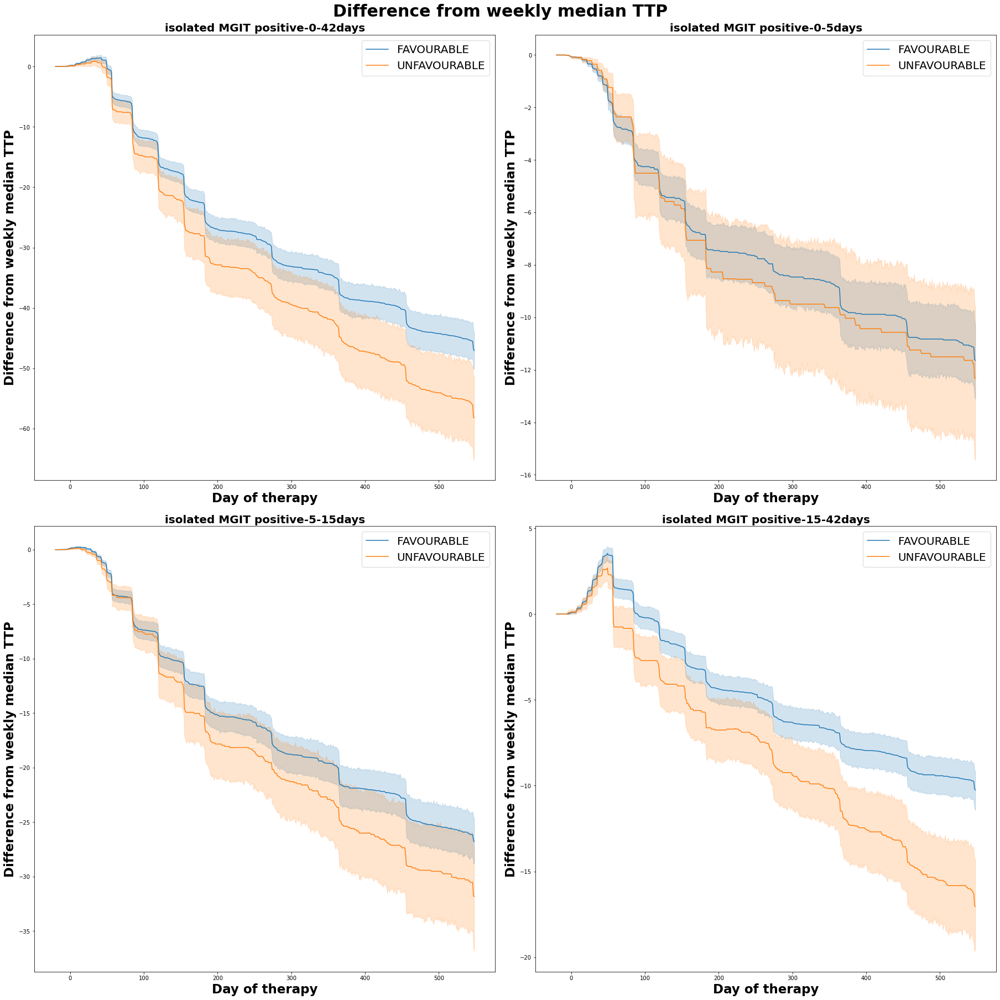

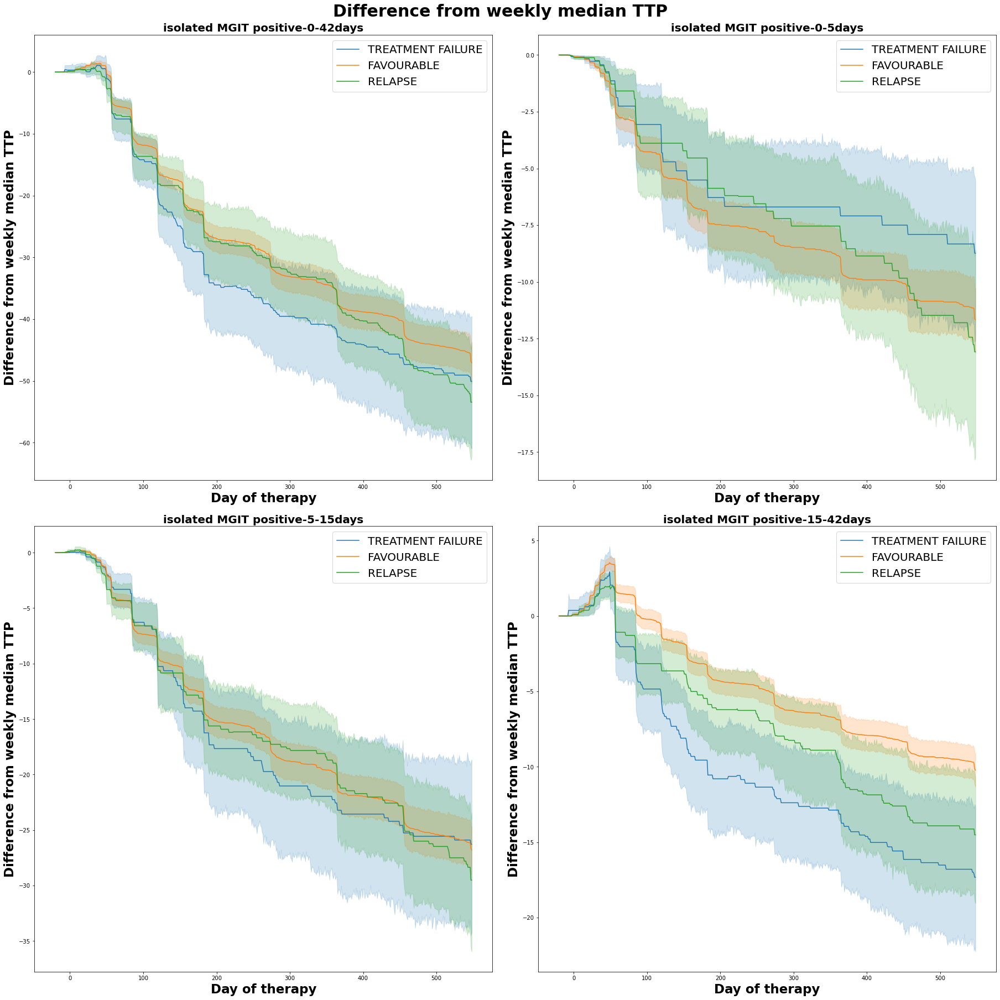

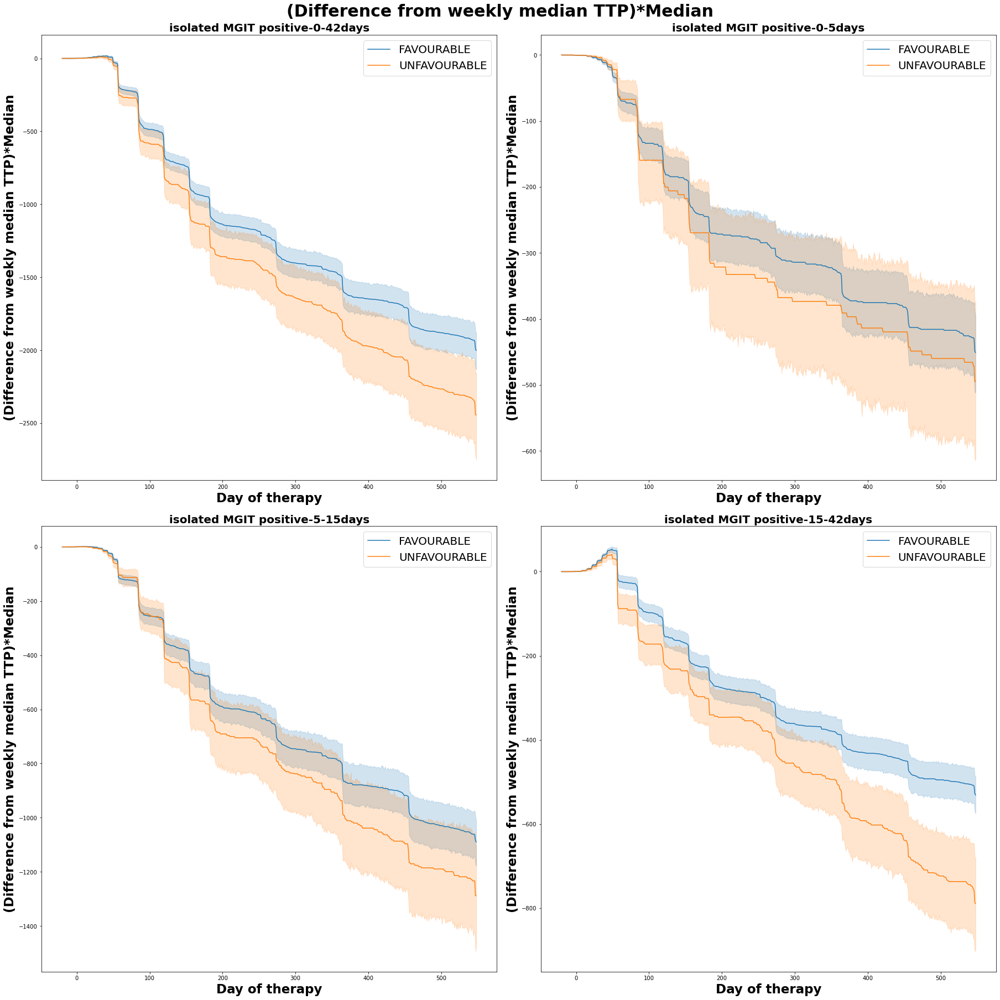

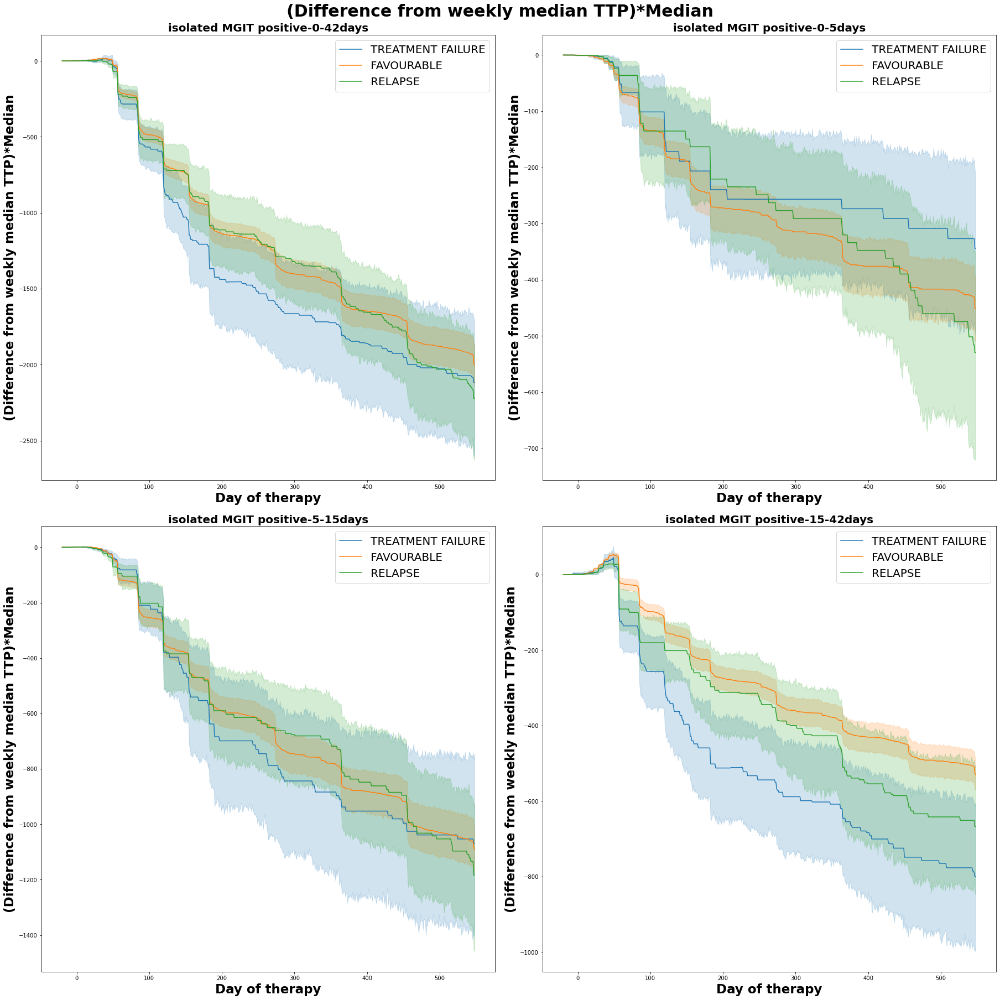

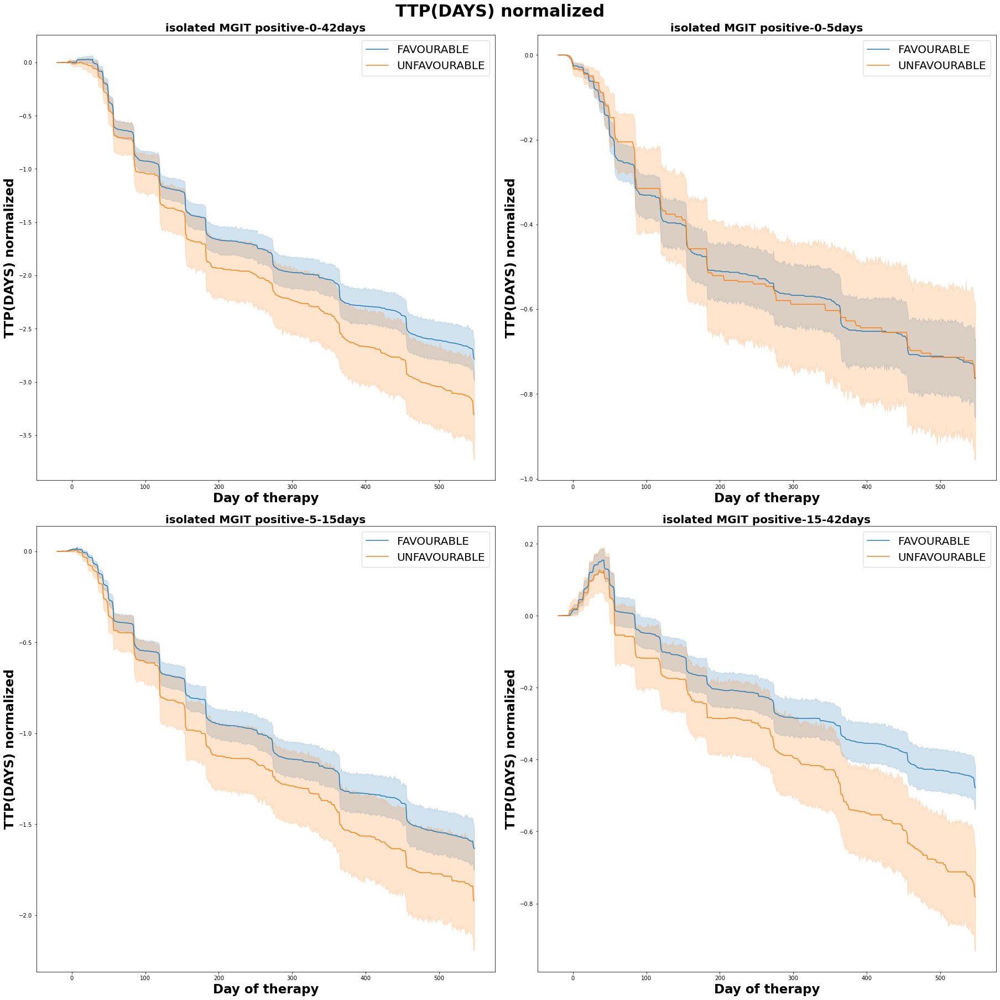

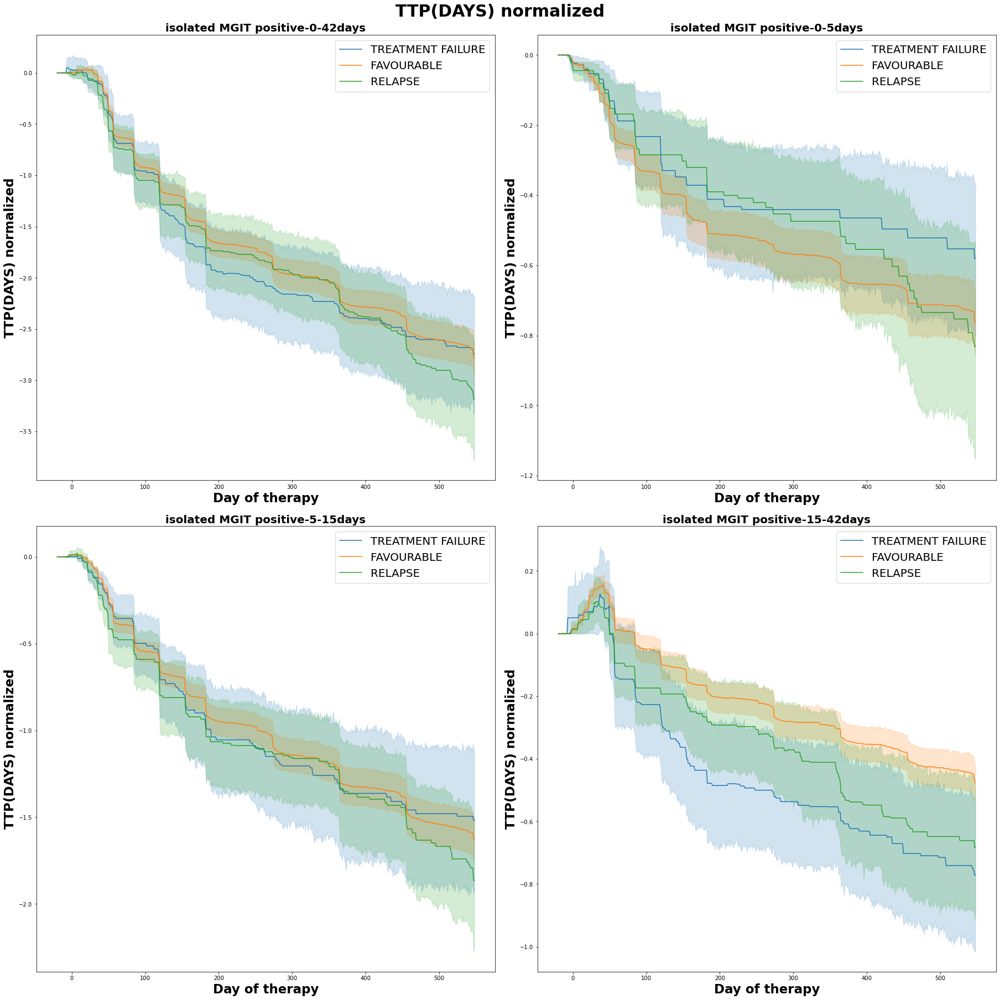

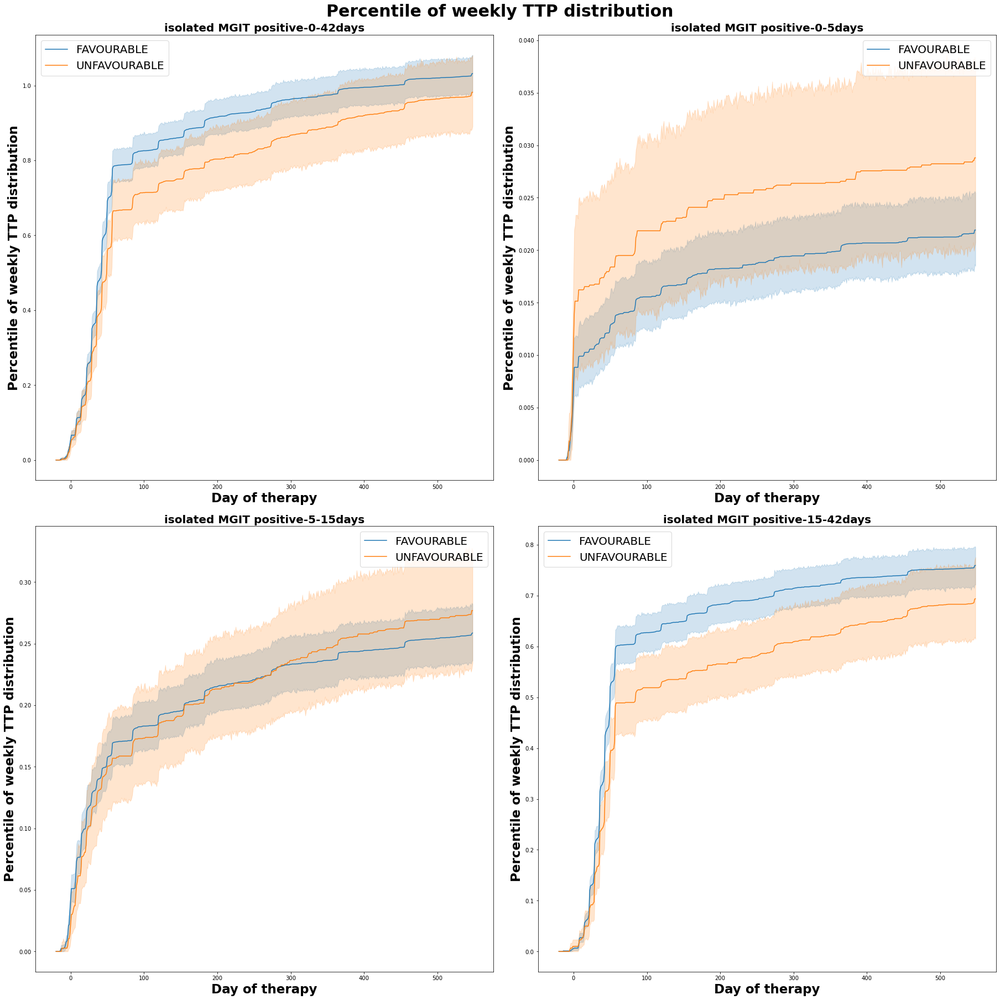

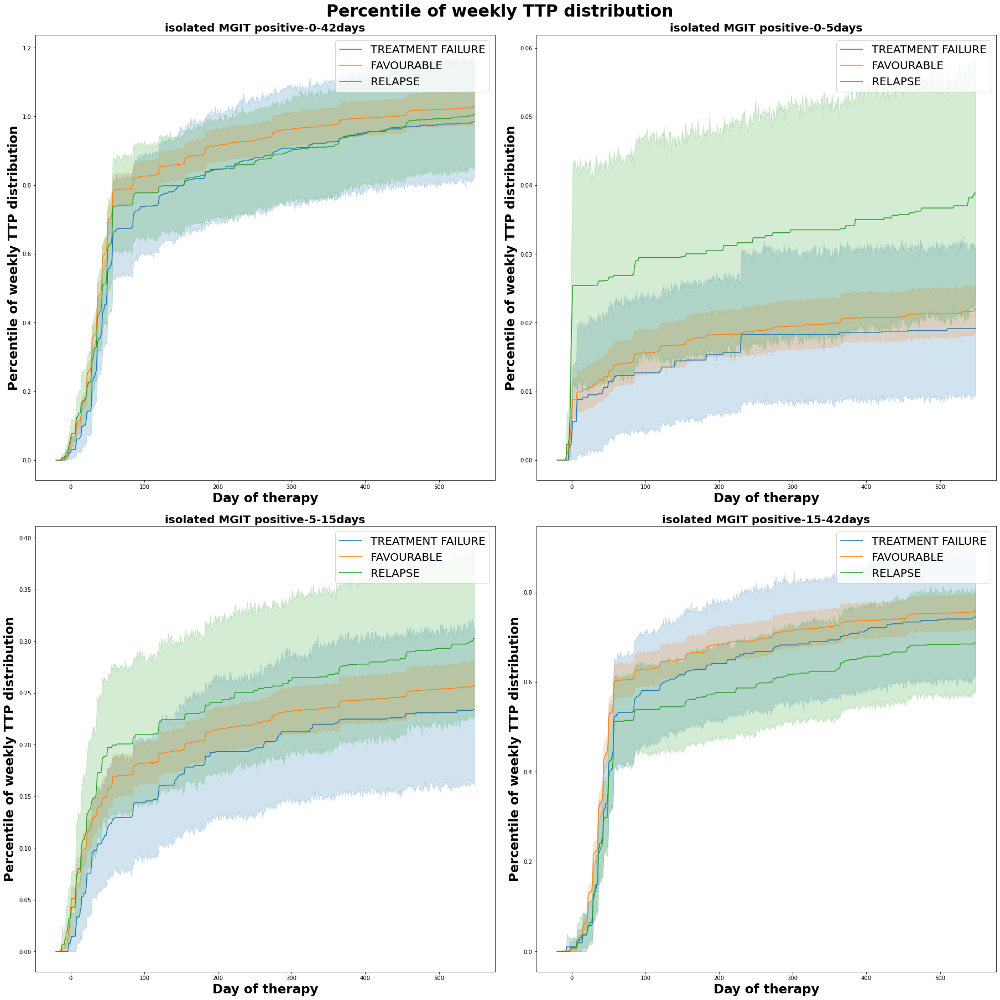

In [409]:
diff_dicts=[isolated_ttp_pos_diff_median_dict,isolated_ttp_pos_diff_median_weighted_dict,
            isolated_ttp_pos_diff_scaled_ttp_dict,isolated_ttp_pos_diff_percentile_ttp_dict]

cumul_dicts=[isolated_ttp_pos_cumul_median_dict,isolated_ttp_pos_cumul_median_weighted_dict,
             isolated_ttp_pos_cumul_scaled_ttp_dict,isolated_ttp_pos_cumul_percentile_ttp_dict]

col_names=['Difference from weekly median TTP','(Difference from weekly median TTP)*Median',
           'TTP(DAYS) normalized','Percentile of weekly TTP distribution']

for cumul_dict,col_name in zip(cumul_dicts[:],col_names[:]):
    for visual_cat in ['OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY']:
        # Set parameters for subplots
        n_cols=2
        num_of_plots=len(cumul_dict.keys())
        n_rows=math.ceil(num_of_plots/n_cols)
        fig,ax= plt.subplots(n_rows,n_cols,figsize=(25,25),constrained_layout=True)
        ax=ax.flatten()
        n=0
        for ttp_cat,isolated_ttp_pos_over_time_cumul in cumul_dict.items():
            # get number of non-numeric columns
            n_non_numeric=len(isolated_ttp_pos_over_time_cumul.select_dtypes(include=['object']).columns)

            # Add figure title name
            fig.suptitle(col_name,fontsize=30,weight='bold')

            for phase in [3]:
                phase_df=mb_clean_mgit[(mb_clean_mgit['PHASE']==phase)&
                                    (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul.index))]

                for study in phase_df['STUDYID'].unique(): #['TB-1021']:0
                    study_df=phase_df[phase_df['STUDYID']==study]
                    study_patients=study_df['USUBJID'].unique()
              

                    # Subset dataframe to show only days ewhere threapy was applied
                    stop_day=math.ceil(365*1.5) #study_df['MBDY'].max()#study_df.loc[:,'THERAPY_DURATION'].max()
                    #stop_day=study_df.loc[:,'THERAPY_DURATION'].max()+20
                    filt=isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric]<=(stop_day)
                    filt=np.append(filt,[True,]*n_non_numeric)
                    plot_df=isolated_ttp_pos_over_time_cumul.loc[study_patients,filt]
                    plot_ax=ax[n]

                    #Transform dataset for the appropriate plotting format
                    plot_df = plot_df.reset_index().melt(id_vars=['index','ARM','OUTCOME','PHASE','UNFAVOURABLE_OUTCOME_CATEGORY'], var_name='day_of_therapy')
                    sns.lineplot(data=plot_df,x='day_of_therapy',y='value',hue=visual_cat,ax=plot_ax)
                    plot_ax.set_title('isolated MGIT positive-'+str(ttp_cat),fontsize=20,weight='bold')
                    plot_ax.set_ylabel(col_name,fontsize=23,weight='bold')
                    plot_ax.set_xlabel('Day of therapy',fontsize=23,weight='bold')
                    plot_ax.legend(fontsize=20)
                    n=n+1
                #plt.tight_layout()

ValueError: could not convert string to float: 'TB-1021'

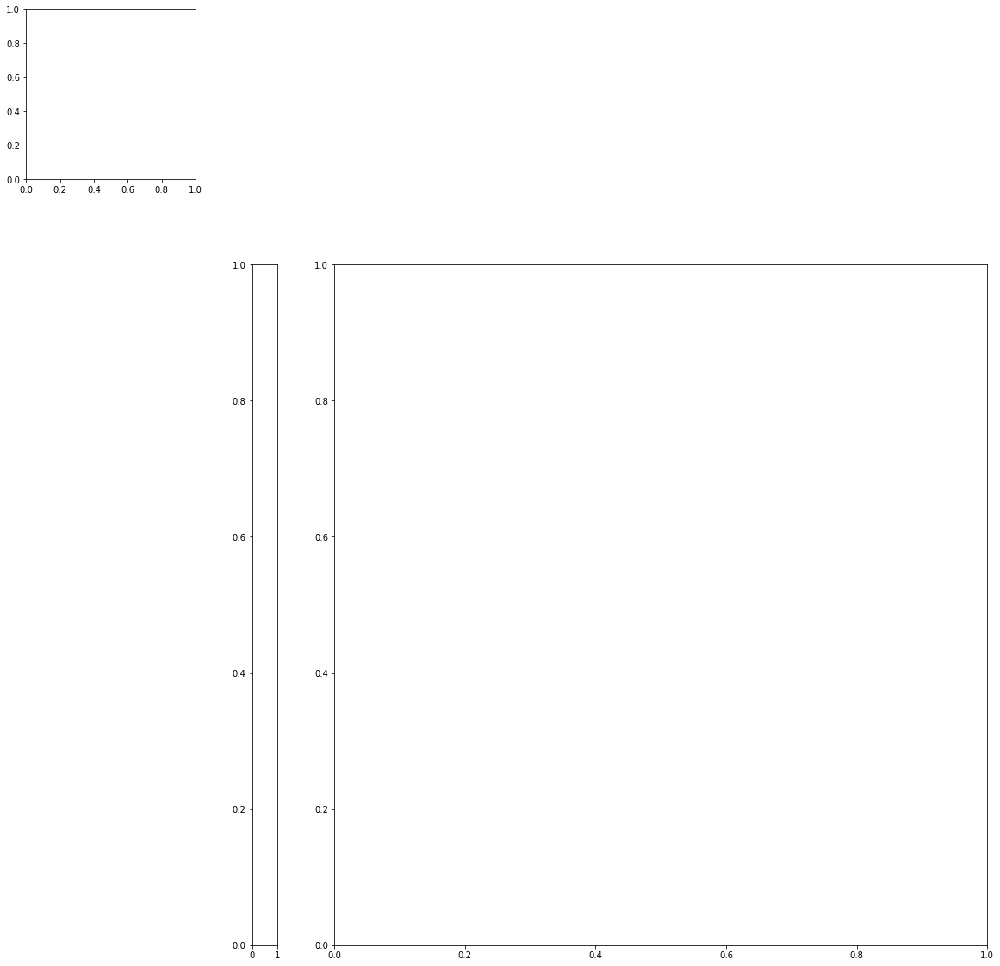

In [359]:
plot_df=mb_clean_mgit[~mb_clean_mgit['OUTCOME'].isna()&(mb_clean_mgit['THERAPY_WEEK']<30)&
                      (mb_clean_mgit['MB_RESULT']=='isolated MGIT positive')]

plot_df['DIFFERENCE_FROM_MEDIAN_WEIGHTED']=plot_df['DIFFERENCE_FROM_MEDIAN']*plot_df['TTP(DAYS)']
plot_df['log_TTP(DAYS)']=np.log10(plot_df['TTP(DAYS)'])
for col in['TTP(DAYS)','DIFFERENCE_FROM_MEDIAN','DIFFERENCE_FROM_MEDIAN_WEIGHTED','scaled_TTP(DAYS)','TTP(DAYS)_perc_rank']:
  fig,ax=plt.subplots(1,figsize=(35,25))
  sns.histplot(data=plot_df,x='THERAPY_WEEK',y=col,hue='OUTCOME',ax=ax)#,inner='point')
  sns.boxplot(data=plot_df,x='THERAPY_WEEK',y=col,hue='MB_RESULT',ax=ax)
  ax.set_title(col,fontsize=30,weight='bold')
  ax.xaxis.get_label().set_fontsize(22)
  ax.set_ylabel(col,fontsize=22,weight='bold')
  ax.legend(fontsize=30)
 

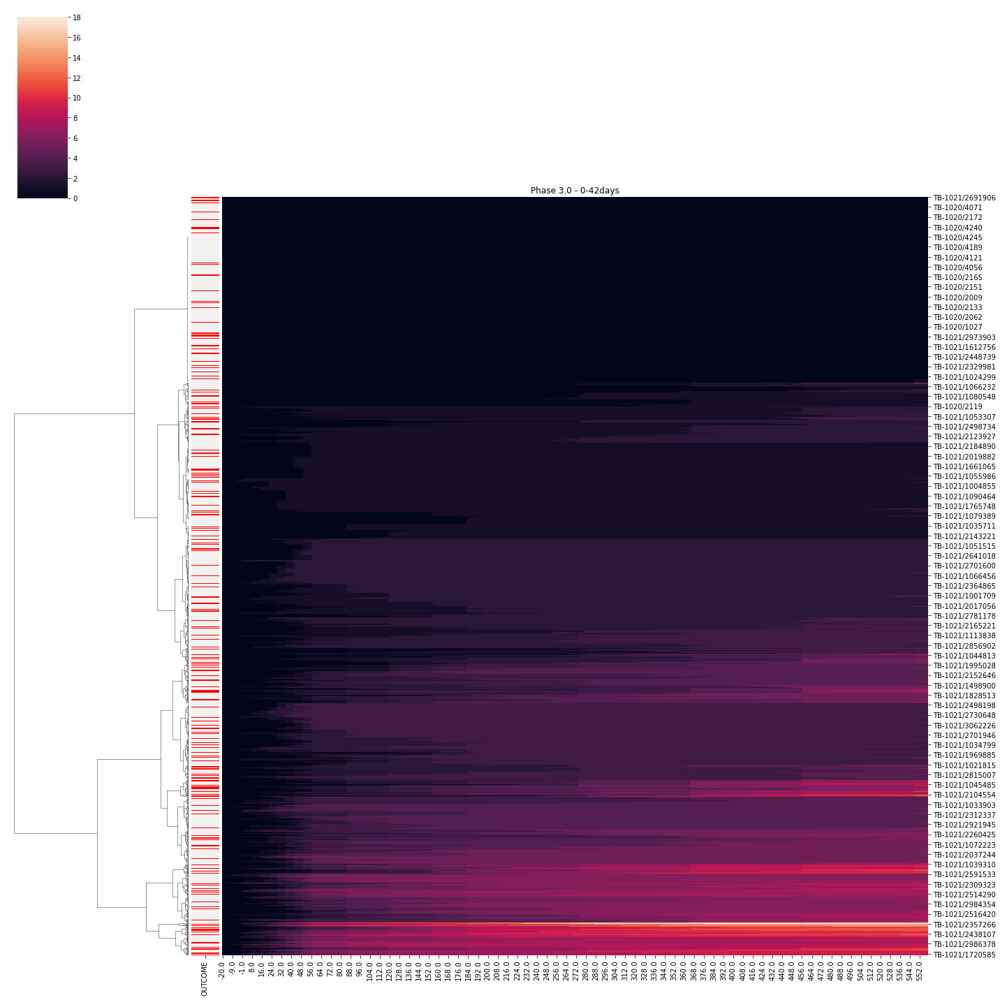

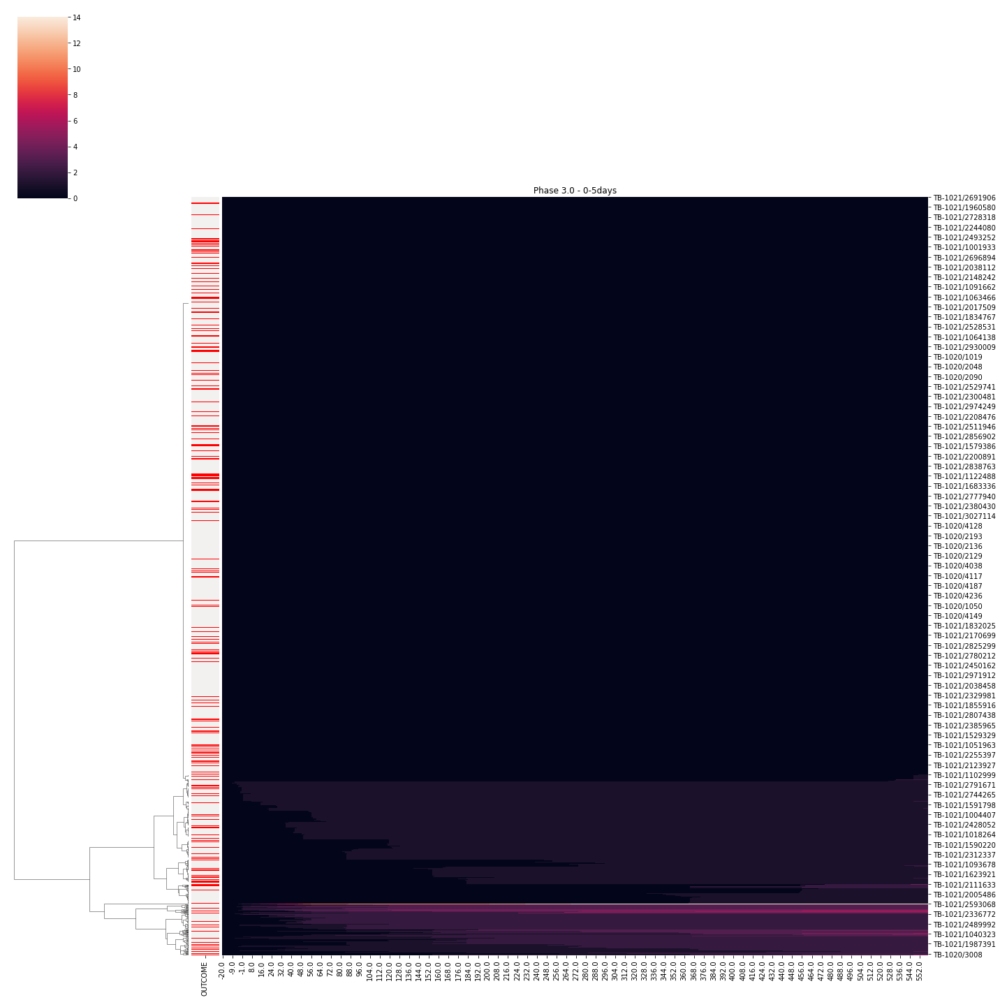

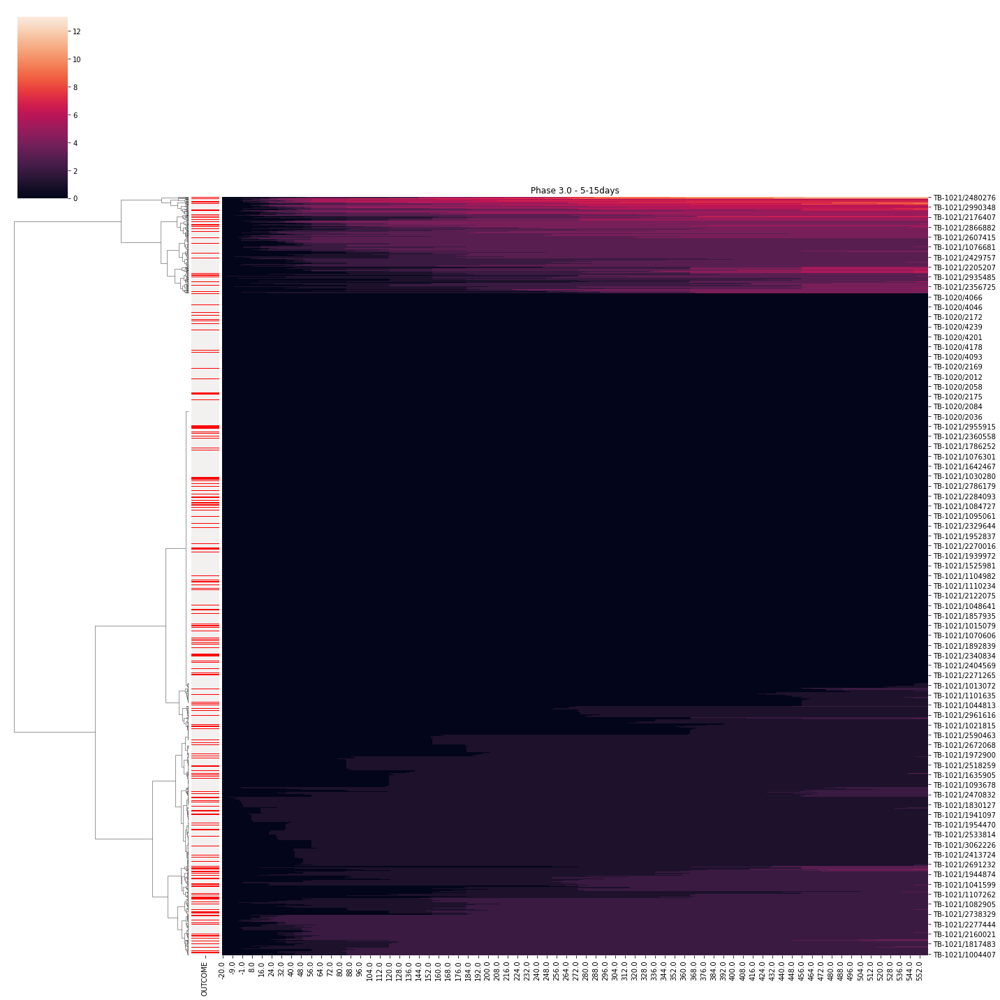

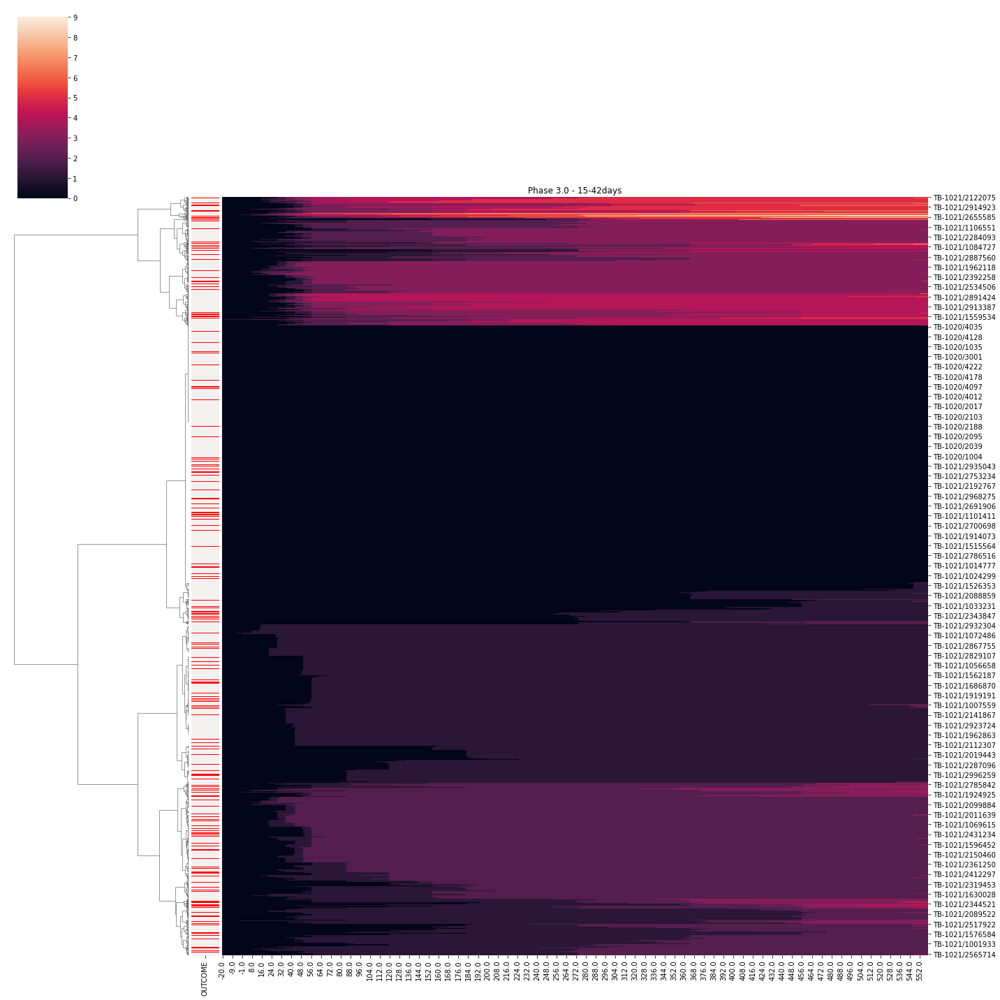

In [405]:
from sklearn.decomposition import PCA
for ttp_cat,isolated_ttp_pos_over_time_cumul in isolated_ttp_pos_cumul_dict.items():
  # get number of non-numeric columns
  n_non_numeric=len(isolated_ttp_pos_over_time_cumul.select_dtypes(include=['object']).columns)

  for phase in [3.0][:]:
    phase_df=isolated_ttp_pos_over_time_cumul[(isolated_ttp_pos_over_time_cumul['PHASE']==str(phase))& \
                                             (~isolated_ttp_pos_over_time_cumul['OUTCOME'].isna())]
    phase_patients=phase_df.index
    if phase == '1':
      stop_day = 14
    if phase == '2':
      stop_day = 60
    if phase == '3':
      stop_day = math.ceil(365*1.5 +10)
    filt = isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric] <= (stop_day)
    filt = np.append(filt, [False,]*n_non_numeric)
    plot_df = phase_df.loc[phase_patients, filt]
    #fig,ax=plt.subplots(1,figsize=(20,15))
   
    #print(sum(plot_df.isna()))
    #print(plot_df.dropna())
    #drop_idx=(plot_df.loc[(plot_df.iloc[:,-1]>50).values,:].index)
    #plot_df=plot_df.loc[~plot_df.index.isin(drop_idx),:]
    #plot_df=plot_df
    colour_pal = sns.light_palette('red', len(phase_df['OUTCOME'].dropna().unique().tolist()))
    lut = dict(zip(phase_df['OUTCOME'].dropna().unique().tolist(), colour_pal))
    row_colors=pd.Series(phase_df['OUTCOME']).map(lut)
    g=sns.clustermap(plot_df,method='ward', figsize=(20, 20),col_cluster=False,row_colors=row_colors)
    g.ax_heatmap.set_title('Phase '+ str(phase) +' - ' +ttp_cat)
    
    #plot_df = phase_df.loc[phase_patients, [60,182]]
    #pca=PCA(2)
    #projected=pca.fit_transform(plot_df)
    
    #sns.jointplot(x=plot_df.loc[:,60],y=plot_df.loc[:,182],hue=phase_df['OUTCOME'],ax=ax)
    #sns.scatterplot(x=projected[:,0],y=projected[:,1],hue=phase_df['OUTCOME'],ax=ax)


<hr>

#### **Plot cumulative isolated MGIT TTP positive samples over therapy time per studies**

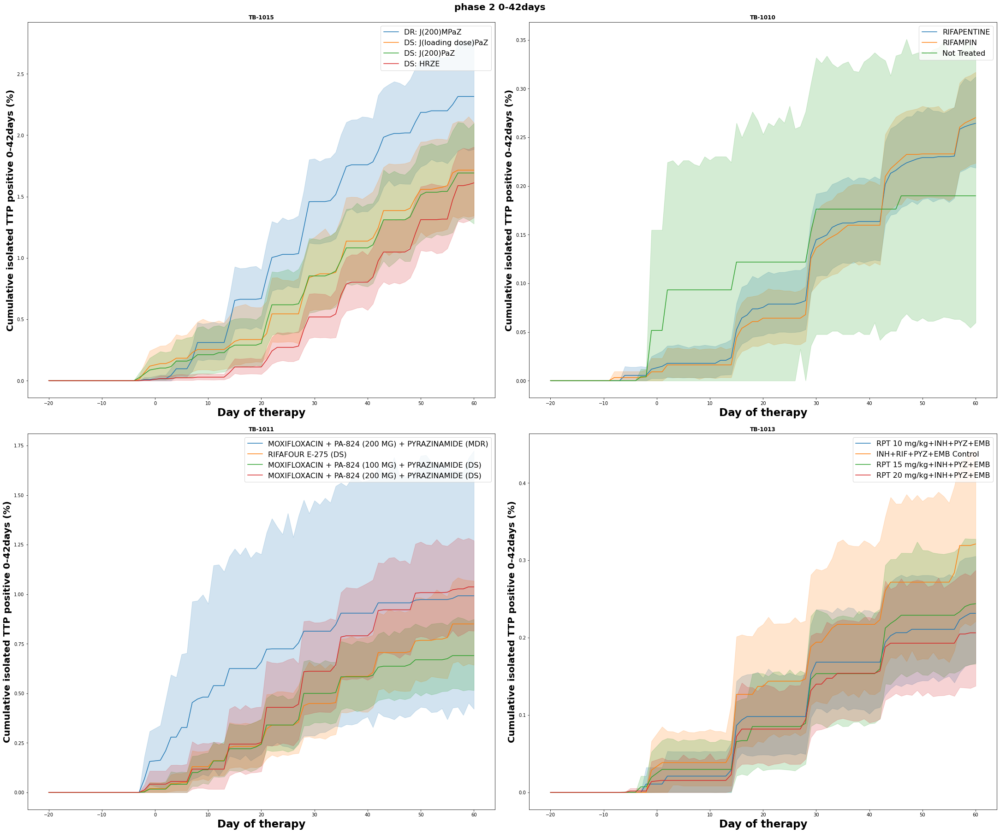

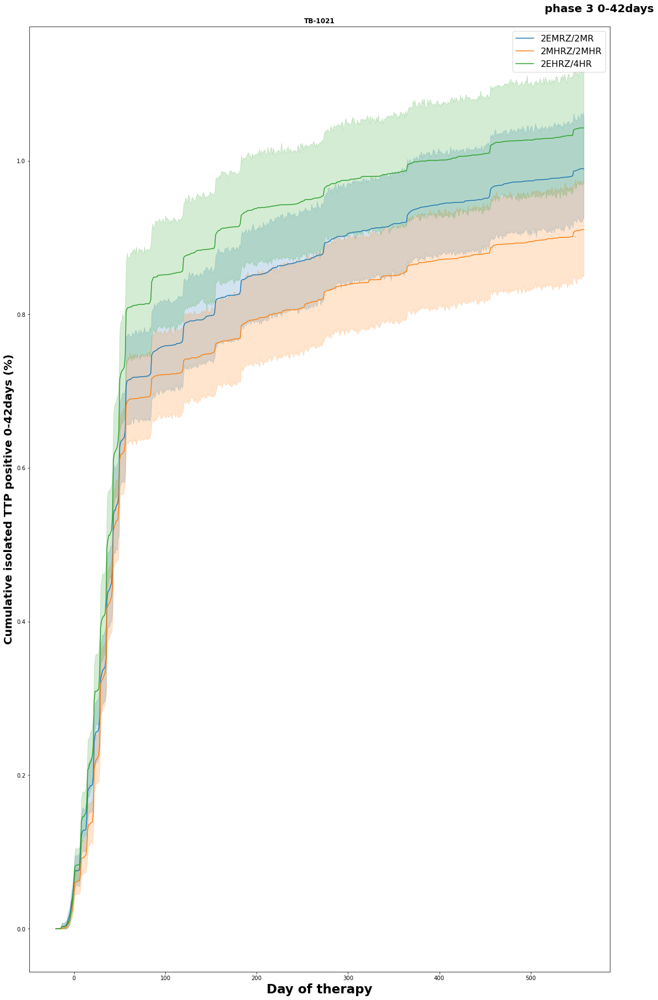

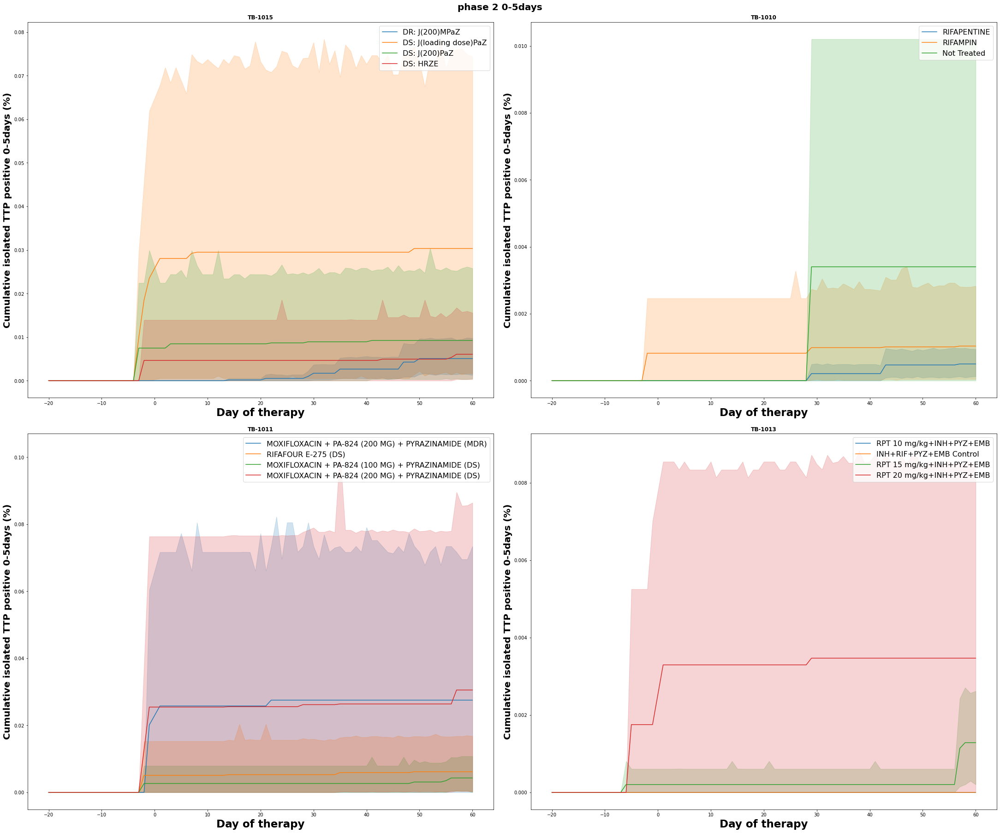

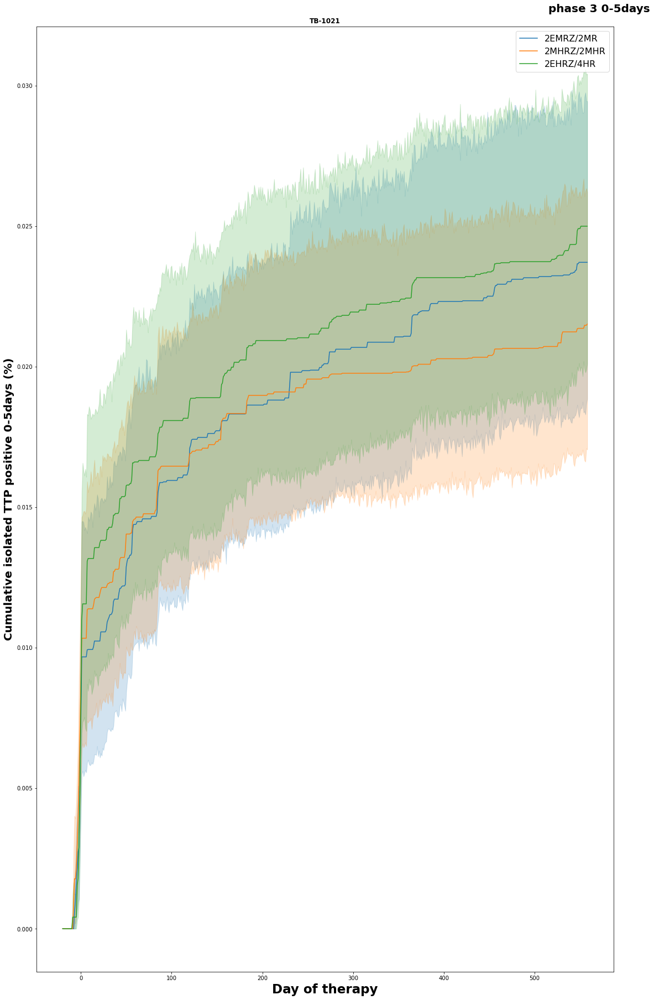

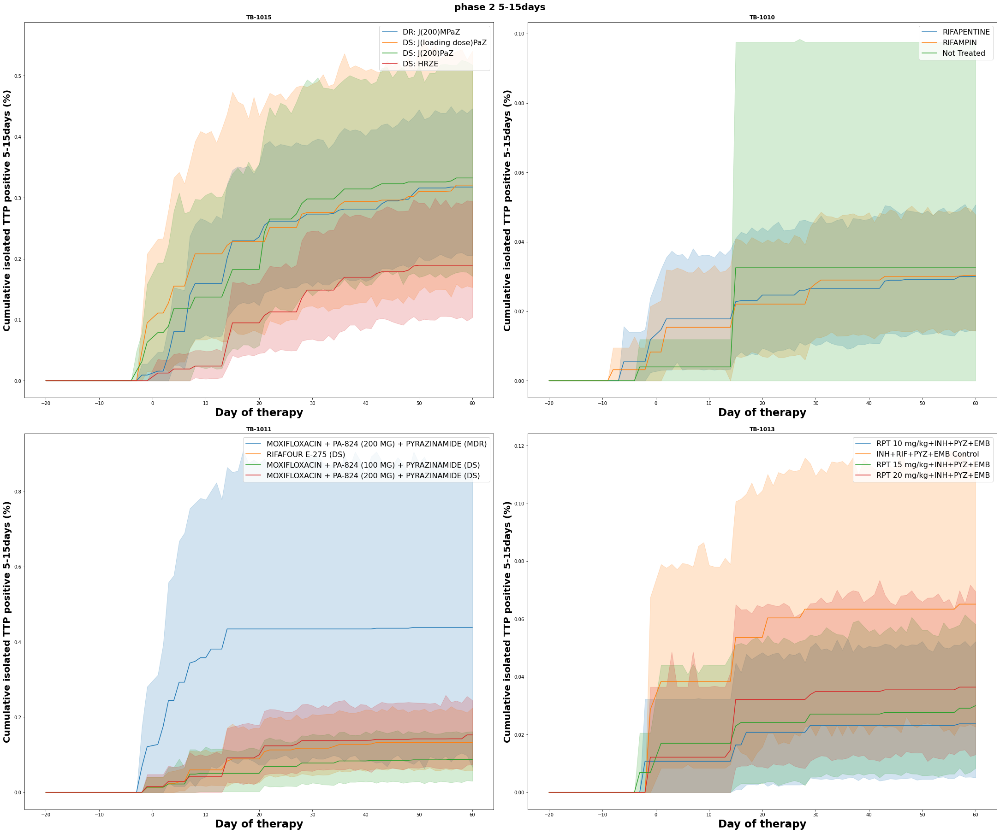

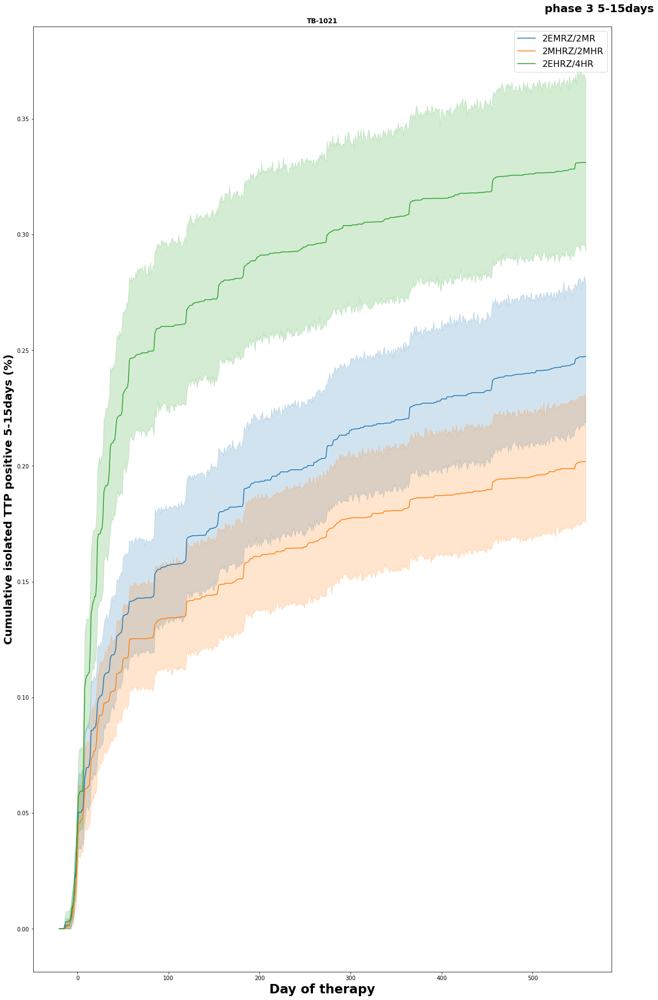

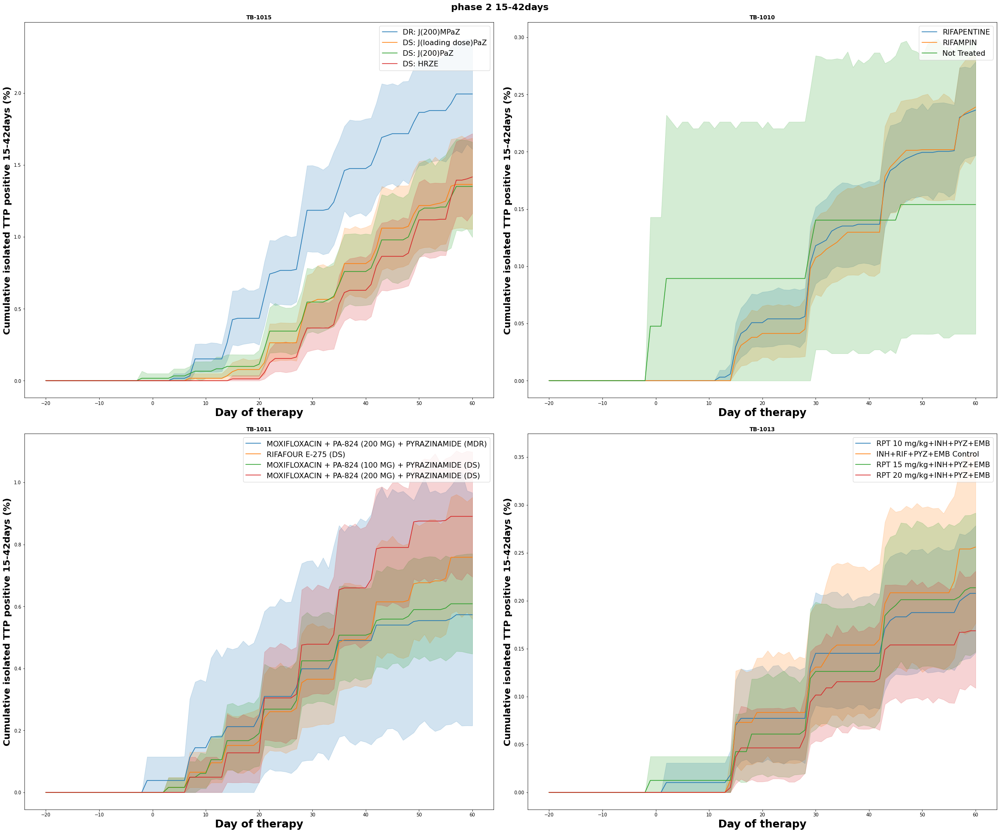

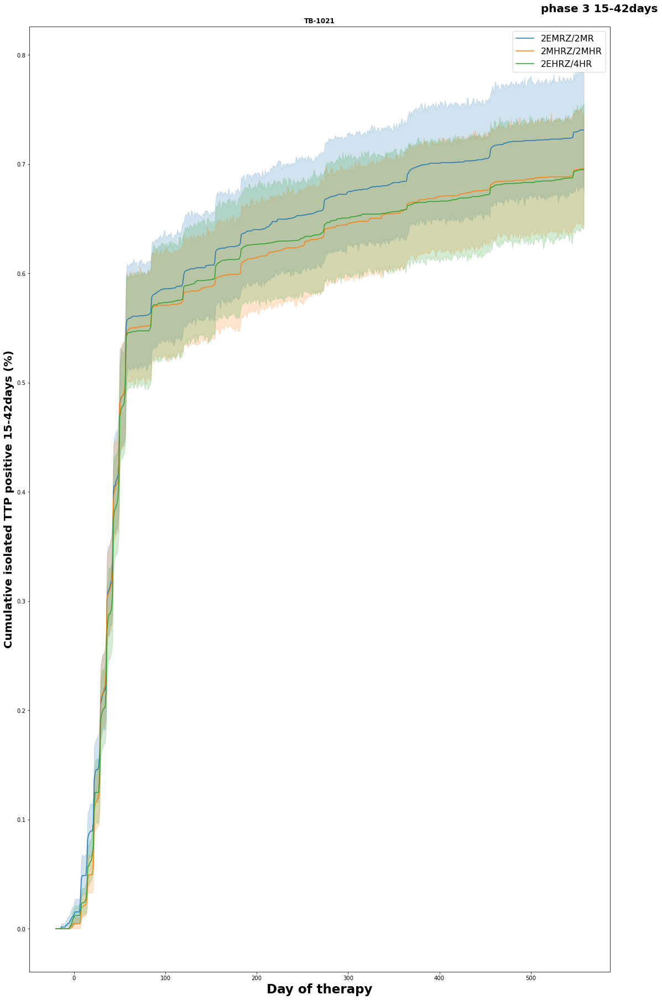

In [167]:

# Plot cumulative isolated MGIT TTP positive samples over therapy time per studies
for ttp_cat in isolated_ttp_pos_cumul_median_dict.keys():
    isolated_ttp_pos_over_time_cumul = isolated_ttp_pos_cumul_median_dict[ttp_cat]
    # get number of non-numeric columns
    n_non_numeric=len(isolated_ttp_pos_over_time_cumul.select_dtypes(include=['object']).columns)

    for phase in [2, 3]:
        phase_df = mb_clean_mgit[(mb_clean_mgit['PHASE'] == phase)&
                                 (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul.index))]

        # Set parameters for subplots
        n_cols = 2
        num_of_plots = len(phase_df['STUDYID'].unique())
        n_rows = math.ceil(num_of_plots/n_cols)
        fig, ax = plt.subplots(1, figsize=(30, 25),constrained_layout=True)
        fig.suptitle('phase '+str(phase)+' '+ttp_cat, fontsize=20, weight='bold')
        n = 0

        for study in phase_df['STUDYID'].unique():
            study_df = phase_df[phase_df['STUDYID'] == study]
            study_patients = study_df['USUBJID'].unique()
            ax = plt.subplot(n_rows, n_cols, n+1)
            n = n+1

            # Subset dataframe to show only days ewhere threapy was applied
            #stop_day = study_df.loc[:, 'MBDY'].max()
            if phase == 1:
                stop_day = 20
            if phase == 2:
               stop_day = 60
            if phase == 3:
                stop_day = math.ceil(365*1.5 +10)
            
            filt = isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric] <= (stop_day)
            filt = np.append(filt, [True,]*n_non_numeric)
            plot_df = isolated_ttp_pos_over_time_cumul.loc[study_patients, filt]

            # Transform dataset for the appropriate plotting format
            plot_df = plot_df.reset_index().melt(id_vars=['index', 'ARM', 'OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY','PHASE'], var_name='day_of_therapy')
            sns.lineplot(data=plot_df, x='day_of_therapy', y='value', hue='ARM', ax=ax)
            ax.set_title(str(study), weight='bold')
            ax.set_ylabel('Cumulative isolated TTP positive '+ttp_cat+' (%)',fontsize=20,weight='bold')
            ax.set_xlabel('Day of therapy',fontsize=23,weight='bold')
            ax.legend(fontsize=16)
    


<HR>

#### VISUALIZE THE NUMBER OF PATIENTS WITH MGIT MEASUREMENTS OVER THE COURSE OF THERAPY FOR A SELECTED STUDY

<AxesSubplot:ylabel='num_of_unique_patients_per_week'>

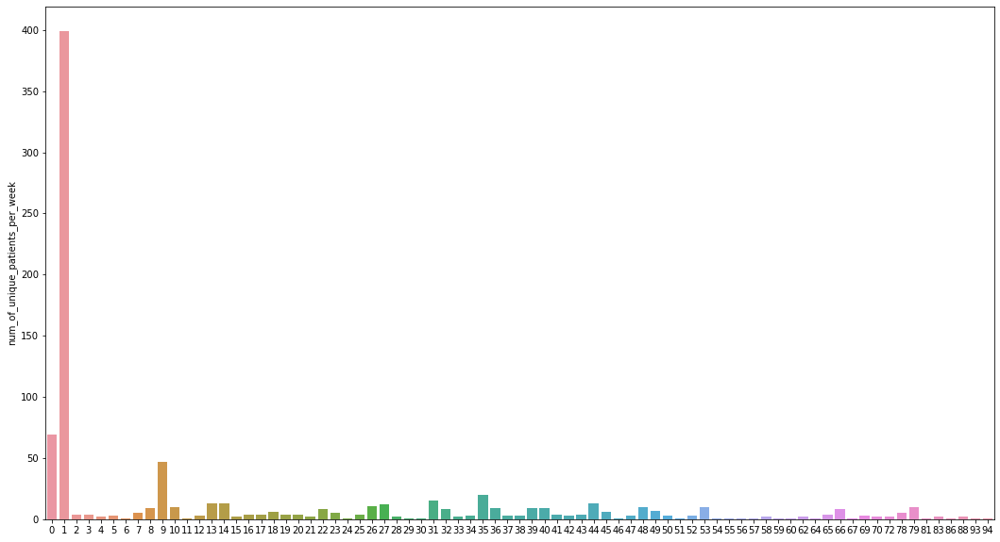

In [348]:
a=mb_clean_mgit[(mb_clean_mgit['STUDYID']=='TB-1020')&(mb_clean_mgit['MBTSTDTL']=='Time to Detection')]
l=[len(a.loc[a['MBDY']==x,'USUBJID'].unique()) for x in a['MBDY'].unique()]
day=pd.DataFrame(data=l,index=a['MBDY'].unique(),columns=['num_of_unique_patients_per_day'])

a['Week']=[math.ceil(x/7) for x in a['MBDY']]
l2=[len(a.loc[a['Week']==x,'USUBJID'].unique()) for x in a['Week'].unique()]
week=pd.DataFrame(data=l2,index=a['Week'].unique(),columns=['num_of_unique_patients_per_week'])


fig,ax=plt.subplots(1,figsize=(18,10))
sns.barplot(data=week,x=week.index,y='num_of_unique_patients_per_week',ax=ax)

<hr>

#### **VISUALIZE TB-1021 ISOLATED MGIT POSITIVE VALUES OVER TIME BY OUTCOME (FAVOURABLE VS. UNFAVOURABLE)**

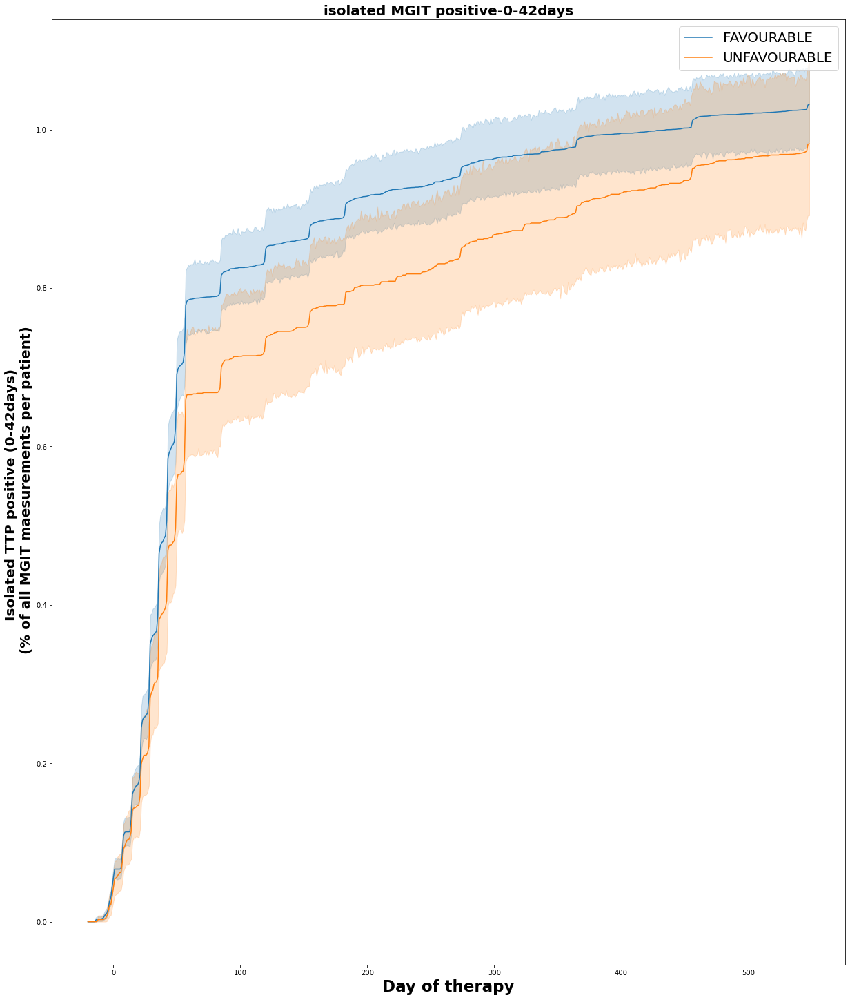

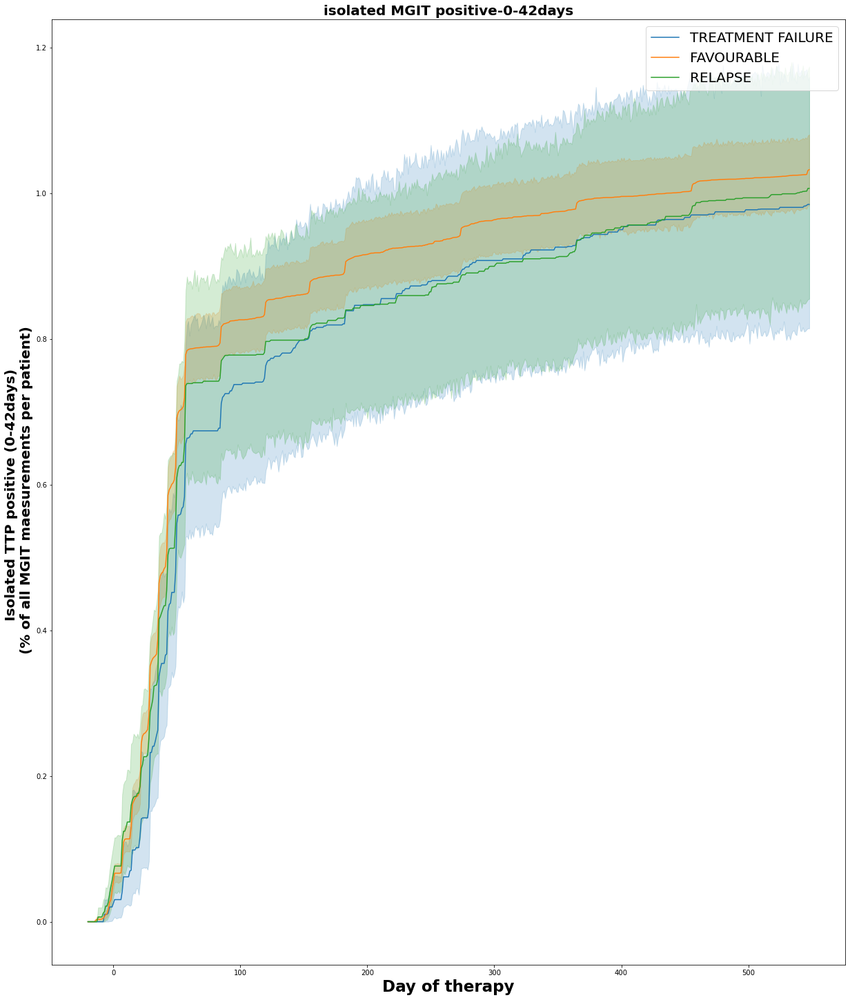

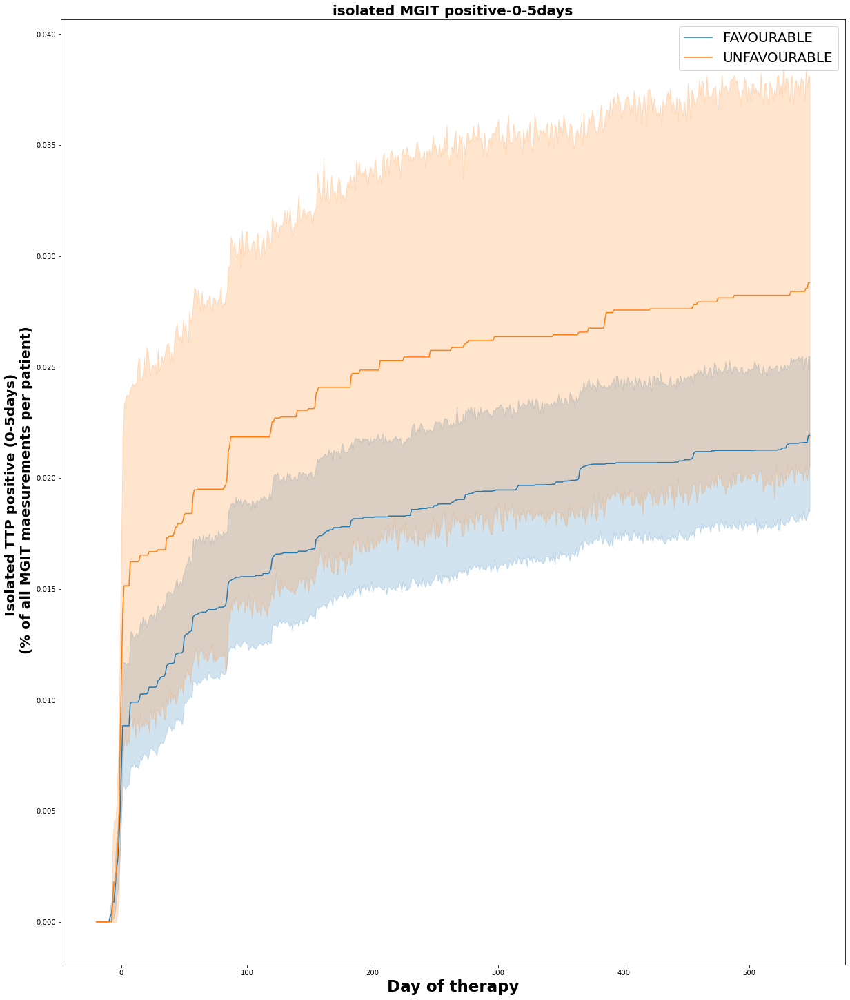

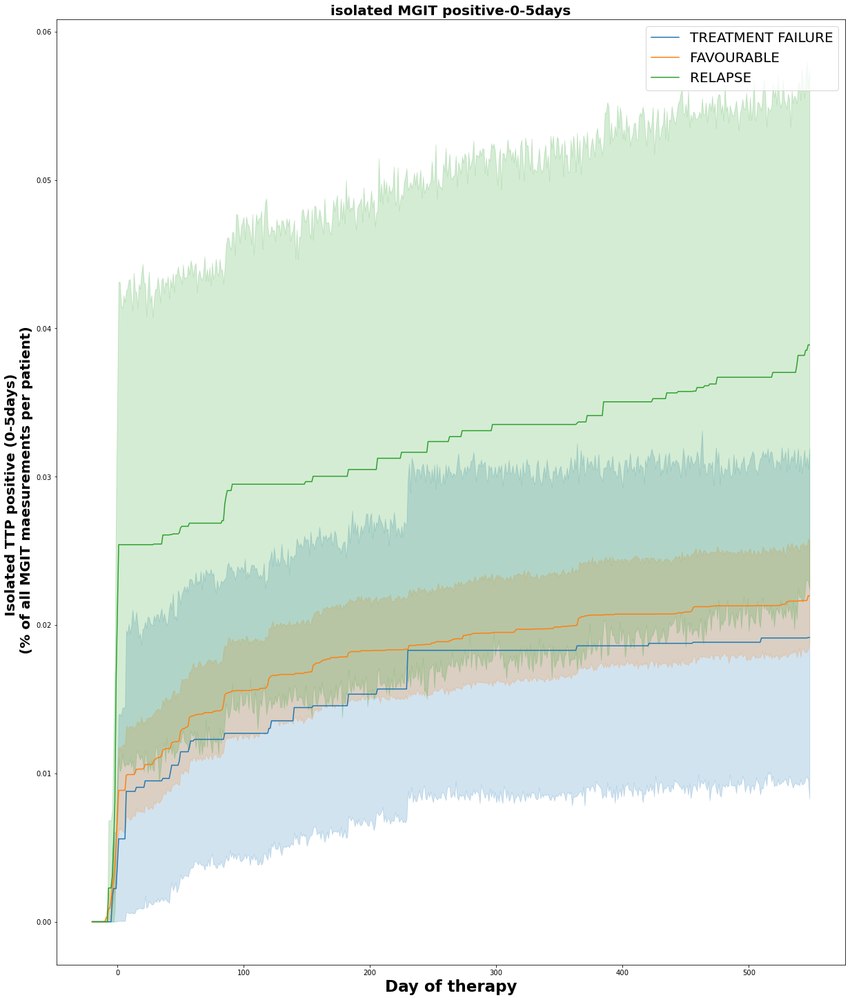

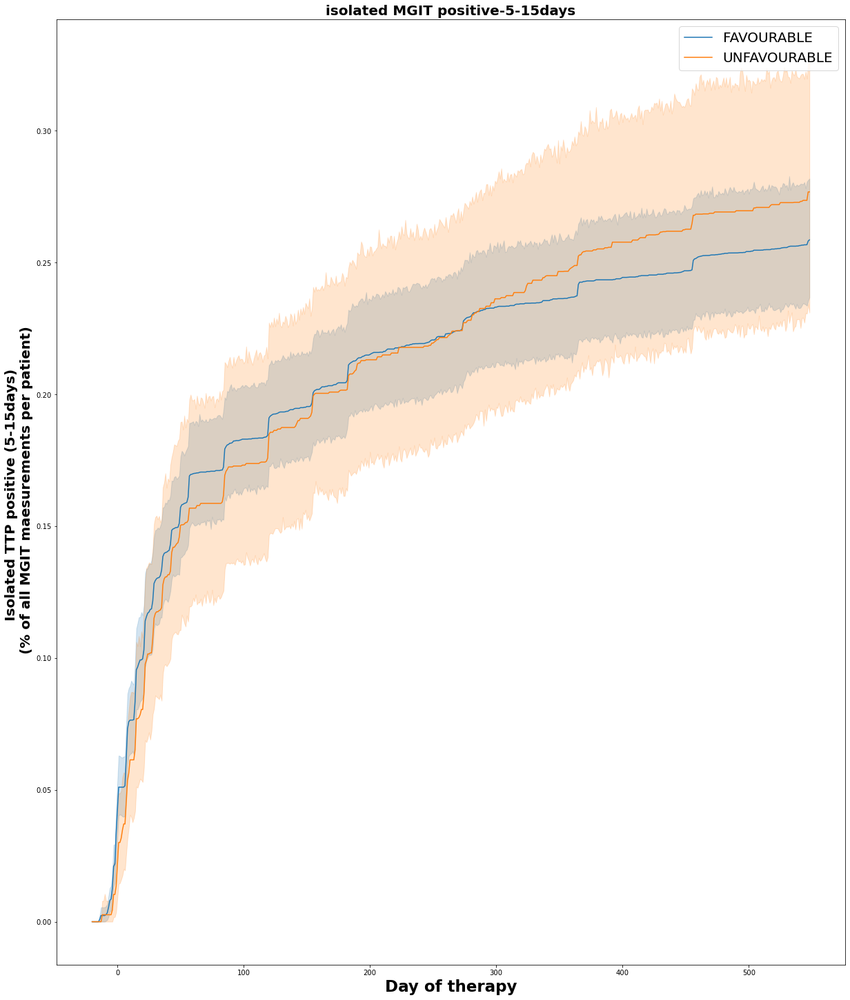

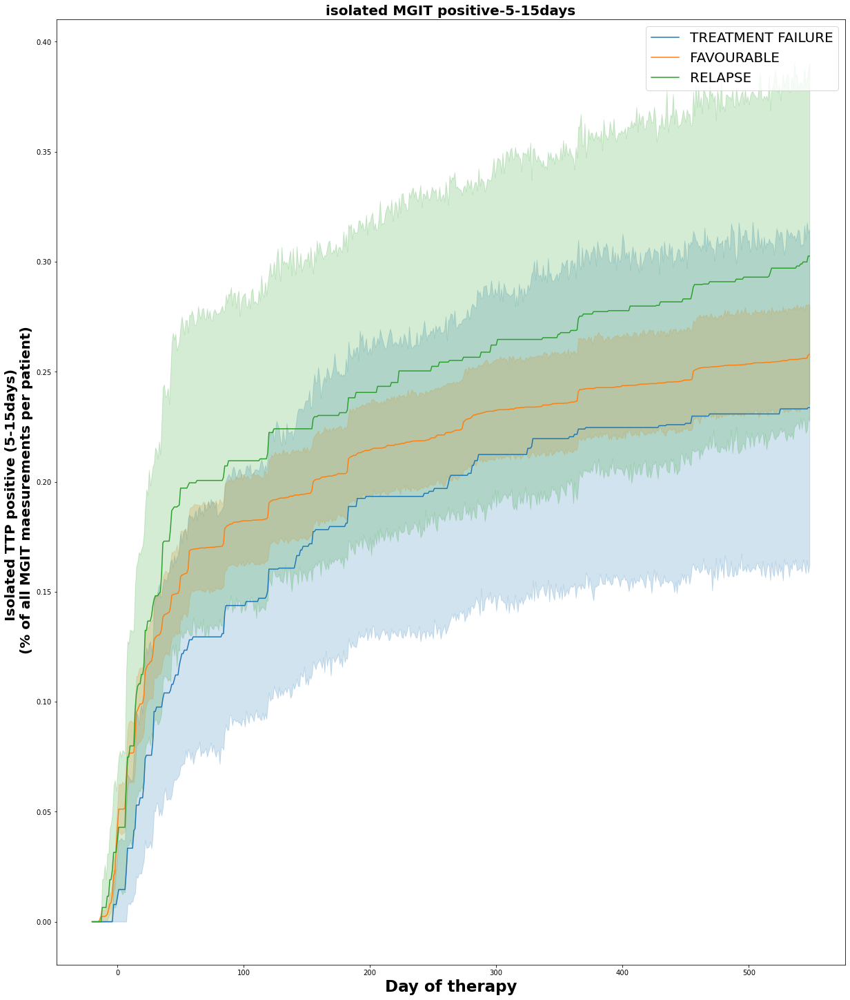

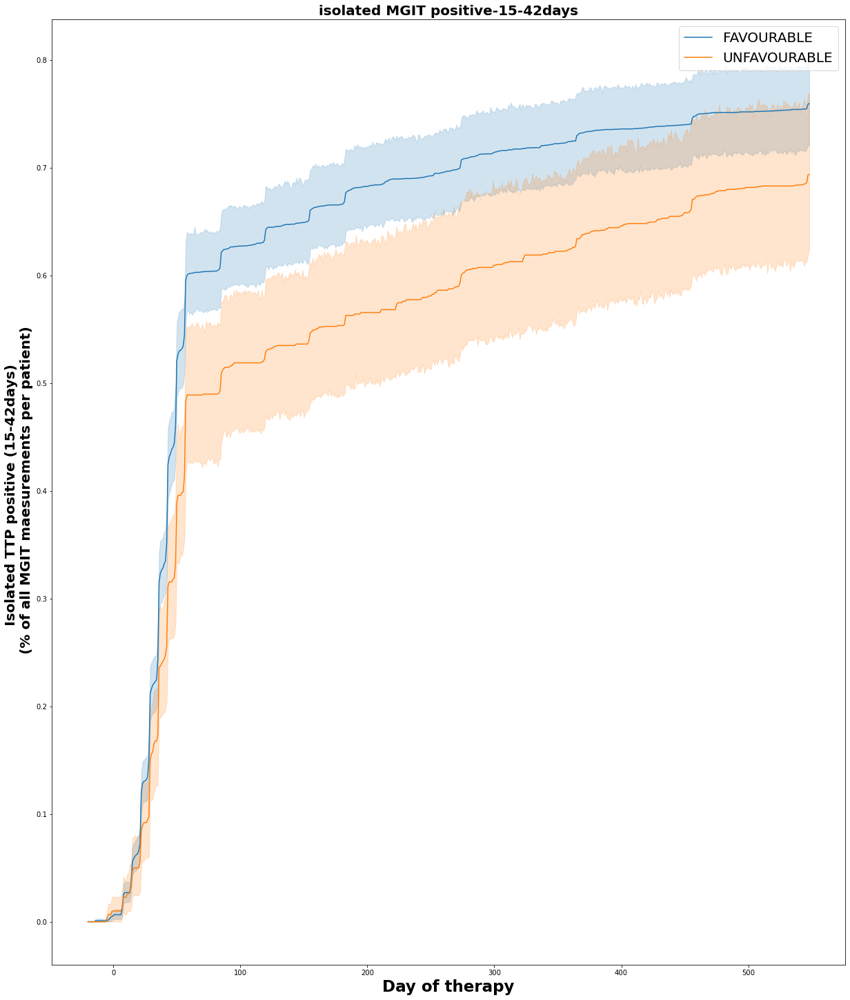

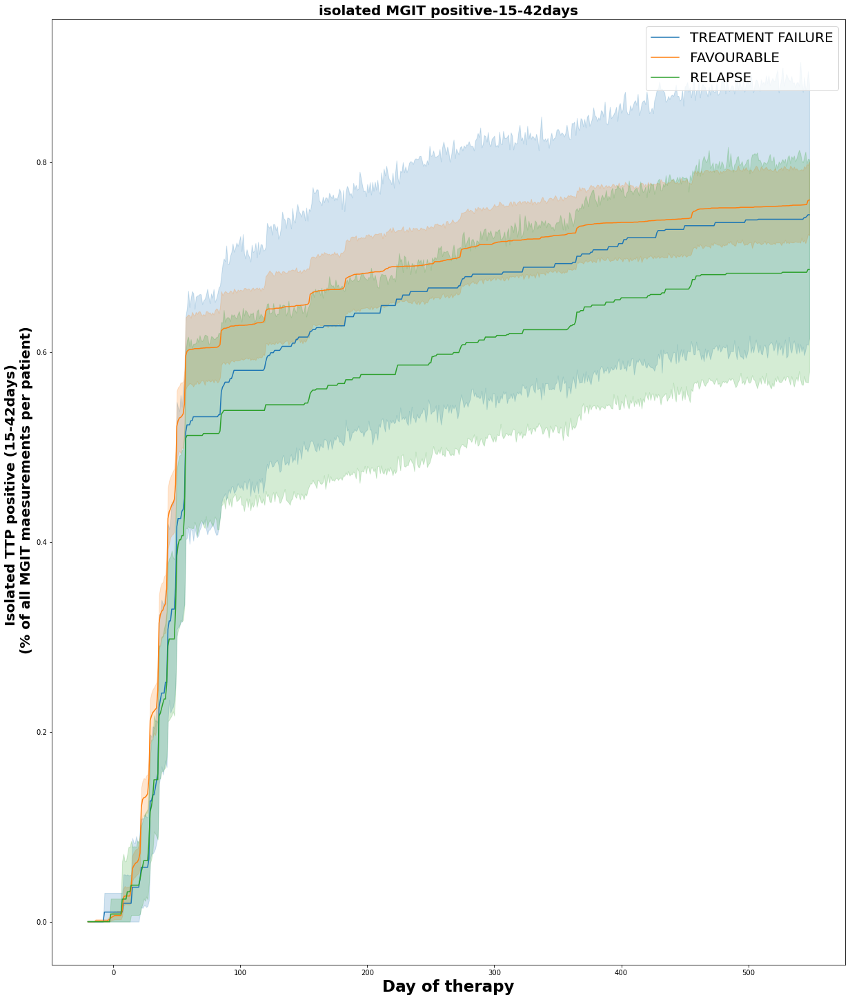

In [157]:
for ttp_cat in isolated_ttp_pos_cumul_median_dict.keys():
    isolated_ttp_pos_over_time_cumul=isolated_ttp_pos_cumul_median_dict[ttp_cat]
    # get number of non-numeric columns
    n_non_numeric=len(isolated_ttp_pos_cumul_median_dict[ttp_cat].select_dtypes(include=['object']).columns)
    for visual_cat in ['OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY']:
        for phase in [3]:
            phase_df=mb_clean_mgit[(mb_clean_mgit['PHASE']==phase)&
                                   (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul.index))]

            # Set parameters for subplots
            n_cols=1
            num_of_plots=len(phase_df['STUDYID'].unique())
            n_rows=math.ceil(num_of_plots/n_cols)
            fig,ax = plt.subplots(1,figsize=(17, 20),constrained_layout=True)
            #fig.suptitle('isolated MGIT pos.-'+str(ttp_cat),fontsize=20,weight='bold')
            n=0

            for study in ['TB-1021']:#phase_df['STUDYID'].unique():
                study_df=phase_df[phase_df['STUDYID']==study]
                study_patients=study_df['USUBJID'].unique()
                ax=plt.subplot(n_rows,n_cols,n+1)
                n=n+1

                # Subset dataframe to show only days ewhere threapy was applied
                stop_day=math.ceil(365*1.5) #study_df['MBDY'].max()#study_df.loc[:,'THERAPY_DURATION'].max()
                #stop_day=study_df.loc[:,'THERAPY_DURATION'].max()+20
                filt=isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric]<=(stop_day)
                filt=np.append(filt,[True,]*n_non_numeric)
                plot_df=isolated_ttp_pos_over_time_cumul.loc[study_patients,filt]
                #plot_df=plot_df[(~plot_df['OUTCOME'].isna())&(~plot_df['UNFAVOURABLE_OUTCOME_CATEGORY'].isna())]

                #Transform dataset for the appropriate plotting format
                plot_df = plot_df.reset_index().melt(id_vars=['index','ARM','OUTCOME','PHASE','UNFAVOURABLE_OUTCOME_CATEGORY'], var_name='day_of_therapy')
                sns.lineplot(data=plot_df,x='day_of_therapy',y='value',hue=visual_cat,ax=ax)
                ax.set_title('isolated MGIT positive-'+str(ttp_cat),fontsize=20,weight='bold')
                ax.set_ylabel("Isolated TTP positive ("+ttp_cat +") \n (% of all MGIT maesurements per patient)",fontsize=20,weight='bold')
                ax.set_xlabel('Day of therapy',fontsize=23,weight='bold')
                ax.legend(fontsize=20) 
            #plt.tight_layout()

<hr>

#### **VISUALIZE ISOLATED MGIT POSITIVES OF FAVOURABLE VS. UNFAVOURABLE OUTCOME SPLIT BY ARMS OF THE PHASE 3 TB-1021 TRIAL**

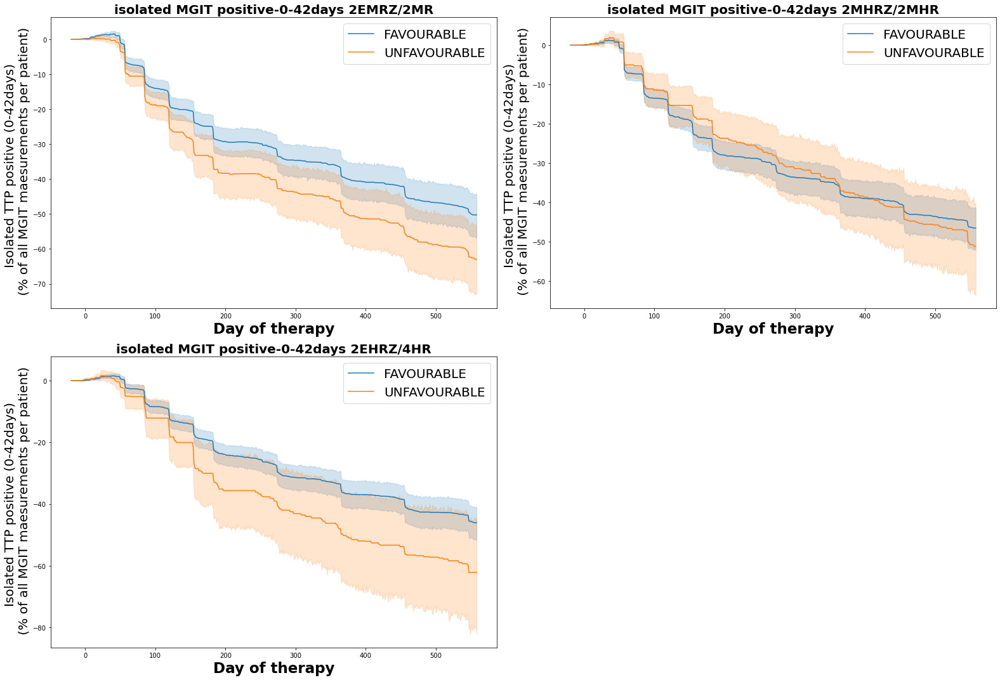

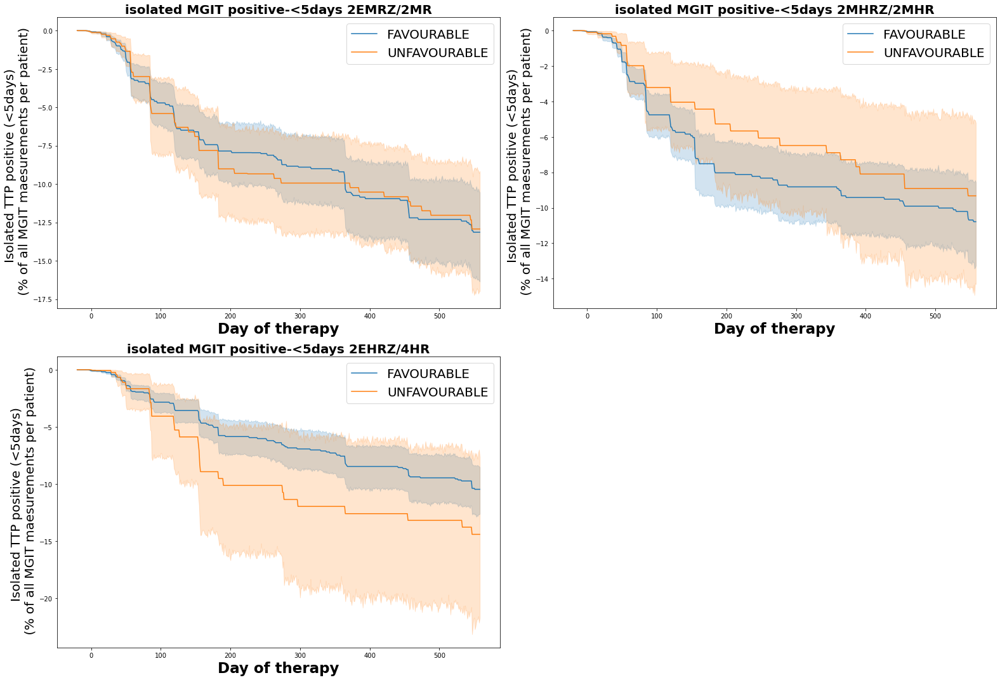

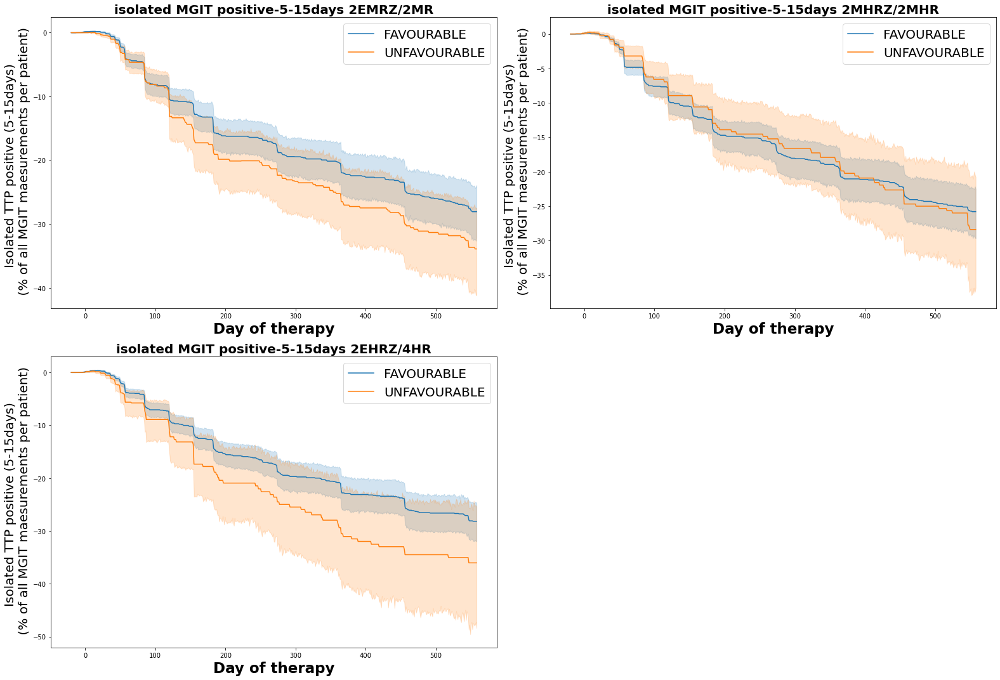

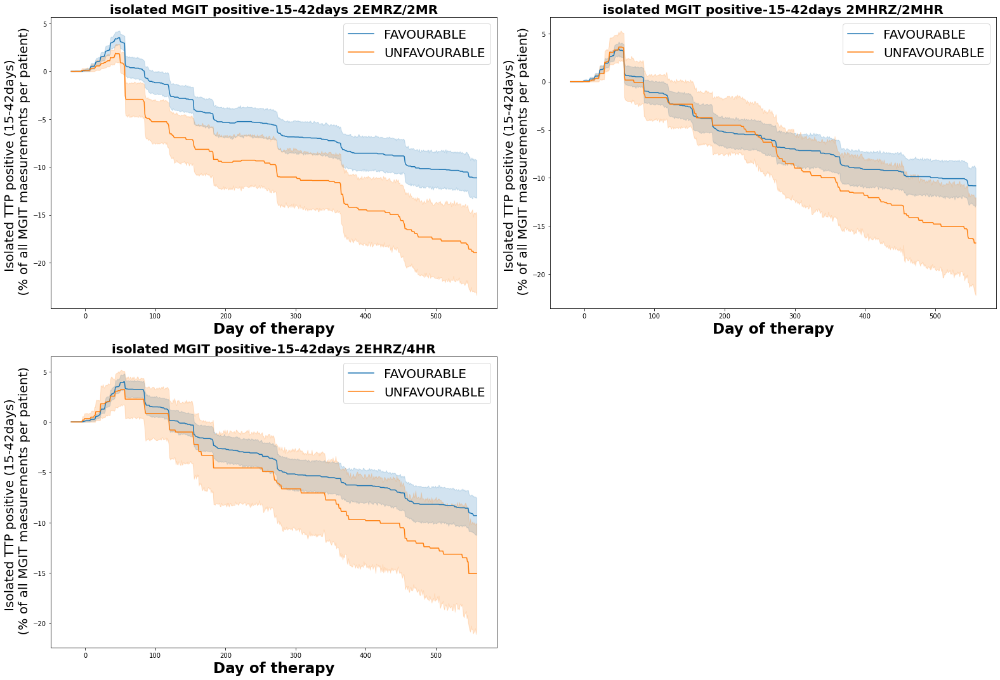

In [129]:
for ttp_cat in list(isolated_ttp_pos_cumul_median_dict.keys())[:]:
    isolated_ttp_pos_over_time_cumul=isolated_ttp_pos_cumul_median_dict[ttp_cat]
    # get number of non-numeric columns
    n_non_numeric=len(isolated_ttp_pos_over_time_cumul.select_dtypes(include=['object']).columns)
    for study in ['TB-1021']:
        
        study_df=mb_clean_mgit[(mb_clean_mgit['STUDYID']==study)&
                               (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul.index))]
        # Set parameters for subplots
        n_cols=2
        num_of_plots=len(study_df['ARM'].unique())
        n_rows=math.ceil(num_of_plots/n_cols)
        fig,ax = plt.subplots(1,figsize=(22, 15),constrained_layout=False)
        #fig.suptitle('isolated MGIT pos.-'+str(ttp_cat),fontsize=20,weight='bold')
        n=0
        for arm in study_df['ARM'].unique():
            arm_df=study_df[study_df['ARM']==arm]
            arm_patients=arm_df['USUBJID'].unique()
            ax=plt.subplot(n_rows,n_cols,n+1)
            n=n+1

            # Subset dataframe to show only days ewhere threapy was applied
            stop_day=math.ceil(365*1.5+10)  # study_df['MBDY'].max()  #study_df.loc[:,'THERAPY_DURATION'].max()
            filt=isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric]<=(stop_day)
            filt=np.append(filt,[True,]*n_non_numeric)
            plot_df=isolated_ttp_pos_over_time_cumul.loc[arm_patients,filt]

        #Transform dataset for the appropriate plotting format
            plot_df = plot_df.reset_index().melt(id_vars=['index','ARM','OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY','PHASE'], var_name='day_of_therapy')
            sns.lineplot(data=plot_df,x='day_of_therapy',y='value',hue='OUTCOME',ax=ax)
            ax.set_title('isolated MGIT positive-'+str(ttp_cat)+ ' '+arm,fontsize=20,weight='bold')
            ax.set_ylabel("Isolated TTP positive ("+ttp_cat +") \n (% of all MGIT maesurements per patient)",fontsize=20)
            ax.set_xlabel('Day of therapy',fontsize=23,weight='bold')
            ax.legend(fontsize=20)
        plt.tight_layout()

<hr>

#### **VISUALIZE ISOLATED MGIT POSITIVES OF ARMS SPLIT BY THE OUTCOME (FAVOURABLE VS. UNFAVOURABLE)OF THE PHASE 3 TB-1021 TRIAL**

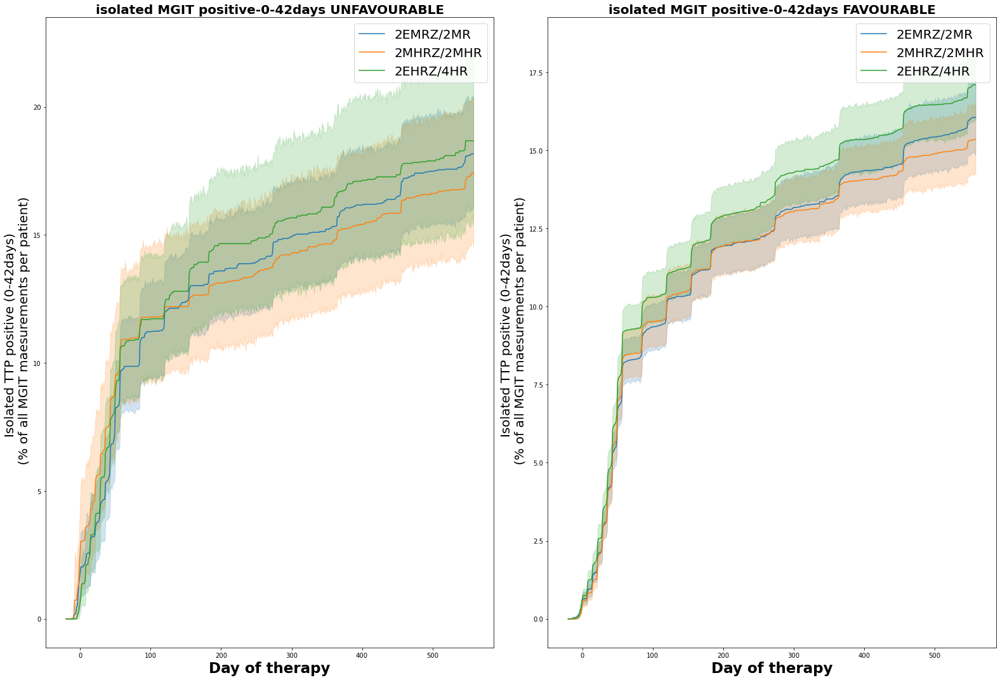

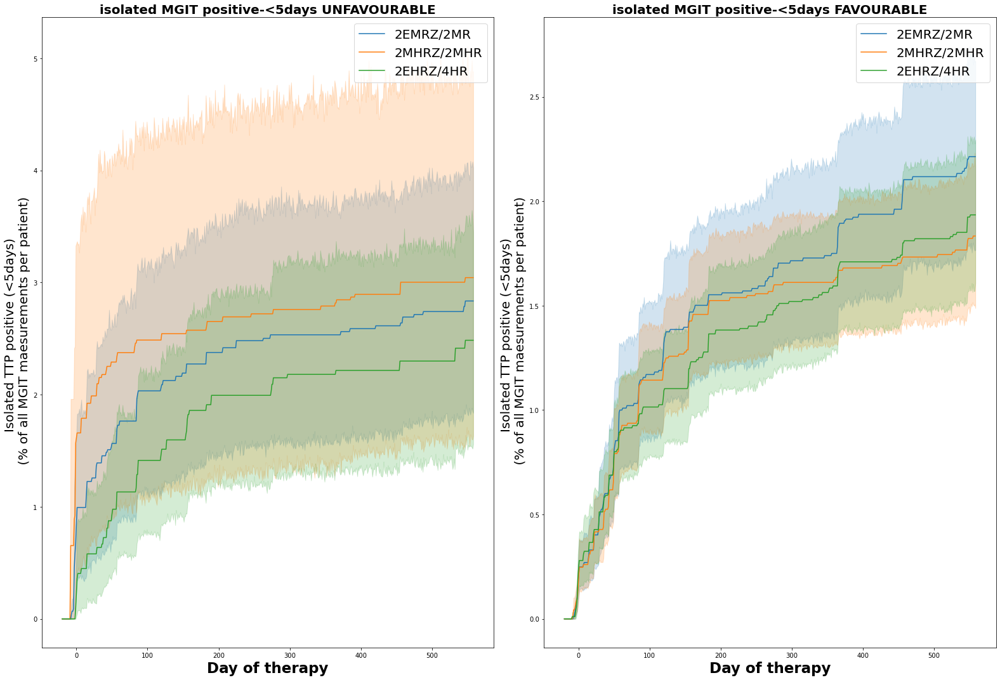

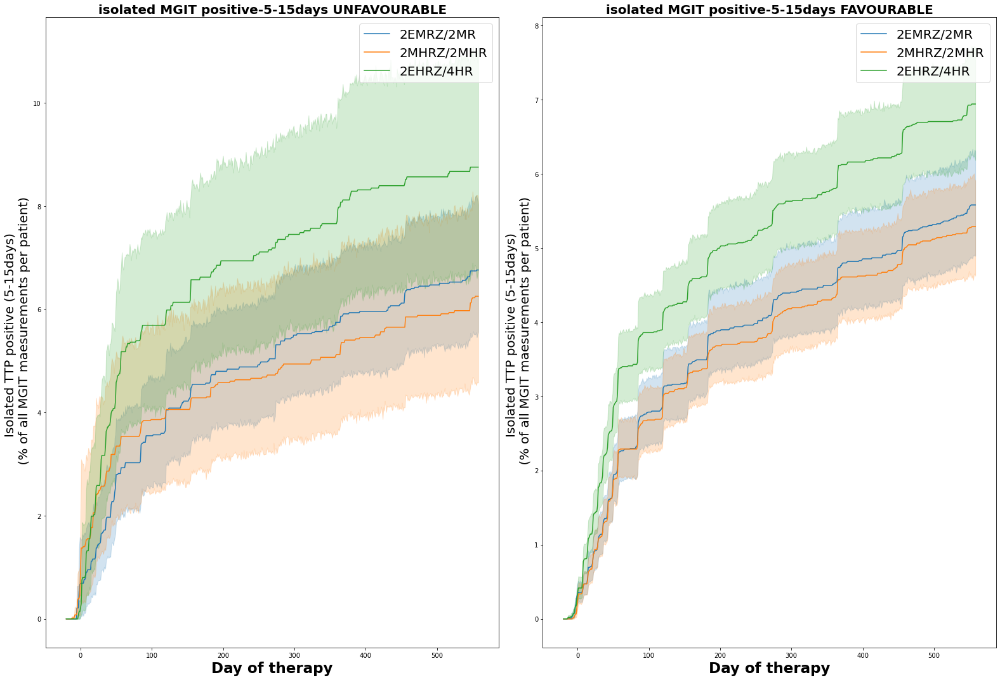

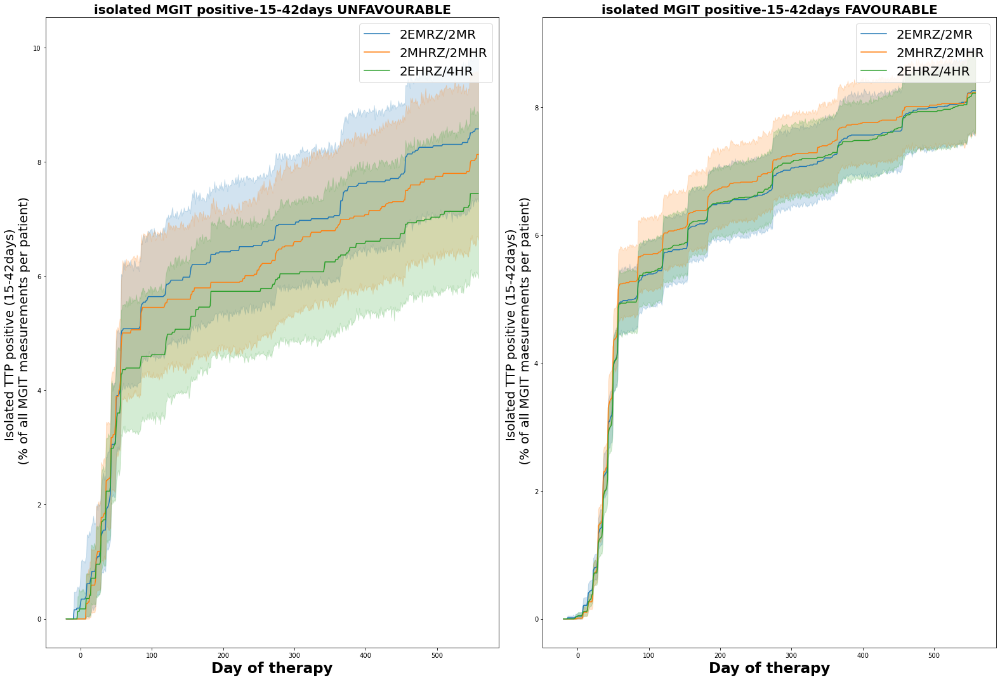

In [524]:
for ttp_cat in list(isolated_ttp_pos_cumul_percentage_dict.keys())[:]:
    isolated_ttp_pos_over_time_cumul=isolated_ttp_pos_cumul_percentage_dict[ttp_cat]
    # get number of non-numeric columns
    n_non_numeric=len(isolated_ttp_pos_cumul_dict[ttp_cat].select_dtypes(include=['object']).columns)

    for study in ['TB-1021']:
        study_df=mb_clean_mgit[(mb_clean_mgit['STUDYID']==study)&
                               (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul.index))]
        
    
        # Set parameters for subplots
        n_cols=2
        num_of_plots=len(phase_df['STUDYID'].unique())
        n_rows=math.ceil(num_of_plots/n_cols)
        fig,ax = plt.subplots(1,figsize=(22, 15),constrained_layout=False)
        #fig.suptitle('isolated MGIT pos.-'+str(ttp_cat),fontsize=20,weight='bold')
        n=0
        for outcome in study_df['OUTCOME'].dropna().unique():
            outcome_df=study_df[study_df['OUTCOME']==outcome]
            outcome_patients=outcome_df['USUBJID'].unique()
            ax=plt.subplot(n_rows,n_cols,n+1)
            n=n+1

            # Subset dataframe to show only days ewhere threapy was applied
            stop_day=stop_day=math.ceil(365*1.5+10) #study_df['MBDY'].max() #study_df.loc[:,'THERAPY_DURATION'].max()
            filt=isolated_ttp_pos_over_time_cumul.columns[:-n_non_numeric]<=(stop_day)
            filt=np.append(filt,[True,]*n_non_numeric)
            plot_df=isolated_ttp_pos_over_time_cumul.loc[outcome_patients,filt]

        #Transform dataset for the appropriate plotting format
            plot_df = plot_df.reset_index().melt(id_vars=['index','ARM','OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY'], var_name='day_of_therapy')
            sns.lineplot(data=plot_df,x='day_of_therapy',y='value',hue='ARM',ax=ax)
            ax.set_title('isolated MGIT positive-'+str(ttp_cat)+ ' '+outcome,fontsize=20,weight='bold')
            ax.set_ylabel("Isolated TTP positive ("+ttp_cat +") \n (% of all MGIT maesurements per patient)",fontsize=20,weight='bold')
            ax.set_xlabel('Day of therapy',fontsize=23,weight='bold')
            ax.legend(fontsize=20)
        plt.tight_layout()

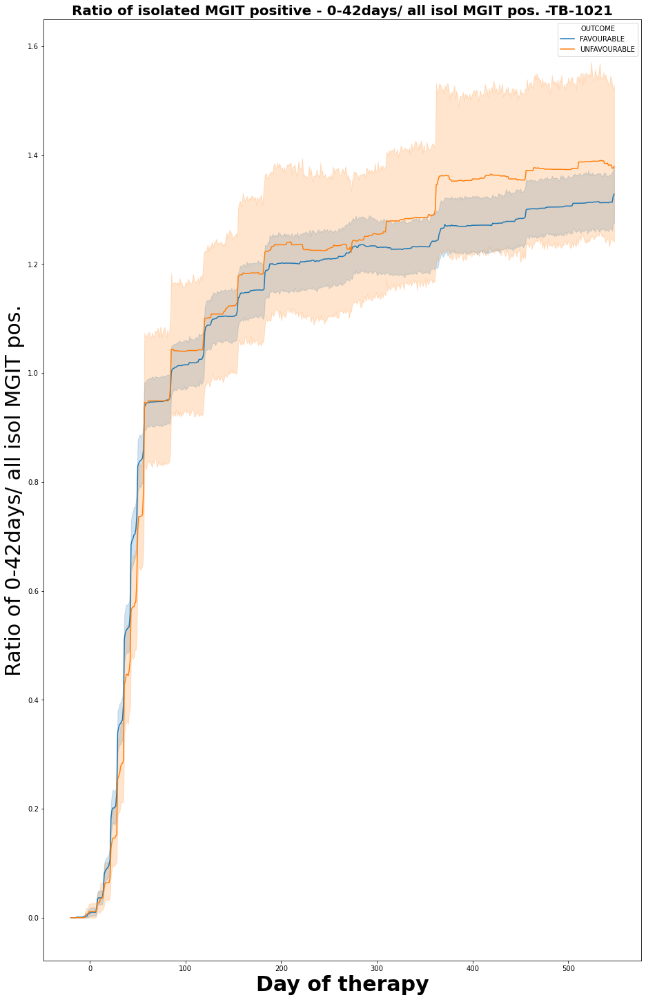

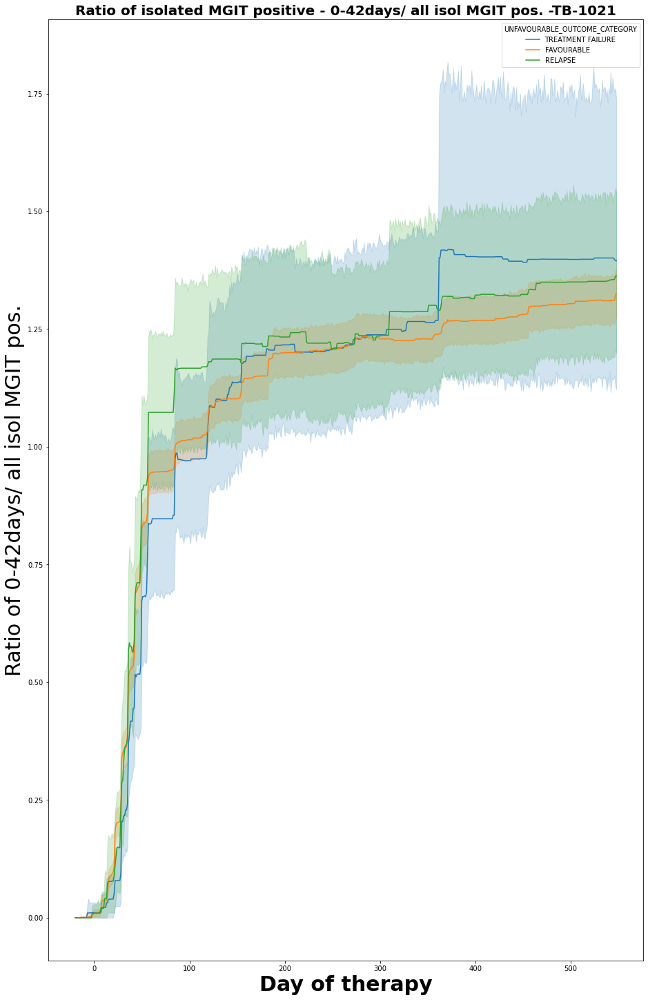

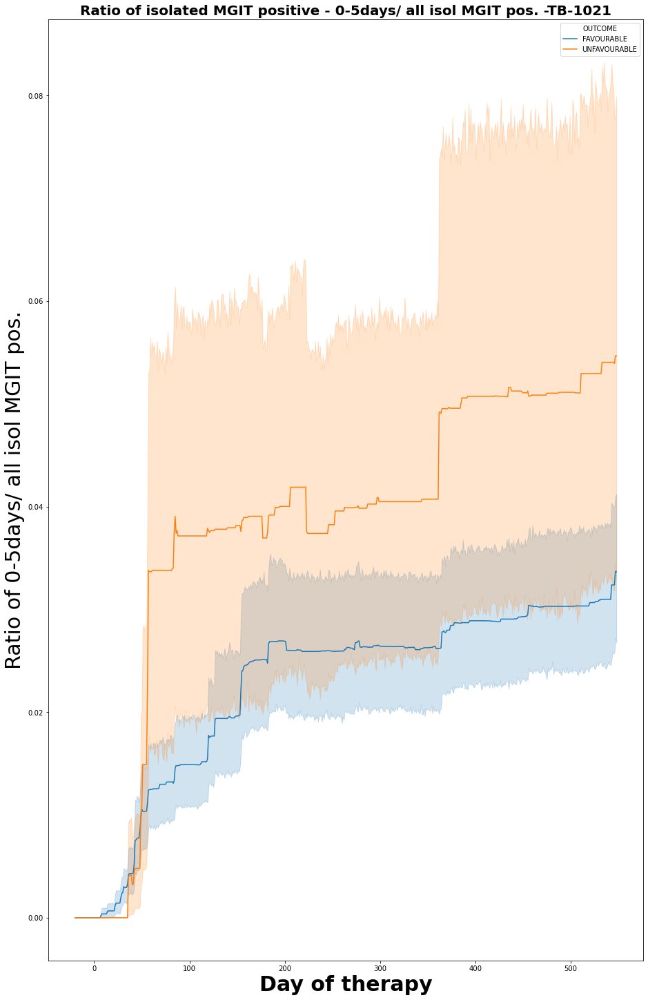

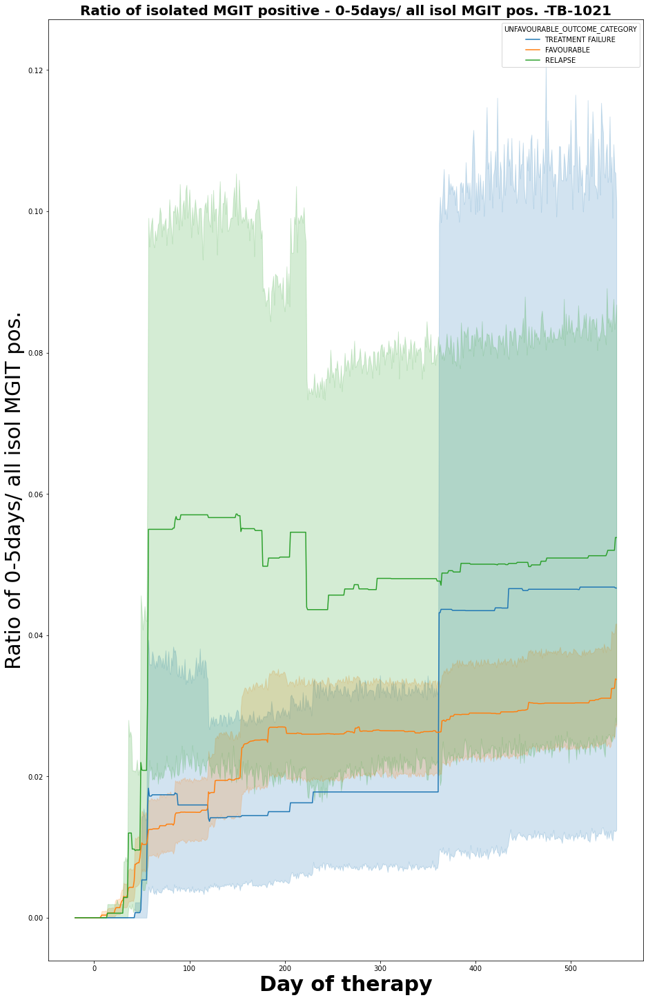

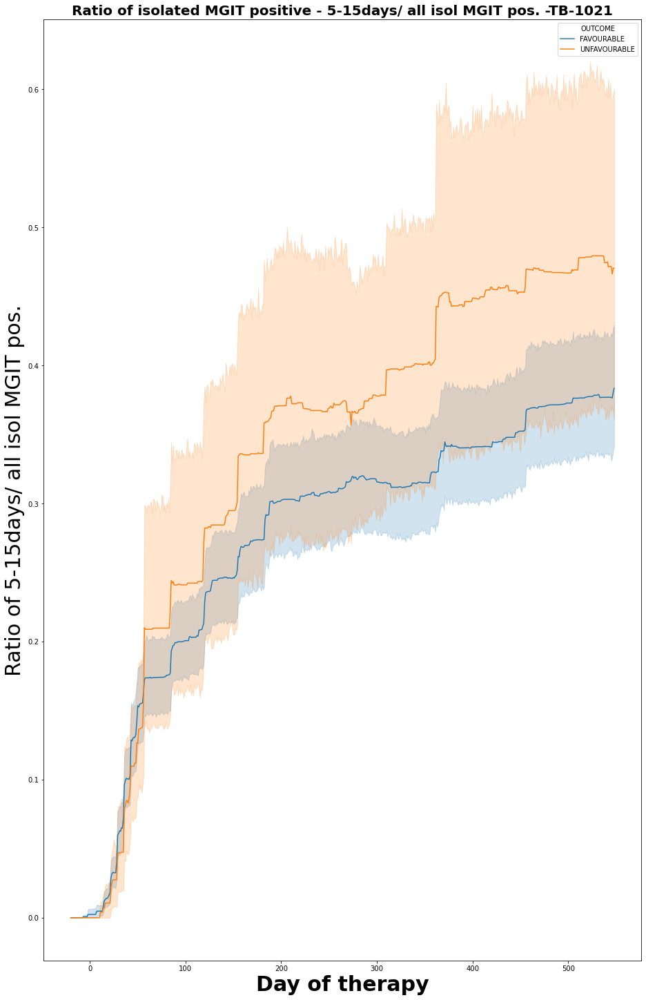

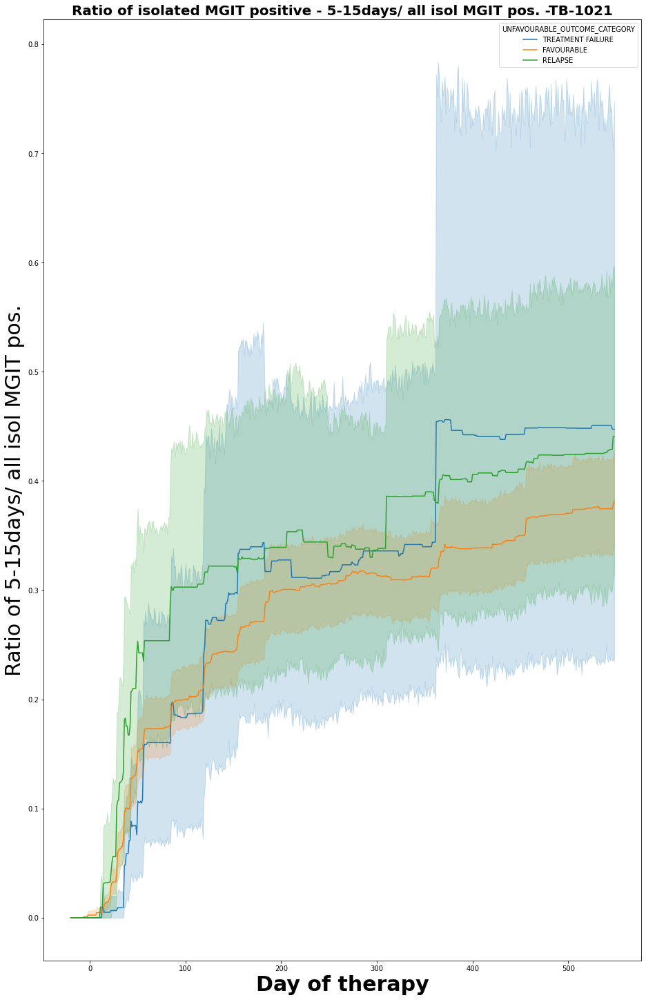

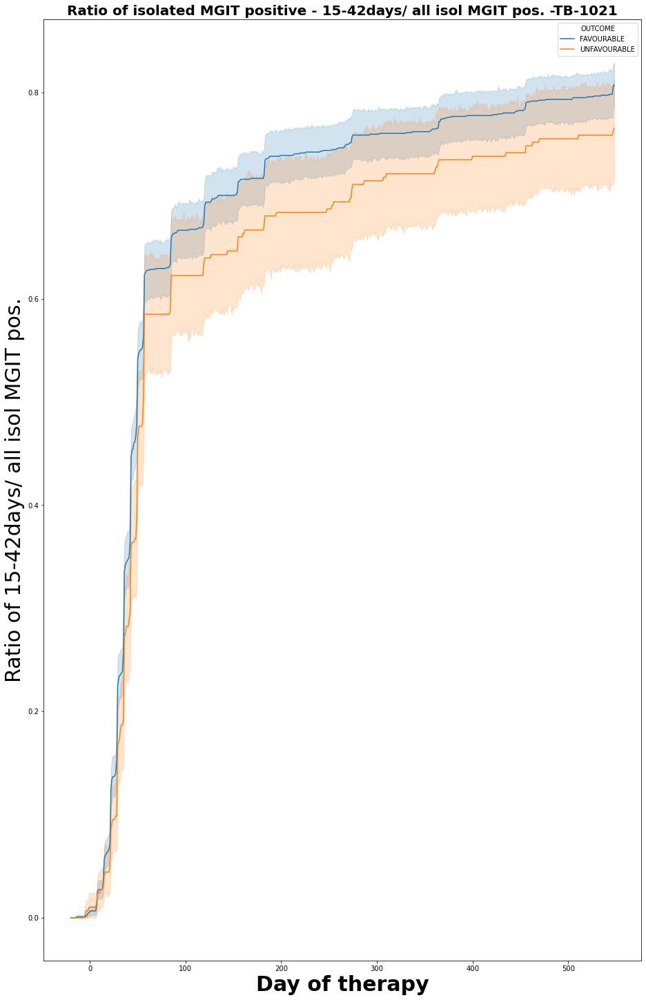

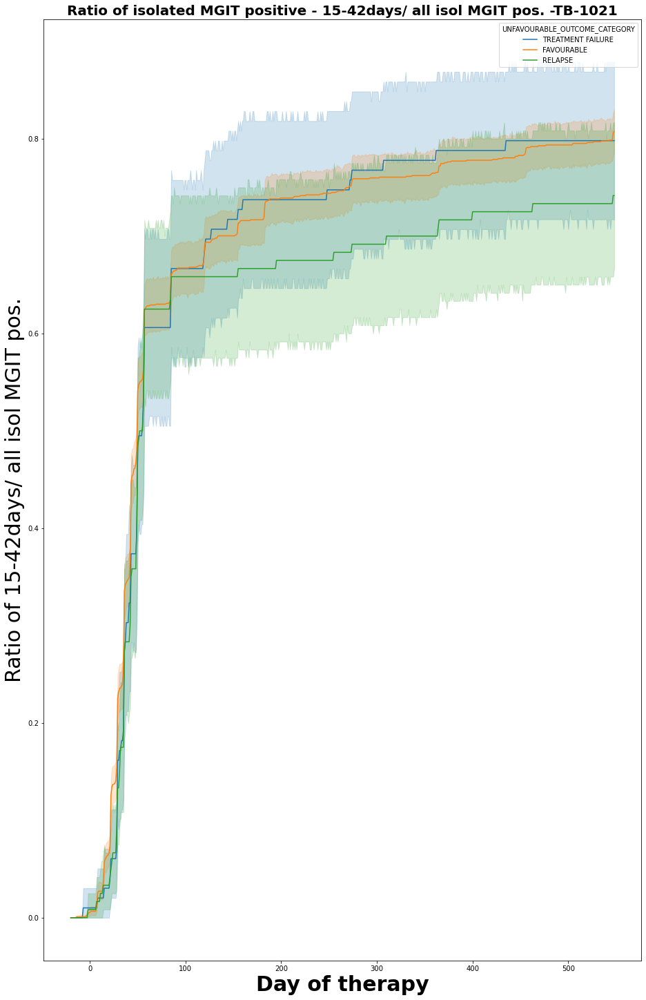

In [410]:
for ttp_cat in list(isolated_ttp_pos_cumul_percentile_ttp_dict.keys())[:]:
    # Calculate ratio of low bacterial load (15-42 days TTP)high bacteria load (<5 days or 5-15 days TTP)
    # get number of non-numeric columns
    isolated_ttp_pos_over_time_cumul_pat = isolated_ttp_pos_cumul_percentile_ttp_dict[ttp_cat].copy()
    
    n_non_numeric=len(isolated_ttp_pos_over_time_cumul_pat.select_dtypes(include=['object']).columns)
    
    isol_pos_cat = isolated_ttp_pos_cumul_percentile_ttp_dict[ttp_cat].copy()
    isol_pos_all = isolated_ttp_pos_cumul_percentile_ttp_dict['15-42days'].copy()

    isolated_ttp_pos_over_time_cumul_pat.iloc[:, :-n_non_numeric] = (isol_pos_cat.iloc[:, :-n_non_numeric].div(isol_pos_all.iloc[:, :-n_non_numeric]))
    
    isolated_ttp_pos_over_time_cumul_pat.iloc[:, :-n_non_numeric] = isolated_ttp_pos_over_time_cumul_pat.iloc[:, :-n_non_numeric].fillna(0)
    isolated_ttp_pos_over_time_cumul_pat.iloc[:, :-n_non_numeric].replace([np.inf, -np.inf], 0, inplace=True)

    for phase in [3]:
        phase_df = mb_clean_mgit[(mb_clean_mgit['PHASE'] == phase)&
                                 (mb_clean_mgit['USUBJID'].isin(isolated_ttp_pos_over_time_cumul_pat.index))]
        phase_patients=phase_df['USUBJID'].unique()
        for visual_cat in ['OUTCOME','UNFAVOURABLE_OUTCOME_CATEGORY']:
            if isolated_ttp_pos_over_time_cumul_pat.loc[phase_patients,visual_cat].isnull().all()==False:
                
            
                # Set parameters for subplots
                n_cols = 2
                num_of_plots = len(phase_df['STUDYID'].unique())
                n_rows = math.ceil(num_of_plots/n_cols)
                fig, ax = plt.subplots(1, figsize=(25, 20), constrained_layout=True)
                #fig.suptitle('isolated MGIT pos.-'+str(ttp_cat)+' '+str(phase),fontsize=20, weight='bold')
                n = 0

                for study in phase_df['STUDYID'].unique():
                    study_df = phase_df[phase_df['STUDYID'] == study]
                    study_patients = study_df['USUBJID'].unique()
                    ax = plt.subplot(n_rows, n_cols, n+1)
                    

                    # Subset dataframe to show only days where therapy was applied
                    # study_df.loc[:,'THERAPY_DURATION'].max()
                    if phase==3:
                        stop_day=math.ceil(365*1.5)
                    else:
                        stop_day=study_df['MBDY'].max() # #
                    filt = isolated_ttp_pos_over_time_cumul_pat.columns[:-n_non_numeric] <= (stop_day)
                    filt = np.append(filt, [True,]*n_non_numeric)
                    plot_df = isolated_ttp_pos_over_time_cumul_pat.loc[study_patients, filt]

                    # Transform dataset for the appropriate plotting format
                    plot_df = plot_df.reset_index().melt(id_vars=['index','ARM','OUTCOME','PHASE','UNFAVOURABLE_OUTCOME_CATEGORY'], var_name='day_of_therapy')
                    if len(plot_df)>0:
                        #plot_df=plot_df[plot_df['value']!=0]
                        #print(plot_df['value'].value_counts())
                        n = n+1
                        sns.lineplot(data=plot_df, x='day_of_therapy',y='value', ax=ax,hue=visual_cat)
                        ax.set_title('Ratio of isolated MGIT positive - '+str(ttp_cat)+'/ all isol MGIT pos. -'+study,fontsize=20, weight='bold')
                        ax.set_ylabel('Ratio of '+str(ttp_cat)+'/ all isol MGIT pos.', fontsize=30)
                        ax.set_xlabel('Day of therapy', fontsize=30, weight='bold')


<hr>

#### KAPLAN MEIER ANALYSIS OF OCCURENCE OF ISOLATED MGIT TTP POSITIVITY PER STUDY
* #### EVENT IS OCCURRENCE OF ISOLATED MGIT TTP POSITIVITY  
* #### SELECT WHICH MGIT TTP POSITIVITY CATEGORY (0-5 DAY, 5-15 DAYS, 15-42 DAYS) THE KM-MODEL IS FITTED TO

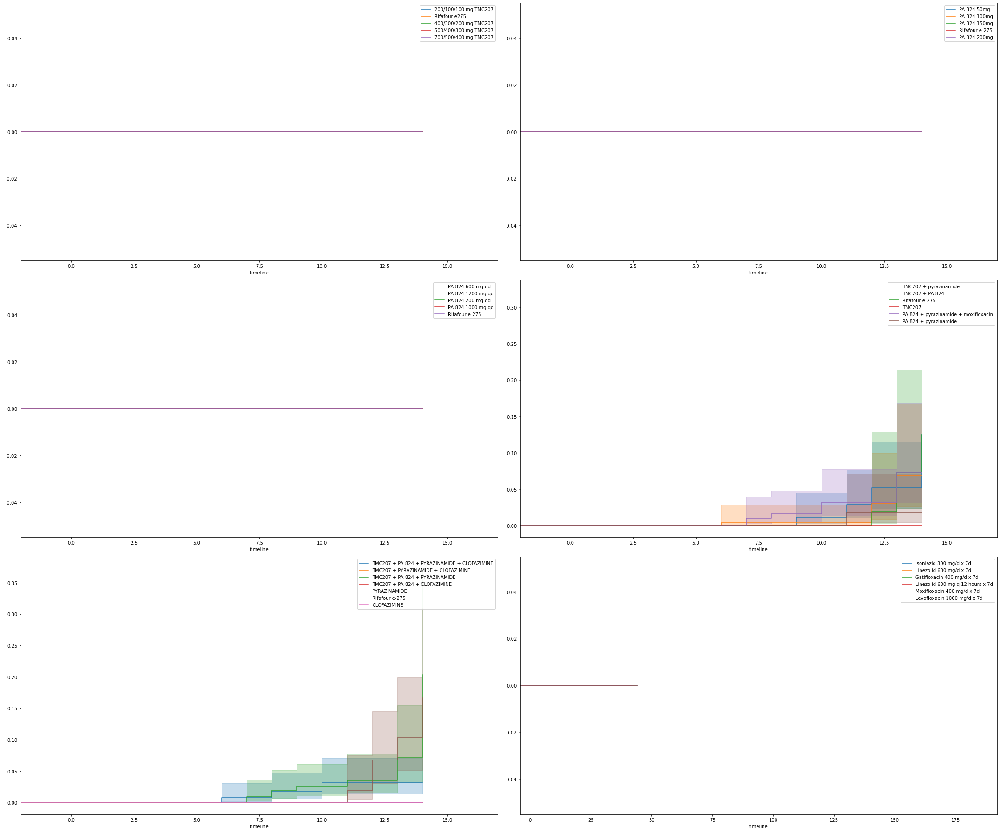

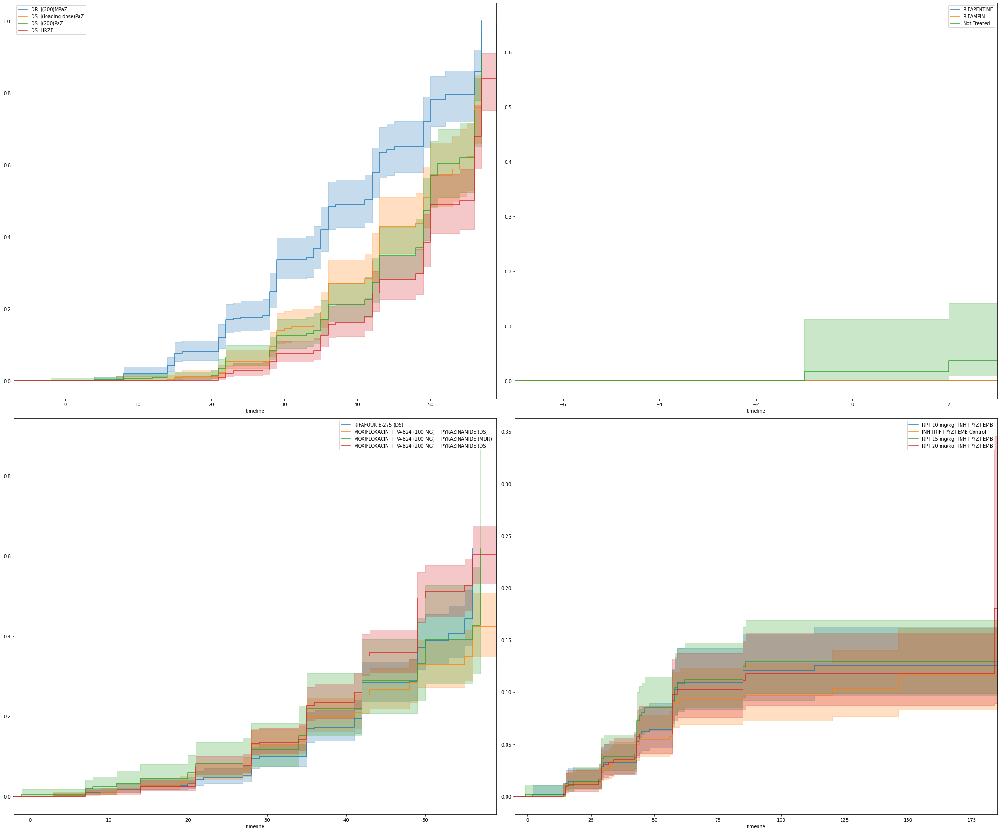

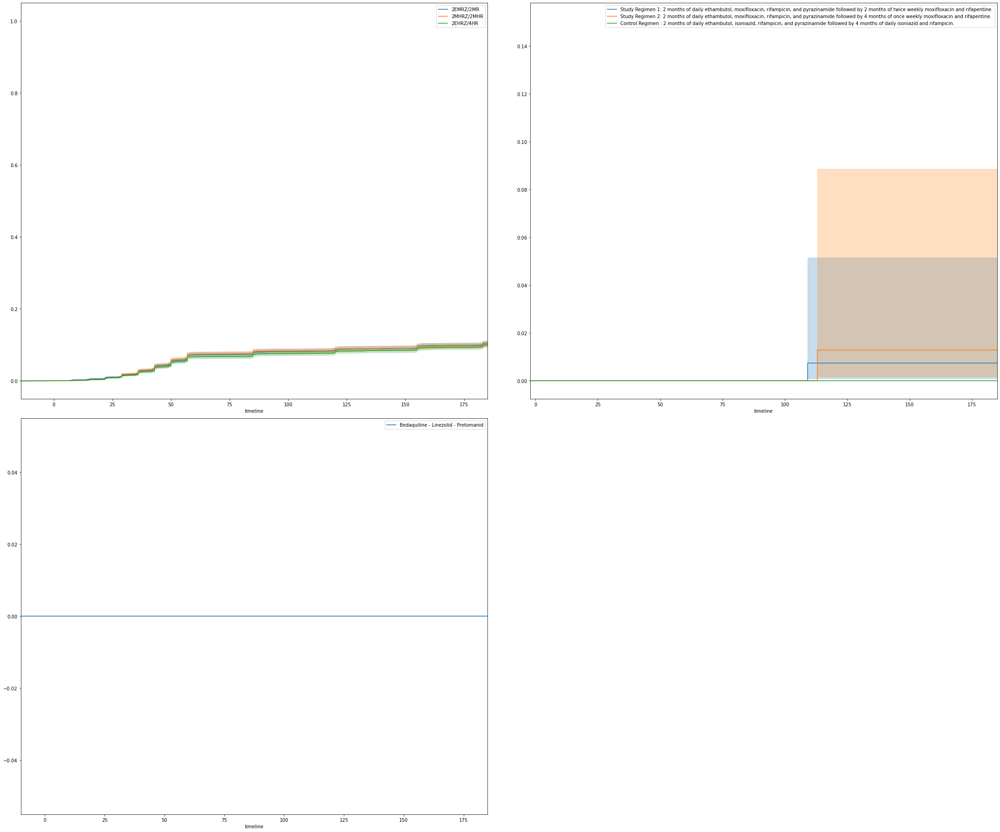

In [152]:
import math
from lifelines import KaplanMeierFitter
km_colnames = ['MB_RESULT', 'SAMPLE_REFID', 'ARM', 'MBDY', 'PHASE',
               'USUBJID', 'STUDYID', 'TTP_CATEGORY', 'THERAPY_DURATION']
kaplan_meier = mb_clean_mgit.loc[mb_clean_mgit['MBTSTDTL']
                                 == 'Time to Detection', km_colnames]

kaplan_meier['isolated MGIT positive'] = [1 if (kaplan_meier.loc[x, 'MB_RESULT'] in [
                                                'isolated MGIT positive']) else 0 for x in kaplan_meier.index]
kaplan_meier['isolated MGIT pos.- <5days'] = [1 if (kaplan_meier.loc[x, 'TTP_CATEGORY'] in [
                                                    'isolated MGIT pos.- <5days']) else 0 for x in kaplan_meier.index]
kaplan_meier['isolated MGIT pos.- 5-15days'] = [1 if (kaplan_meier.loc[x, 'TTP_CATEGORY'] in [
                                                      'isolated MGIT pos.- 5-15days']) else 0 for x in kaplan_meier.index]
kaplan_meier['isolated MGIT pos.- 15-42days'] = [1 if (kaplan_meier.loc[x, 'TTP_CATEGORY'] in [
                                                       'isolated MGIT pos.- 15-42days']) else 0 for x in kaplan_meier.index]
kaplan_meier['isolated MGIT pos.- 0-15days'] = [1 if (kaplan_meier.loc[x, 'TTP_CATEGORY'] in [
                                                      'isolated MGIT pos.- <5days', 'isolated MGIT pos.- 5-15days']) else 0 for x in kaplan_meier.index]

# SELECT WHICH MGIT TTP POSITIVITY CATEGORY WILL BE FITTED FOR i.e. isolated MGIT positive or isolated MGIT pos.- 0-15days
event = 'isolated MGIT pos.- 15-42days'
kmf = KaplanMeierFitter()


for phase in [1, 2, 3]:
    km_phase_df = kaplan_meier[kaplan_meier['PHASE'] == phase]

    # Set parameters for subplots
    n_cols = 2
    num_of_plots = len(km_phase_df['STUDYID'].unique())
    n_rows = math.ceil(num_of_plots/n_cols)
    #fig,ax = plt.subplots(1,figsize=(30, 25))
    fig.suptitle('phase '+str(phase), fontsize=13, weight='bold')
    n = 0
    for study in km_phase_df['STUDYID'].unique():
        km_study_df = km_phase_df[km_phase_df['STUDYID'] == study]
        ax = plt.subplot(n_rows, n_cols, n+1)
        n = n+1
        for arm in km_study_df['ARM'].unique():
            plot_df = km_study_df[km_study_df['ARM'] == arm]
            kmf.fit(plot_df["MBDY"], plot_df[event], label=arm)
            therapy_duration = plot_df['THERAPY_DURATION'].to_list()[0]
            # kmf.plot(ax=ax,ci_show=True,figsize=(30,25))
            kmf.plot_cumulative_density(ax=ax, ci_show=True, figsize=(30, 25))
            ax.set_xlim(min(plot_df["MBDY"]), therapy_duration+3)
    plt.tight_layout()
    plt.show()


In [ ]:
a = 0
# dd=pd.DataFrame()
for phase in [1, 2, 3]:
    phase_df = mb_clean_mgit[mb_clean_mgit['PHASE'] == phase]
    lis = []
    for n, day in enumerate(phase_df['MBDY'].sort_values().unique()):
        d = phase_df[phase_df['MBDY'] == day]
        if len(d) > 10:
            d_df = d['TTP_CATEGORY'].value_counts(normalize=True).to_frame()
            d_df.index = d_df.index.astype(str)
            d_df.columns = [str(day)]
            lis.append(d_df)

    dd = pd.concat(lis, axis=1)
    ddt = dd.T
    ddt['day_of_therapy'] = ddt.index
    if phase == 2:
        ddt = ddt.loc[ddt.index.astype(float) < 60, :]
    if phase == 3:
        ddt = ddt.loc[ddt.index.astype(float) < 181, :]
    #['isolated TTP positive','isolated CFU positive']
    ddt.loc[:, :].plot(kind='bar', stacked=True, figsize=(20, 13))
    ax = plt.gca()
    ax.set_title('phase '+str(phase)+' studies')
    # ax.set_title(arm)
    ax.set_ylabel('Percentage')
    ax.set_xlabel('Day of therapy')
    plt.legend(fontsize=20, loc='center left')

    # Plot correlation between mb result categories
    fig, ax = plt.subplots(1, figsize=(9, 9))
    corr = ddt.corr(method='spearman')
    sns.heatmap(corr, ax=ax, annot=True)


In [ ]:
mb_clean_mgit['MBMETHOD'].value_counts(dropna=False)
#print(mb_clean_mgit[(mb_clean_mgit['STUDYID']=='TB-1015')&(mb_clean_mgit['MBTSTDTL']=='Colony Count')]['MBSTRESN'])
# print(mb_clean_mgit[mb_clean_mgit['MBMETHOD'].str.contains('SOLID',na=False)&(mb_clean_mgit['MBSTRESN'].isna())]['MBSTRESC'].value_counts(dropna=False).to_string())
for method, df in mb_clean_mgit.groupby(by=['MBTSTDTL']):
    print(method)
    print(df[df['MBMETHOD'].str.contains('SOLID', na=False) &
          (df['MBSTRESN'].isna())]['MBSTRESC'].value_counts())
    print('NO GROWTH')


#### **For phase 1,2,3 collect the MGIT TTP measurement of each patient and try to cluster them**

In [121]:
for phase in mb_ttd['PHASE'].unique():
    df = mb_ttd[mb_ttd['PHASE'] == phase]
    ttd_per_pat = pd.DataFrame(
        index=df['MBDY'].unique(), columns=df['USUBJID'].unique())
    # print(float(max(df['VISITNUM'])))
    for pat in df['USUBJID'].unique():
        ttd_vals = df.loc[df['USUBJID'] == pat, ['1-TTP(log10_DAYS)', 'MBDY']]
        # ttd_vals=ttd_vals[ttd_vals['VISITNUM']<99]

        # days_of_meas=df.loc[df['USUBJID']==pat,'MBDY'].to_list()
        # print(ttd_vals)
        ttd_per_pat.loc[ttd_vals['MBDY'].to_list(), str(
            pat)] = ttd_vals['1-TTP(log10_DAYS)'].to_list()
    print(str(phase)+' ready')
    ttd_per_pat = ttd_per_pat.dropna(how='all', axis=0)
    aaa = ttd_per_pat.copy()
    print((ttd_per_pat).shape)
    # ttd_per_pat=ttd_per_pat.dropna()
    dendrogram = sch.dendrogram(sch.linkage(ttd_per_pat, method="ward"))
    plt.title('Dendrogram')
    plt.xlabel('Customers')
    plt.ylabel('Euclidean distances')
    plt.show()
    # sns.clustermap(ttd_per_pat)


3.0 ready
(672, 2505)


ValueError: The condensed distance matrix must contain only finite values.

In [7]:
# Save the 3 datasets
mb_clean.to_csv(dir+'data/ttp_mb_preprocessed.csv', index=None)
mb_cfu_ml.to_csv(dir+'data/ttp_mb_cfu_ml.csv', index=None)
mb_ttd.to_csv(dir+'data/ttp_mb_ttd.csv', index=None)


#### From the mb results outcome dataframe (calculated in create_outcome.ipnyb) extract and add CURED status to the previous 2 df-s

In [6]:
# add cured status to both of the results datasets as  CURED column
for id in mb_cfu_ml['USUBJID'].unique():
    try:
        (mb_oc.loc[mb_oc['USUBJID'] == id, 'CURED'].values[0])
    except IndexError:
        continue
    cured_st = mb_oc.loc[mb_oc['USUBJID'] == id, 'CURED'].values[0]
    df = mb_cfu_ml[mb_cfu_ml['USUBJID'] == id]
    mb_cfu_ml.loc[df.index, 'CURED'] = cured_st

for id in mb_ttd['USUBJID'].unique():
    try:
        (outcome_df.loc[outcome_df['USUBJID'] == id, 'XOSTRESC'].values[0])
    except IndexError:
        continue
    # print(mb_oc.loc[mb_oc['USUBJID']==id,'CURED'].values[0])
    cured_st = outcome_df.loc[outcome_df['USUBJID']
                              == id, 'XOSTRESC'].values[0]
    df = mb_ttd[mb_ttd['USUBJID'] == id]
    mb_ttd.loc[df.index, 'OUTCOME'] = cured_st


<hr>

#### **For phase 1 and 2 collect the paired TTP and CFU/ml values per patient to one dataframe**

In [339]:
# visualize correlation between Colony Count - Time to detection measurement from the same days

# get common ids from both datasets
com_id = list(set(mb_ttd['USUBJID'].unique()) &
              set(mb_cfu_ml['USUBJID'].unique()))
# fig,ax=plt.subplots(figsize=(16,12))
all_df = pd.DataFrame()
for id in com_id[:]:
    cfu_df = mb_cfu_ml[mb_cfu_ml['USUBJID'] == id][[
        'CFU/mL', 'MBDY', 'USUBJID', 'ARM', 'STUDYID', 'PHASE']]
    ttd_df = mb_ttd[mb_ttd['USUBJID'] == id][[
        'MBDY', 'TTP(DAYS)', 'USUBJID', 'ARM', 'STUDYID', 'PHASE']]

    # cfu_df=cfu_df.rename(columns={'MBSTRESN':'log10_CFU/mL'})
    ttd_df = ttd_df.rename(columns={'DAYS': 'TTP(DAYS)'})

    # cfu_df.loc[:,'CFU/ml']=10**cfu_df.loc[:,'log10_CFU/mL']
    # ttd_df.loc[:,'DAYS']=10**ttd_df.loc[:,'1-log10_DAYS']

    cured_st = mb_oc.loc[mb_oc['USUBJID'] == id, 'CURED'].values[0]

    cfu_df_mean = cfu_df.groupby('MBDY').mean()
    ttd_df_mean = ttd_df.groupby('MBDY').mean()

    cfu_df_mean['SUBJECT_ID'] = cfu_df['USUBJID'].values[0]
    cfu_df_mean['ARM'] = cfu_df['ARM'].values[0]
    cfu_df_mean['STUDYID'] = cfu_df['STUDYID'].values[0]
    cfu_df_mean['PHASE'] = cfu_df['PHASE'].values[0]

    ttd_df_mean['SUBJECT_ID'] = ttd_df['USUBJID'].values[0]
    ttd_df_mean['ARM'] = ttd_df['ARM'].values[0]
    ttd_df_mean['STUDYID'] = ttd_df['STUDYID'].values[0]
    ttd_df_mean['PHASE'] = ttd_df['PHASE'].values[0]

    cfu_df_mean['DAY_OF_THERAPY'] = cfu_df_mean.index
    ttd_df_mean['DAY_OF_THERAPY'] = ttd_df_mean.index
    # cfu_df_mean.rename_axis('DAY_OF_THERAPY')
    # ttd_df_mean.rename_axis('DAY_OF_THERAPY')

    df = pd.merge(cfu_df_mean, ttd_df_mean, on=[
                  'DAY_OF_THERAPY', 'ARM', 'SUBJECT_ID', 'STUDYID', 'PHASE'], how='inner')
    all_df = all_df.append(df)

    # sns.scatterplot(data=df,x='log10_CFU/mL',y='1-log10_DAYS',ax=ax,s=8)
    # ax.set_title('')
    # sns.lineplot(data=cfu_df,x='MBDY',y='log10_CFU/mL',ax=ax1)
    # sns.lineplot(data=ttd_df,x='MBDY',y='DAYS',ax=ax2)

all_df['log10_CFU/mL'] = np.log10(all_df['CFU/mL']+1)
all_df['1-TTP(DAYS)'] = (43)-(all_df['TTP(DAYS)'])
all_df['log10[1-TTP(DAYS)]'] = np.log10(44-all_df['TTP(DAYS)'])
all_df = all_df.reset_index(drop=True)


In [291]:
all_df.to_csv(dir+'data/patients_with_cfu_ttp.csv')


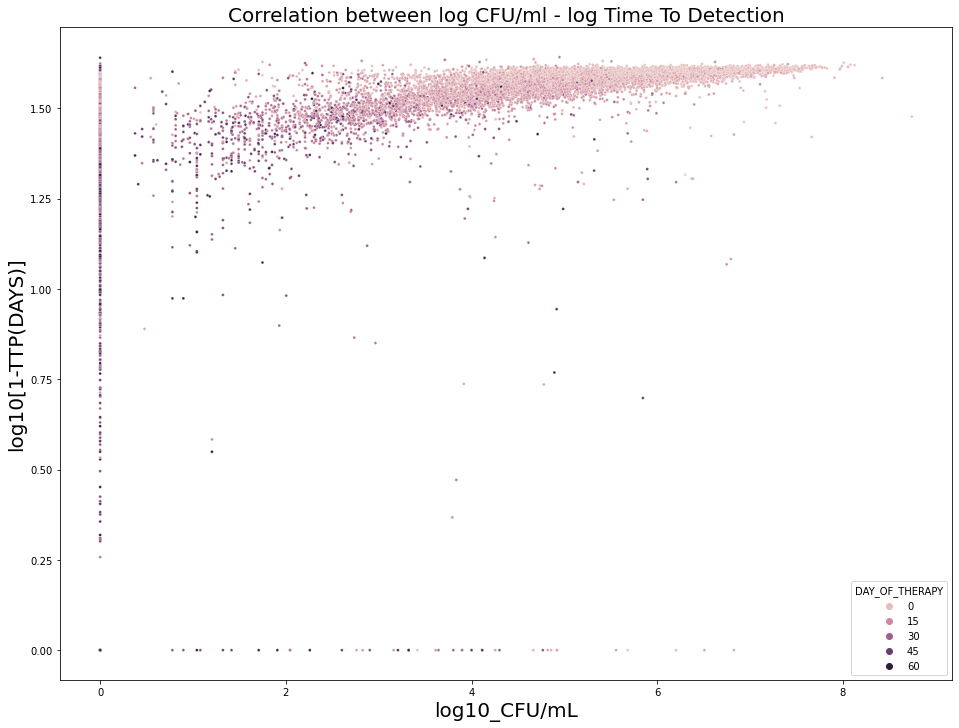

In [337]:
fig, (ax1) = plt.subplots(figsize=(16, 12))
sns.scatterplot(data=all_df, x='log10_CFU/mL',
                y='log10[1-TTP(DAYS)]', hue='DAY_OF_THERAPY', ax=ax1, s=8)
ax1.set_title('Correlation between log CFU/ml - log Time To Detection')
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=20)
# fig.savefig(dir+'figs/cfu-ttd_corr.png',dpi=150)


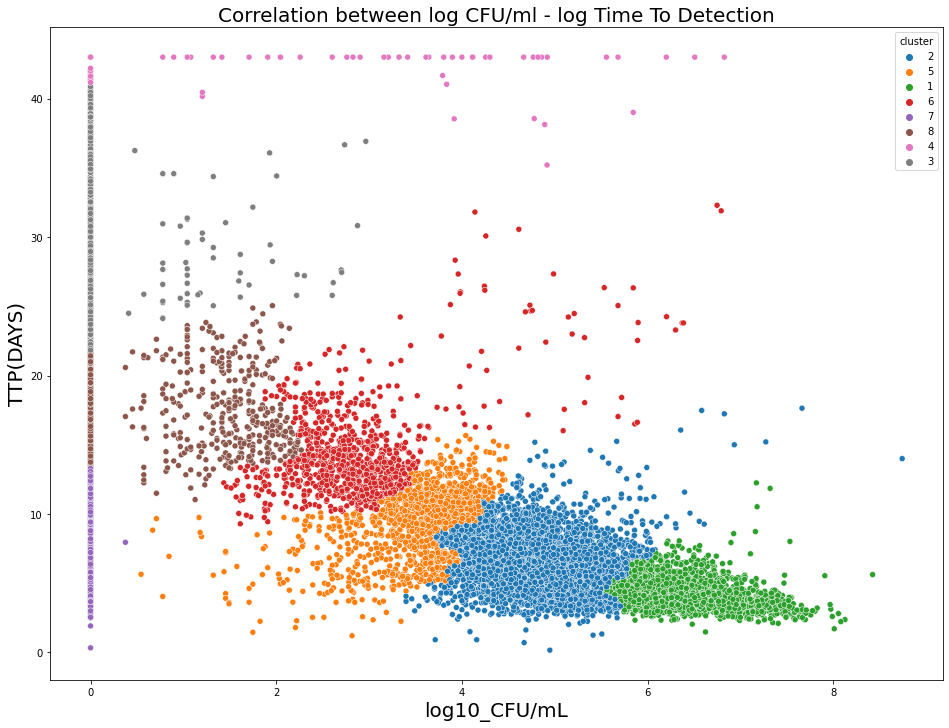

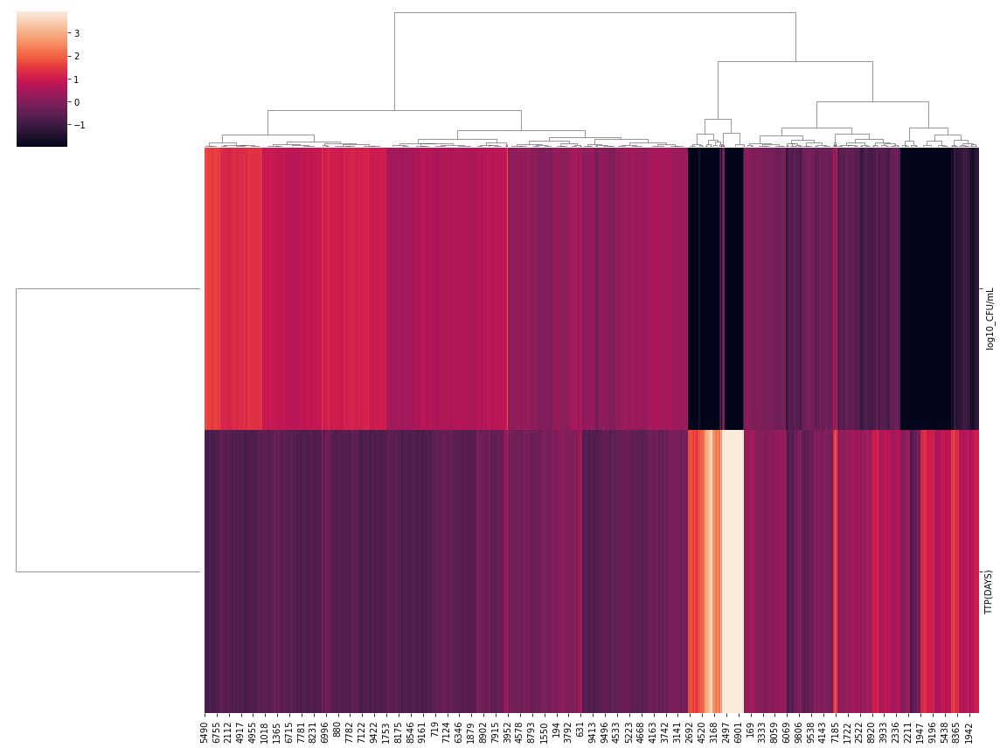

In [124]:
from scipy.stats import zscore
from sklearn.cluster import KMeans

fig, (ax1) = plt.subplots(figsize=(16, 12))
df = all_df.dropna()
sns.clustermap(data=df.loc[:, ['log10_CFU/mL', 'TTP(DAYS)']].T,
               figsize=(16, 12), method='ward', z_score=0)

# retrieve clusters using fcluster
d = sch.distance.pdist(df.loc[:, ['log10_CFU/mL', 'TTP(DAYS)']].apply(zscore))
L = sch.linkage(d, method='ward')
# 0.2 can be modified to retrieve more stringent or relaxed clusters
clusters = sch.fcluster(L, 8, 'maxclust')

kmeans = KMeans(n_clusters=6)
X = df.loc[:, ['log10_CFU/mL', 'TTP(DAYS)']].apply(zscore)
kmeans.fit(X)
# clusters=kmeans.labels_
df.loc[:, 'cluster'] = clusters
df.loc[:, 'cluster'] = df.loc[:, 'cluster'].astype(str)

sns.scatterplot(data=df, x='log10_CFU/mL',
                y='TTP(DAYS)', hue='cluster', ax=ax1)
ax1.set_title('Correlation between log CFU/ml - log Time To Detection')
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=20)
plt.show()


<hr>

* #### **Plot the TTP-CFU values from the same patient as scatterplots along the therapy days and fit a linear curve**

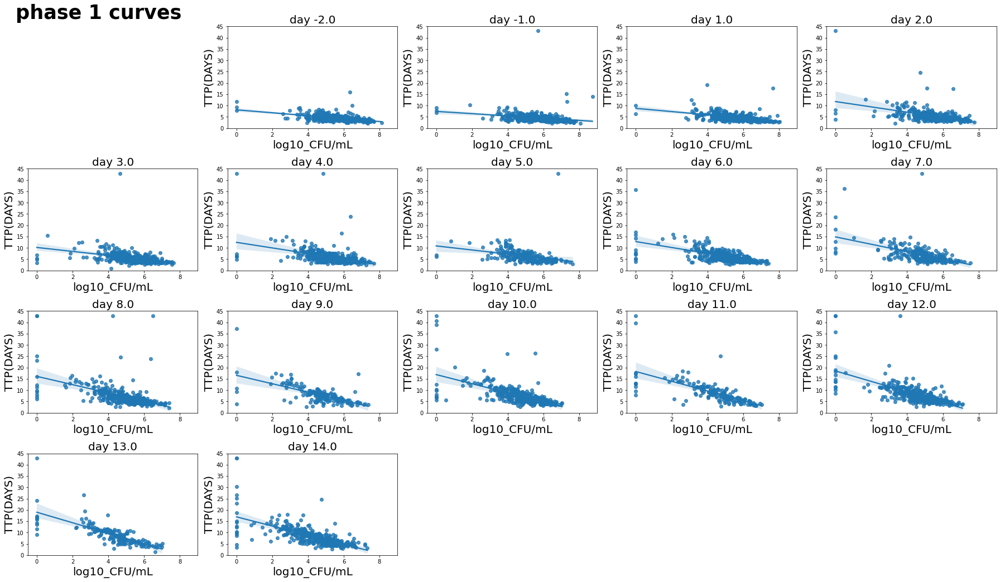

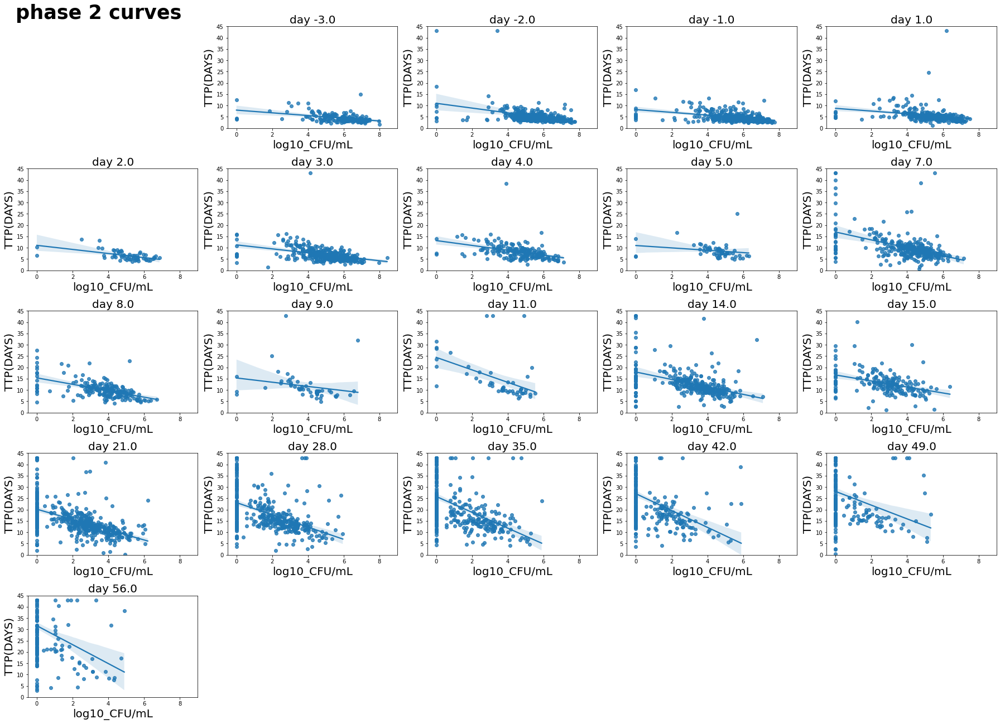

In [340]:
# set the day of measurement to 0 where the measurement was conductyed before therpay (=day 0) as a baseline
#all_df['DAY_OF_THERAPY_modified']=[0 if x<=0 else x for x in all_df['DAY_OF_THERAPY']]
all_df['DAY_OF_THERAPY_modified'] = all_df['DAY_OF_THERAPY']

# For Phase 2 studies, bin the days of measurement around the first day of therapy week
# (i.e. 3rd week: measurements from day 20, 21, 22 will be binned under day 21, until the 8th week (55,56,57 -> 56))
for week in range(3, 9):
    first_day = week*7.0
    df = all_df[(all_df['DAY_OF_THERAPY'] > (first_day-2)) &
                (all_df['DAY_OF_THERAPY'] < (first_day+2))]
    all_df.loc[df.index, 'DAY_OF_THERAPY_modified'] = first_day


for phase in [1, 2]:
    fig = plt.figure(figsize=(25, 25))
    fig.suptitle('phase '+str(phase)+' curves',
                 fontsize=35, weight='bold', x=0.1)
    a = 0
    phase_df = all_df[all_df['PHASE'] == phase]
    for n, day in enumerate(phase_df['DAY_OF_THERAPY_modified'].sort_values().unique()):
        d = phase_df[phase_df['DAY_OF_THERAPY_modified'] == day]
        d.loc[:, 'cfu_neg_ttp_pos'] = (
            d['log10_CFU/mL'] == 0) & (d['TTP(DAYS)'] < 43)
        if len(d) > 5:
            a = a+1
            ax1 = plt.subplot(7, 5, a+1)
            ax1.set_title('day '+str(day))
            ax1.set_ylim(0, 45)
            ax1.set_xlim(-0.5, 9)
            sns.regplot(data=d, x='log10_CFU/mL', y='TTP(DAYS)', ax=ax1)
            plt.tight_layout()


<hr>

* ##### Comparing the two methods: some points are isolated positive in TTP, some are isolated positive in CFU, and most of them have a concordant signal in both of the measurement methods.
* #####  Measurements that are isolated positive in TTP (=liquid) can pick up dormant bacterial subpopulations, that will not grow on CFU(= solid) medium. 
* ##### Hypothesis: With the progress of therapy, the active bacteria are killed, and the number of dormant bacteria grows in the sample -> the number of samples that are isolated positive in TTP should increase
* ##### **Add this information to the dataframe**

In [341]:

all_df.loc[:, 'cfu_neg_ttp_pos'] = (
    all_df['log10_CFU/mL'] == 0) & (all_df['TTP(DAYS)'] < 43)
all_df.loc[:, 'cfu_pos_ttp_neg'] = (
    all_df['log10_CFU/mL'] > 0) & (all_df['TTP(DAYS)'] == 43)
all_df.loc[:, 'cfu_pos_ttp_pos'] = (
    all_df['log10_CFU/mL'] > 0) & (all_df['TTP(DAYS)'] < 43)
all_df.loc[:, 'cfu_neg_ttp_neg'] = (
    all_df['log10_CFU/mL'] == 0) & (all_df['TTP(DAYS)'] == 43)

all_df.loc['mb_result'] = 0
all_df.loc[all_df['cfu_neg_ttp_pos'] == True,
           'mb_result'] = 'isolated TTP positive'
all_df.loc[all_df['cfu_pos_ttp_neg'] == True,
           'mb_result'] = 'isolated CFU positive'
all_df.loc[all_df['cfu_pos_ttp_pos'] ==
           True, 'mb_result'] = 'CFU & TTP positive'
all_df.loc[all_df['cfu_neg_ttp_neg'] ==
           True, 'mb_result'] = 'CFU & TTP negative'


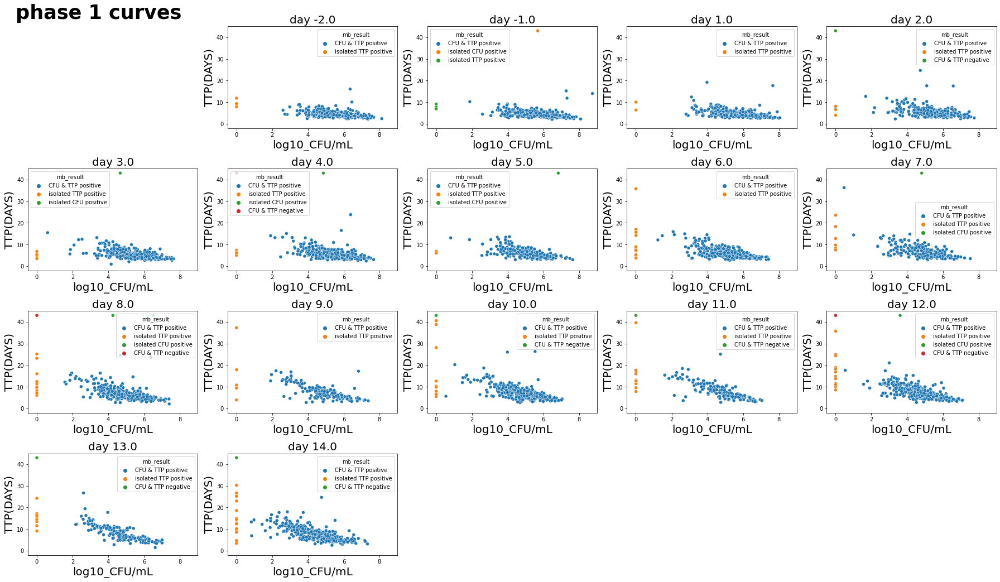

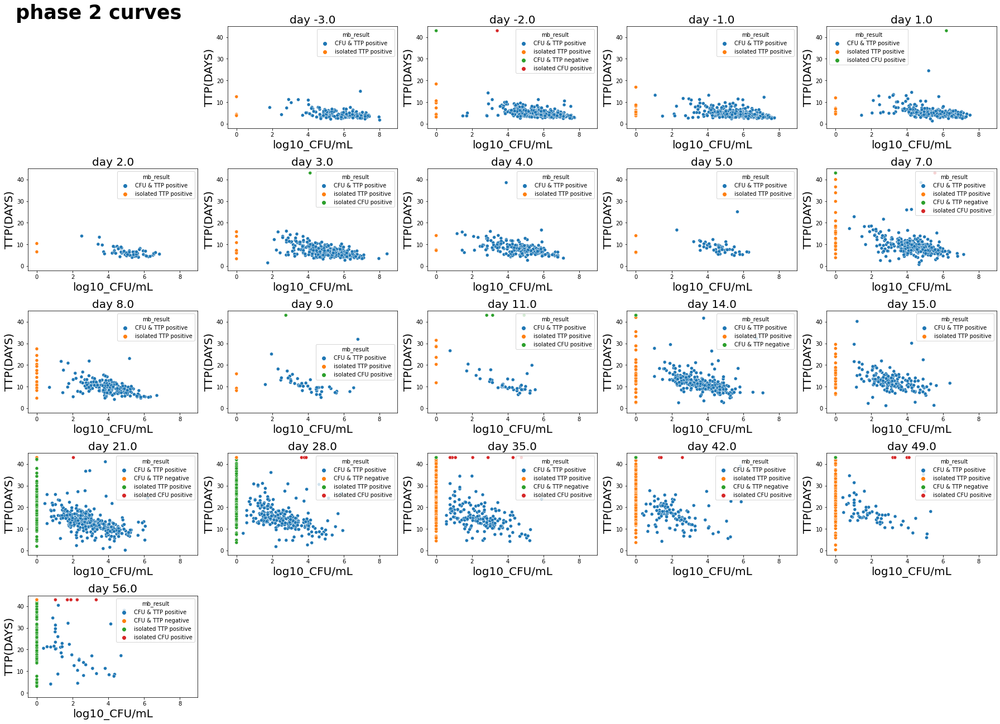

In [343]:

for phase in [1, 2]:
    fig = plt.figure(figsize=(25, 25))
    fig.suptitle('phase '+str(phase)+' curves',
                 fontsize=35, weight='bold', x=0.1)
    a = 0
    phase_df = all_df[all_df['PHASE'] == phase]
    for n, day in enumerate(phase_df['DAY_OF_THERAPY_modified'].sort_values().unique()):
        d = phase_df[phase_df['DAY_OF_THERAPY_modified'] == day]
        if len(d) > 5:
            a = a+1
            ax1 = plt.subplot(7, 5, a+1)
            ax1.set_title('day '+str(day))
            ax1.set_ylim(-2, 45)
            ax1.set_xlim(-0.5, 9)

            col_palette = ['red', 'orange', 'blue', 'grey']
            num_of_colors = len(d.loc[:, 'mb_result'].unique())
            # ,palette=col_palette[0:num_of_colors],legend=True)
            sns.scatterplot(data=d, x='log10_CFU/mL',
                            y='TTP(DAYS)', hue='mb_result', ax=ax1)
    #ttp_pos = mpatches.Patch(color='orange', label='isolated TTP positive')
    #cfu_pos = mpatches.Patch(color='blue', label='isolated CFU positive')
    #both_pos = mpatches.Patch(color='red', label='CFU & TTP positive')
    #both_neg = mpatches.Patch(color='grey', label='CFU & TTP negative')

    # fig.legend(handles=[ttp_pos,cfu_pos,both_pos,both_neg],loc=(0.05,0.85),fontsize=15)
    plt.tight_layout()


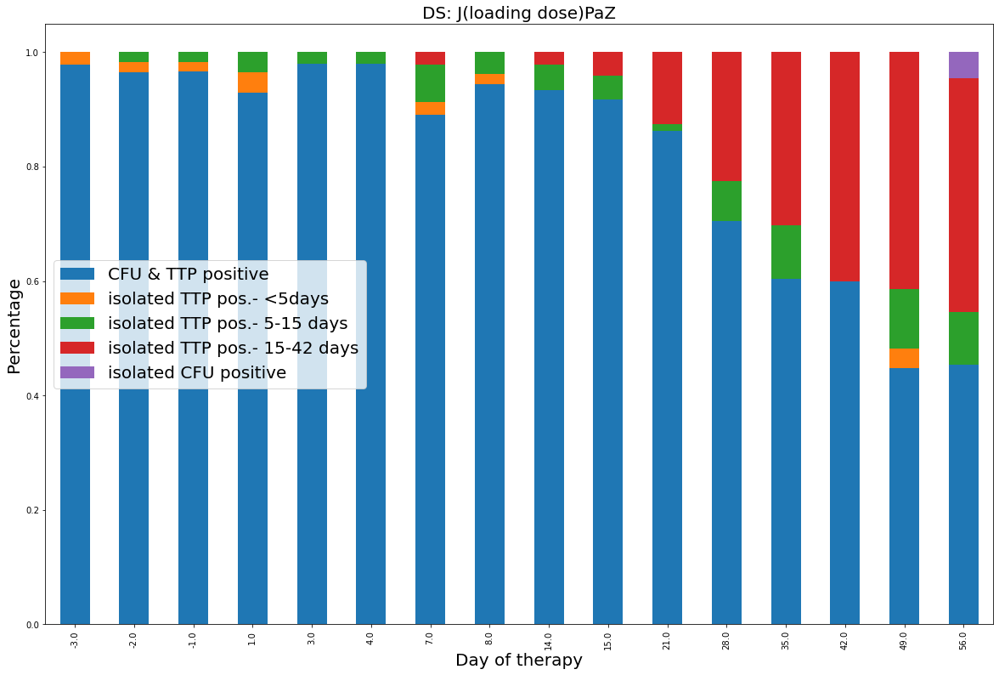

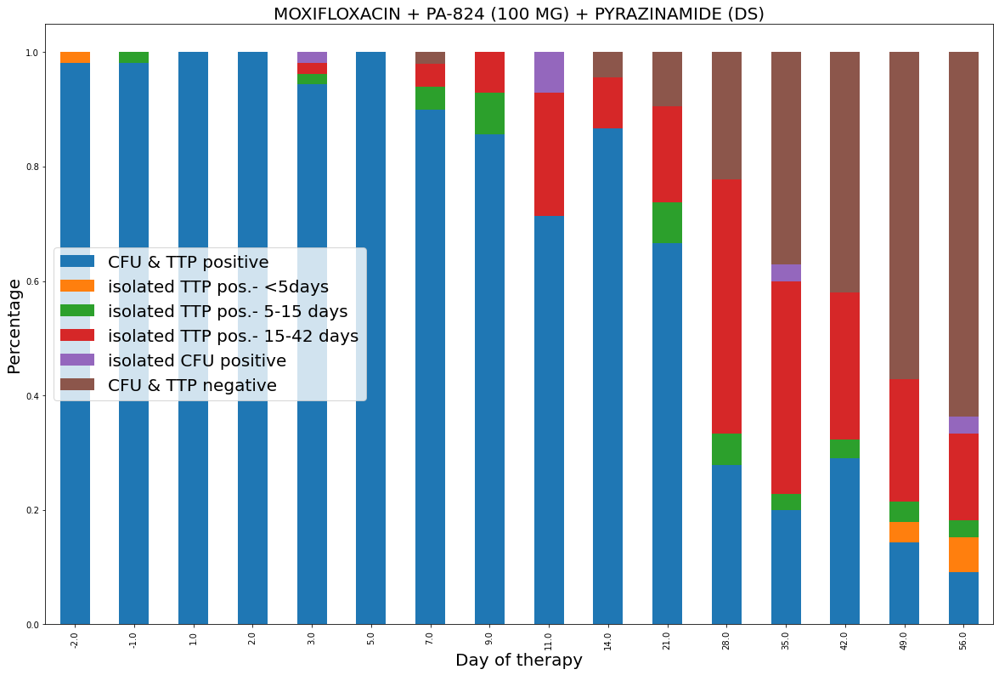

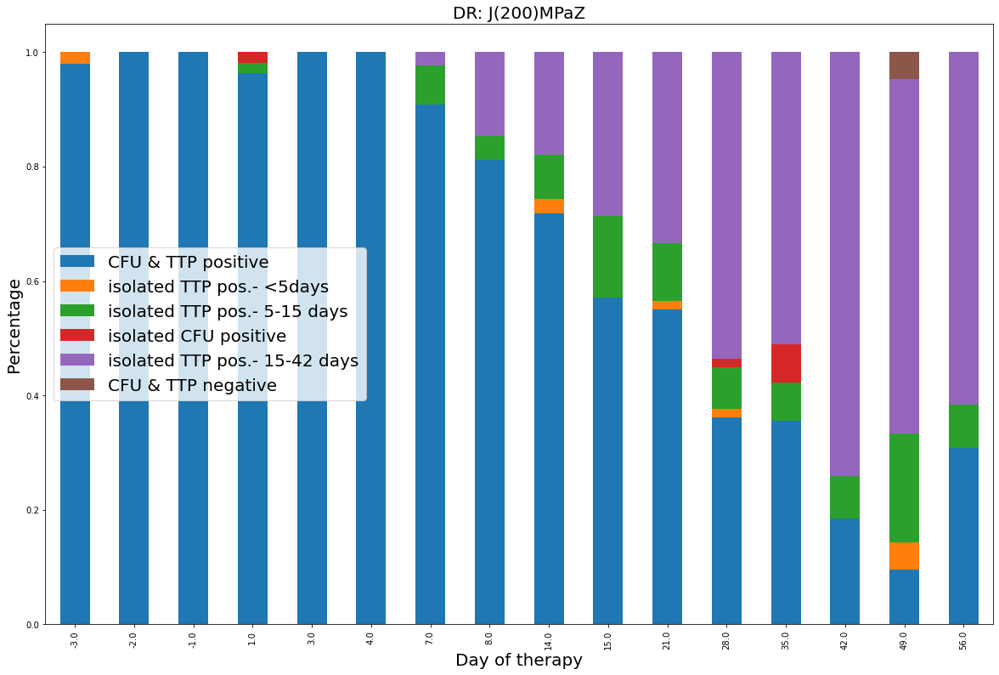

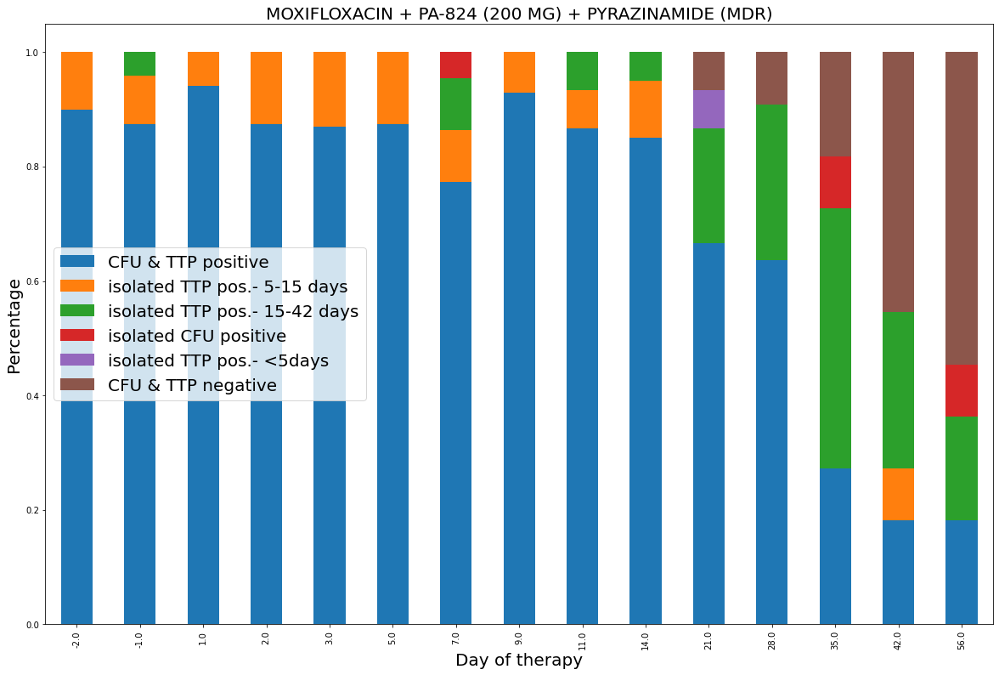

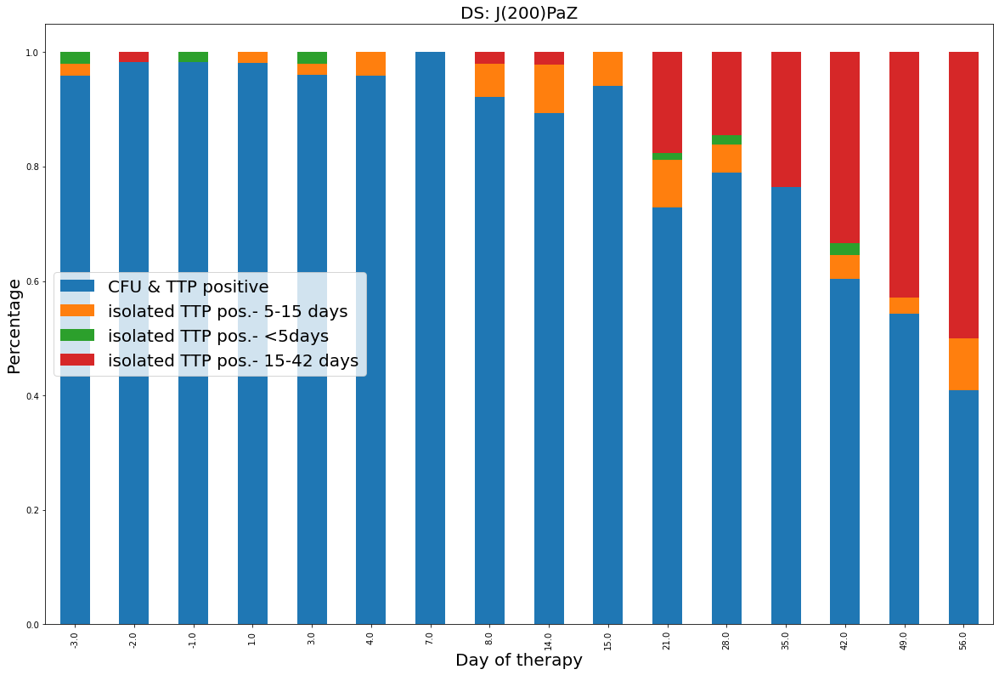

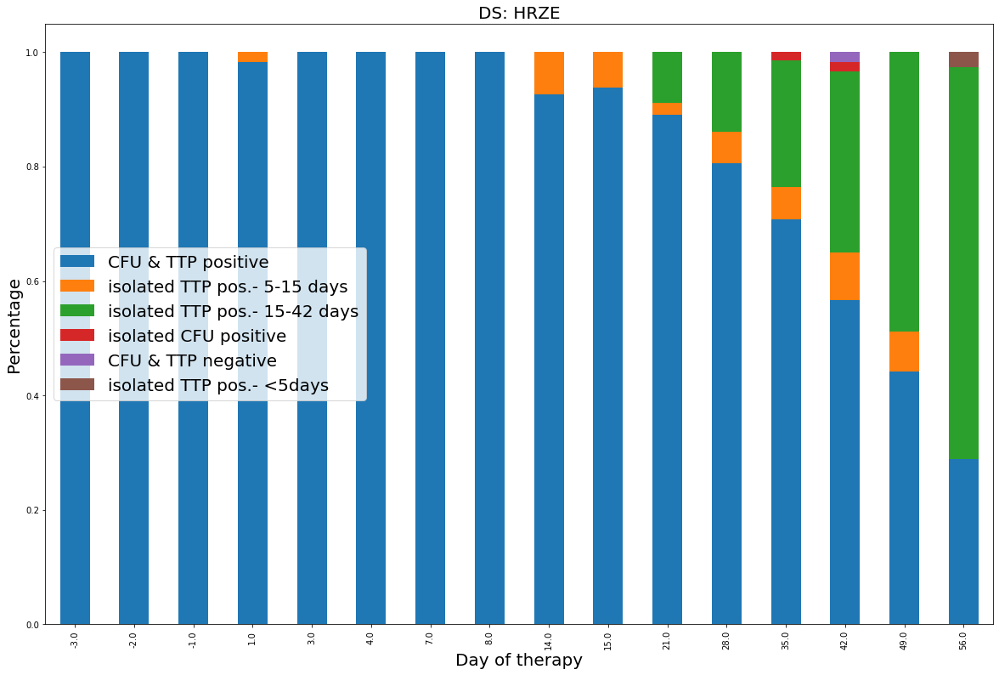

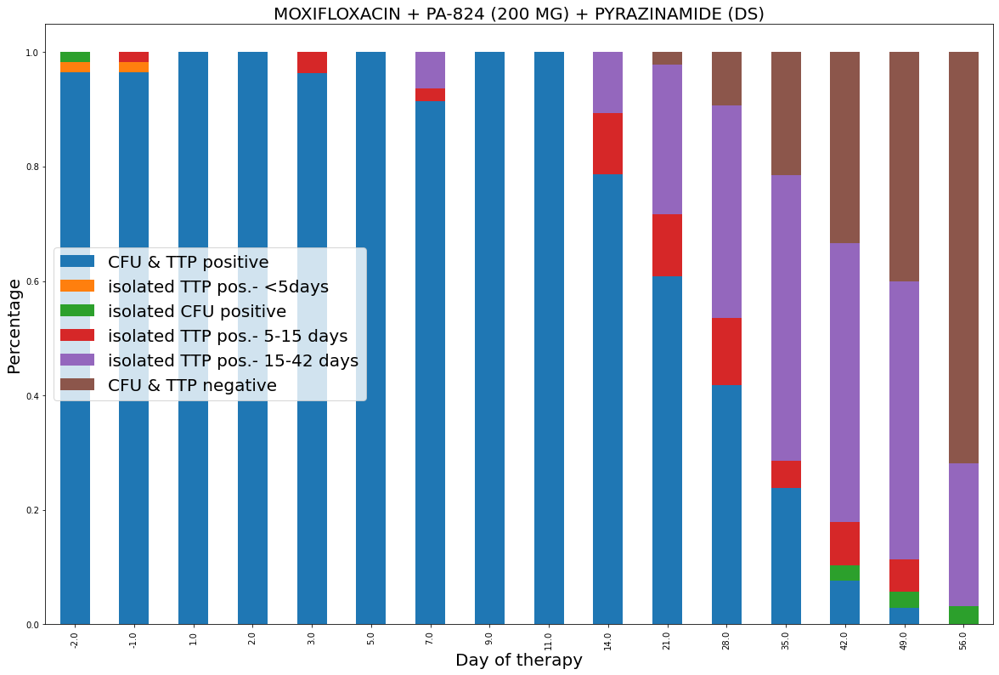

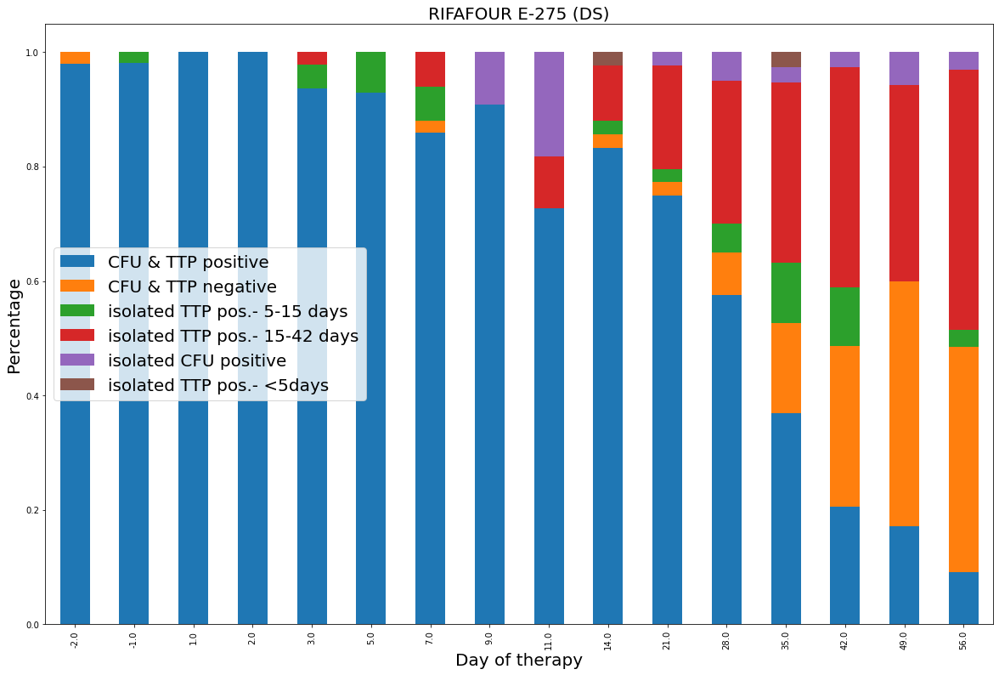

In [349]:
all_df.loc[(all_df['log10_CFU/mL'] == 0) & (all_df['TTP(DAYS)']
                                            < 5), 'mb_result'] = 'isolated TTP pos.- <5days'
all_df.loc[(all_df['log10_CFU/mL'] == 0) & (all_df['TTP(DAYS)'] >= 5) &
           (all_df['TTP(DAYS)'] < 15), 'mb_result'] = 'isolated TTP pos.- 5-15 days'
all_df.loc[(all_df['log10_CFU/mL'] == 0) & (all_df['TTP(DAYS)'] >= 15) &
           (all_df['TTP(DAYS)'] < 43), 'mb_result'] = 'isolated TTP pos.- 15-42 days'
a = 0
# dd=pd.DataFrame()
for phase in [2]:
    phase_df = all_df[all_df['PHASE'] == phase]
    for arm in phase_df['ARM'].unique():
        arm_df = phase_df[phase_df['ARM'] == arm]
        lis = []
        for n, day in enumerate(arm_df['DAY_OF_THERAPY_modified'].sort_values().unique()):
            d = arm_df[arm_df['DAY_OF_THERAPY_modified'] == day]
            if len(d) > 10:
                d_df = d['mb_result'].value_counts(normalize=True).to_frame()
                d_df.index = d_df.index.astype(str)
                d_df.columns = [str(day)]
                lis.append(d_df)

        dd = pd.concat(lis, axis=1)
        ddt = dd.T
        ddt['day_of_therapy'] = ddt.index
        #['isolated TTP positive','isolated CFU positive']
        ddt.loc[:, :].plot(kind='bar', stacked=True, figsize=(20, 13))
        ax = plt.gca()
        #ax.set_title('phase '+str(phase)+' studies')
        ax.set_title(arm)
        ax.set_ylabel('Percentage')
        ax.set_xlabel('Day of therapy')
        plt.legend(fontsize=20, loc='center left')

        # Plot correlation between mb result categories
        #fig, ax = plt.subplots(1,figsize=(9,9))
        #corr = ddt.corr(method='spearman')
        # sns.heatmap(corr,ax=ax,annot=True)


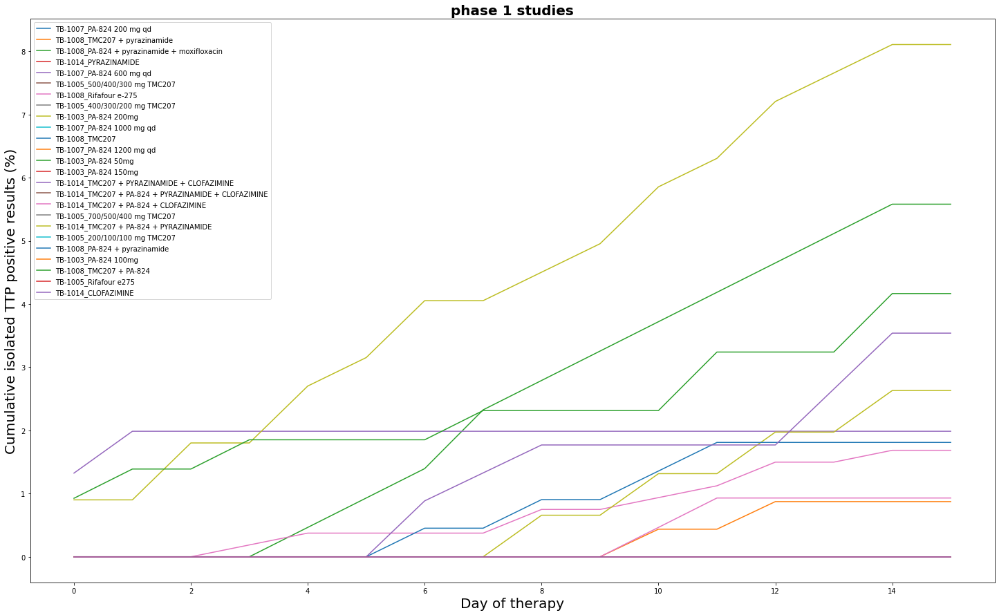

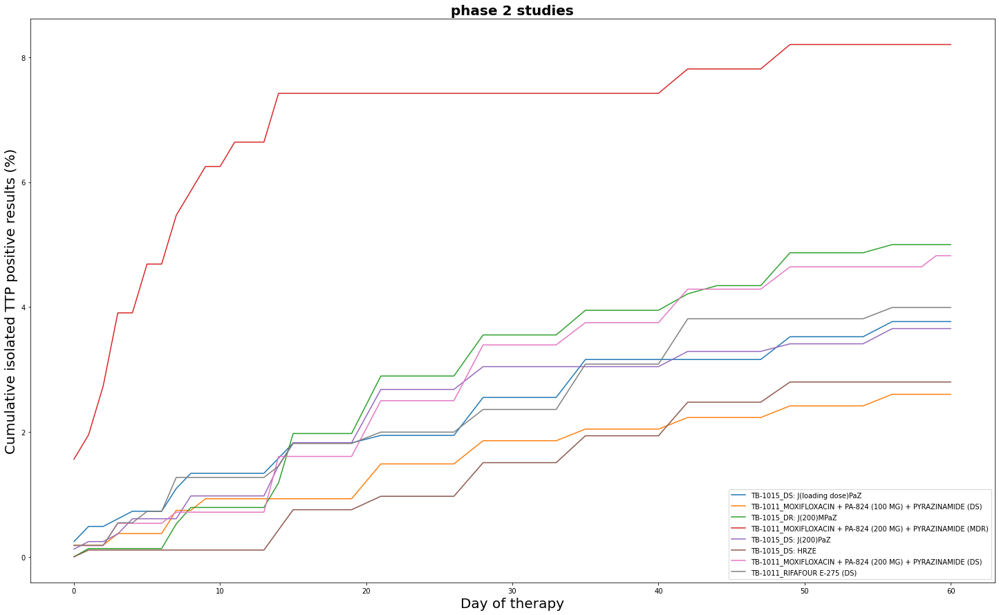

In [295]:
# add studyid before arm to make sure arm is unique
all_df['STUDYID_ARM'] = np.nan
all_df = all_df.reset_index()
all_df = all_df.drop(columns=['index'])
for arm in all_df['ARM'].unique():
    d = all_df[all_df['ARM'] == arm]
    all_df.loc[d.index, 'STUDYID_ARM'] = str(
        d['STUDYID'].values[0])+'_'+str(d['ARM'].values[0])

# set up dataframe to collect the increase in isolated ttp positive measurement points between
# day of therapy measurement timepoints
isolated_ttp_pos_over_time_diff = pd.DataFrame(0, index=all_df['DAY_OF_THERAPY_modified'].sort_values().unique(),
                                               columns=all_df['STUDYID_ARM'].unique())

for n, day in enumerate(all_df['DAY_OF_THERAPY_modified'].sort_values().unique()):
    d = all_df[all_df['DAY_OF_THERAPY_modified'] == day]
    # df_ttp_pos=d[d['cfu_neg_ttp_pos']==True]
    #df_ttp_pos=d[d['mb_result'].str.contains('isolated TTP pos.- <5days|isolated TTP pos.- 5-15 days',na=False)]
    df_ttp_pos = d[d['mb_result'].str.contains(
        'isolated TTP pos.- 5-15 days', na=False)]
    ttp_pos_arms = df_ttp_pos['STUDYID_ARM'].value_counts(dropna=False)
    for coln in isolated_ttp_pos_over_time_diff.columns:
        if coln in ttp_pos_arms.index:
            isolated_ttp_pos_over_time_diff.loc[day,
                                                coln] = isolated_ttp_pos_over_time_diff.loc[day, coln] + ttp_pos_arms[coln]
        if coln in ttp_pos_arms.index:
            isolated_ttp_pos_over_time_diff.loc[day,
                                                coln] = isolated_ttp_pos_over_time_diff.loc[day, coln]

# get cumulative increase of numbers of isolated ttp positive samples
isolated_ttp_pos_over_time_cumul = isolated_ttp_pos_over_time_diff.cumsum()

# normalize cumulative numbers with measured sample number per arm
# fig,ax=plt.subplots(1,figsize=(25,15))
for phase in [1, 2]:
    phase_df = all_df[all_df['PHASE'] == phase]
    phase_arms = phase_df['STUDYID_ARM'].unique()
    fig, ax = plt.subplots(1, figsize=(25, 15))
    for arm in phase_arms:
        num_of_meas_in_arm = len(all_df[all_df['STUDYID_ARM'] == arm])
        isolated_ttp_pos_over_time_cumul[arm] = isolated_ttp_pos_over_time_cumul[arm] / \
            num_of_meas_in_arm*100
        if phase == 1:
            stop_day = 15
        if phase == 2:
            stop_day = max(isolated_ttp_pos_over_time_cumul.index)
        plot_df = isolated_ttp_pos_over_time_cumul.loc[0:stop_day, :]
        sns.lineplot(x=plot_df.index, y=plot_df[arm], ax=ax, label=arm)

        ax.set_title('phase '+str(phase)+' studies', weight='bold')
        ax.set_ylabel('Cumulative isolated TTP positive results (%)')
        ax.set_xlabel('Day of therapy')


<hr>

* #### Add time to negativity data (TTN) to all_df
* #### Consider patients with negative TB results with BOTH CFU and TTP at the last day of therapy + initial positive TB result at Day 0->  **add day of therapy as TTN day, where patient reached negativity first**

In [255]:

all_df['time_to_negativity'] = np.nan
all_df['last_known_positivity'] = [
    14 if all_df.loc[x, 'PHASE'] == 1 else 56 for x in all_df.index]

for pat_id in all_df['SUBJECT_ID'].unique():
    pat_df = all_df[all_df['SUBJECT_ID'] == pat_id]
    pat_df = pat_df.sort_values(by=['DAY_OF_THERAPY'])

    # Add time to negativity data (TTN) to all_df
    # Consider patients with negative TB results with BOTH CFU and TTP at the last day of therapy + initial positive TB result at Day 0->
    # add day of therapy as TTN day, where patient reached negativity first
    if all(x == 'CFU & TTP negative' for x in pat_df.loc[pat_df.index[-1:], 'mb_result'].tolist()) & \
            ~(pat_df.loc[pat_df.index[0], 'mb_result'] == 'CFU & TTP negative'):
        neg_df = pat_df[pat_df['mb_result'] == 'CFU & TTP negative'].sort_values(by=[
                                                                                 'DAY_OF_THERAPY'])
        if len(neg_df) > 0:
            ttn = neg_df.loc[:, 'DAY_OF_THERAPY_modified'].values[0]
            all_df.loc[pat_df.index, 'time_to_negativity'] = ttn


#### KAPLAN MEIER ANALYSIS OF TIME TO NEGATIVITY
* #### EVENT IS THE TIME TO THE FIRST NEGATIVE TEST RESULT (WITH BOTH TTP & CFU!)
* #### COMPARE ARMS TO THE RIFAFOUR ARM

In [ ]:
import math
from lifelines import KaplanMeierFitter
kaplan_meier = all_df.loc[:, :].drop_duplicates(
    subset=['SUBJECT_ID'], keep='last')
kaplan_meier = kaplan_meier.loc[:, [
    'time_to_negativity', 'last_known_positivity', 'ARM', 'PHASE']]
kaplan_meier['event'] = [0 if np.isnan(
    kaplan_meier.loc[x, 'time_to_negativity']) else 1 for x in kaplan_meier.index]
kaplan_meier.loc[kaplan_meier['time_to_negativity'].isna(
), 'time_to_negativity'] = kaplan_meier.loc[kaplan_meier['time_to_negativity'].isna(), 'last_known_positivity']

kmf = KaplanMeierFitter()

print(kaplan_meier[(kaplan_meier['PHASE'] == 2) & (
    kaplan_meier['event'] == 1)]['ARM'].value_counts())

for phase in [2]:
    n = 0
    # fig,ax=plt.subplots(1,figsize=(25,15))
    km_phase_df = kaplan_meier[kaplan_meier['PHASE'] == phase]
    nrows = math.ceil(len(km_phase_df['ARM'].unique()))
    print(nrows)
    for arm in km_phase_df['ARM'].unique():
        if arm != 'RIFAFOUR E-275 (DS)':
            ax = plt.subplot(nrows, 2, n + 1)
            ax.set_ylim(0.5, 1.1)
            n = n+1
            plot_df = km_phase_df[km_phase_df['ARM'] == arm]
            kmf.fit(plot_df["time_to_negativity"], plot_df["event"], label=arm)
            kmf.plot(ax=ax, ci_show=True, figsize=(15, 35))

            control_df = km_phase_df[km_phase_df['ARM']
                                     == 'RIFAFOUR E-275 (DS)']
            kmf.fit(control_df["time_to_negativity"],
                    control_df["event"], label='RIFAFOUR E-275 (DS)')
            kmf.plot(ax=ax, ci_show=True, figsize=(15, 35))
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression

all_df['14_days_slope_pat'] = np.nan
all_df['15_56_days_slope_pat'] = np.nan

for pat_id in all_df['SUBJECT_ID'].unique():
    pat_df = all_df[all_df['SUBJECT_ID'] == pat_id]
    pat_df = pat_df.sort_values(by=['DAY_OF_THERAPY'])

    # Split data into first 14 days (EBA) vs. 15-56 days of therapy.
    # Fit linear model to these TTP datapoints (only datapoints where TTP&CFU are consistent!!!!) + add slope information to all_df
    # 1. EBA (1-14 days of therapy)
    pat_df_14_days = pat_df[(pat_df['DAY_OF_THERAPY'] < 15) & (
        ~pat_df['mb_result'].str.contains('isolated', na=False))]
    if len(pat_df_14_days) > 0:
        lm_14_days = LinearRegression().fit(pat_df_14_days['DAY_OF_THERAPY'].values.reshape(
            (-1, 1)), pat_df_14_days['log10[1-TTP(DAYS)]'])
        all_df.loc[pat_df.index, '14_days_slope_pat'] = [
            lm_14_days.coef_]*len(pat_df.index)

    # 2.If datapoint is from PHASE 2, fit linear model to TTP (15-56 days)
    if pat_df['PHASE'].values[0] != 1:
        # &(~pat_df['mb_result'].str.contains('isolated',na=False))]
        pat_df_56_days = pat_df[(pat_df['DAY_OF_THERAPY'] > 14)]
        if len(pat_df_56_days) > 1:
            lm_15_56_days = LinearRegression().fit(pat_df_56_days['DAY_OF_THERAPY'].values.reshape(
                (-1, 1)), pat_df_56_days['log10[1-TTP(DAYS)]'])
            all_df.loc[pat_df.index, '15_56_days_slope_pat'] = [
                lm_15_56_days.coef_]*len(pat_df.index)
            # fig,ax=plt.subplots()
            # sns.regplot(data=pat_df_56_days,x='DAY_OF_THERAPY',y='log10[1-TTP(DAYS)]',ax=ax)


AttributeError: 'function' object has no attribute 'shape'

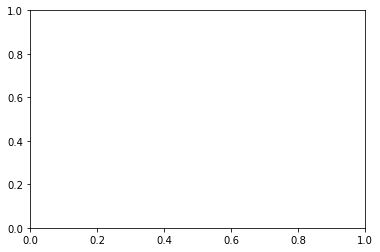

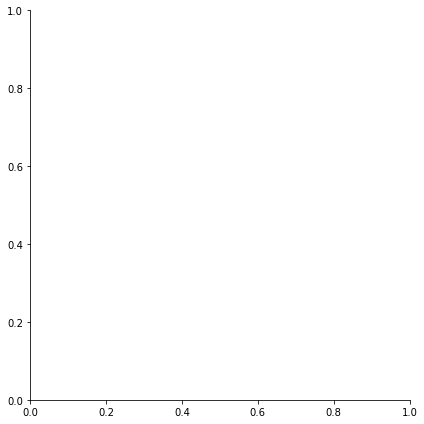

In [325]:
all_df['14_days_slope_arm'] = np.nan
all_df['15_56_days_slope_arm'] = np.nan

for arm in all_df['ARM'].unique():
    arm_df = all_df[all_df['ARM'] == arm]
    arm_df = arm_df.sort_values(by=['DAY_OF_THERAPY'])

    # Split data into first 14 days (EBA) vs. 15-56 days of therapy.
    # Fit linear model to these TTP datapoints (only datapoints where TTP&CFU are consistent!!!!) + add slope information to all_df
    # 1. EBA (1-14 days of therapy)
    arm_df_14_days = arm_df[(arm_df['DAY_OF_THERAPY'] < 15) & (
        ~arm_df['mb_result'].str.contains('isolated', na=False))]
    if len(arm_df_14_days) > 0:
        lm_14_days = LinearRegression().fit(arm_df_14_days['DAY_OF_THERAPY'].values.reshape(
            (-1, 1)), arm_df_14_days['log10[1-TTP(DAYS)]'])
        all_df.loc[pat_df.index, '14_days_slope'] = [
            lm_14_days.coef_]*len(pat_df.index)
        #g = sns.FacetGrid(data=arm_df_14_days,row='ARM',height=6)
        # g.map_dataframe(sns.lmplot,x='DAY_OF_THERAPY',y='1-TTP(DAYS)')#,hue='SUBJECT_ID')
        # sns.lmplot(data=arm_df_14_days,x='DAY_OF_THERAPY',y='1-TTP(DAYS)',hue='SUBJECT_ID')

    # 2.If datapoint is from PHASE 2, fit linear model to TTP (15-56 days)
    if arm_df['PHASE'].values[0] != 1:
        # &(~pat_df['mb_result'].str.contains('isolated',na=False))]
        arm_df_56_days = arm_df[(arm_df['DAY_OF_THERAPY'] > 14)]
        # print(arm_df_56_days[['DAY_OF_THERAPY','log10[1-TTP(DAYS)]']])
        if len(arm_df_56_days) > 1:
            lm_15_56_days = LinearRegression().fit(arm_df_56_days['DAY_OF_THERAPY'].values.reshape(
                (-1, 1)), arm_df_56_days['log10[1-TTP(DAYS)]'])
            all_df.loc[pat_df.index, '15_56_days_slope'] = [
                lm_15_56_days.coef_]*len(pat_df.index)
            fig, ax = plt.subplots()
            g = sns.FacetGrid(data=arm_df_56_days, row='ARM', height=6)
            # ,hue='SUBJECT_ID')
            g.map_dataframe(sns.regplot, sns.histplot,
                            x='DAY_OF_THERAPY', y='1-TTP(DAYS)')
            # sns.regplot(data=arm_df_56_days,x='DAY_OF_THERAPY',y='log10[1-TTP(DAYS)]',ax=ax)
            # ax.set_title(arm)
            # sns.lmplot(data=arm_df_56_days,x='DAY_OF_THERAPY',y='1-TTP(DAYS)',hue='SUBJECT_ID')
            # ax=plt.gca()
            # ax.set_ylim(0,45)


In [ ]:
slopes_df = all_df.loc[:, :].drop_duplicates(
    subset=['SUBJECT_ID'], keep='last')
slopes_df = slopes_df.loc[:, ['SUBJECT_ID', '14_days_slope', '15_56_days_slope',
                              'time_to_negativity', 'last_known_positivity', 'ARM', 'PHASE']]
slopes_df['event'] = [0 if np.isnan(
    slopes_df.loc[x, 'time_to_negativity']) else 1 for x in slopes_df.index]
for phase in [1, 2]:
    # fig,ax=plt.subplots(1,figsize=(25,15))
    phase_slope_df = slopes_df[slopes_df['PHASE'] == phase]
    g = sns.FacetGrid(data=phase_slope_df, col='ARM', col_wrap=4, height=6)
    g.map_dataframe(sns.histplot, x='14_days_slope')
    # sns.histplot(data=phase_slope_df,x='14_days_slope',hue='ARM',ax=ax)
    plt.tight_layout()
    if phase == 2:
        # fig,ax1=plt.subplots(1,figsize=(25,15))
        # sns.histplot(data=phase_slope_df,x='15_56_days_slope',hue='ARM',ax=ax1)
        g = sns.FacetGrid(data=phase_slope_df, col='ARM', col_wrap=4, height=6)
        g.map_dataframe(sns.histplot, x='15_56_days_slope')
    # for arm in phase_slope_df['ARM'].unique():

fig, ax = plt.subplots(1, figsize=(15, 10))
sns.scatterplot(data=slopes_df[slopes_df['PHASE'] == 2],
                x='14_days_slope', y='15_56_days_slope', hue='ARM', ax=ax)
